# Customer Segmentation for Marketing Campaign Strategy

This notebook builds a customer segmentation analysis using unsupervised learning.

The objective is to group customers based on purchasing behaviour and translate the segments into practical marketing actions: retention, cross-selling, reactivation, and budget allocation.

Workflow:

1. Load and inspect the customer marketing dataset
2. Clean the data and create customer-level features
3. Build a behavioural modelling dataset
4. Scale the features and transform them with PCA
5. Fit and compare clustering models
6. Profile the final segments and convert them into business actions


------------------------------
## **Data Dictionary**
------------------------------

The dataset contains the following features:

1. ID: Unique ID of each customer
2. Year_Birth: Customer’s year of birth
3. Education: Customer's level of education
4. Marital_Status: Customer's marital status
5. Kidhome: Number of small children in customer's household
6. Teenhome: Number of teenagers in customer's household
7. Income: Customer's yearly household income in USD
8. Recency: Number of days since the last purchase
9. Dt_Customer: Date of customer's enrollment with the company
10. MntFishProducts: The amount spent on fish products in the last 2 years
11. MntMeatProducts: The amount spent on meat products in the last 2 years
12. MntFruits: The amount spent on fruits products in the last 2 years
13. MntSweetProducts: Amount spent on sweet products in the last 2 years
14. MntWines: The amount spent on wine products in the last 2 years
15. MntGoldProds: The amount spent on gold products in the last 2 years
16. NumDealsPurchases: Number of purchases made with discount
17. NumCatalogPurchases: Number of purchases made using a catalog (buying goods to be shipped through the mail)
18. NumStorePurchases: Number of purchases made directly in stores
19. NumWebPurchases: Number of purchases made through the company's website
20. NumWebVisitsMonth: Number of visits to the company's website in the last month
21. AcceptedCmp1: 1 if customer accepted the offer in the first campaign, 0 otherwise
22. AcceptedCmp2: 1 if customer accepted the offer in the second campaign, 0 otherwise
23. AcceptedCmp3: 1 if customer accepted the offer in the third campaign, 0 otherwise
24. AcceptedCmp4: 1 if customer accepted the offer in the fourth campaign, 0 otherwise
25. AcceptedCmp5: 1 if customer accepted the offer in the fifth campaign, 0 otherwise
26. Response: 1 if customer accepted the offer in the last campaign, 0 otherwise
27. Complain: 1 If the customer complained in the last 2 years, 0 otherwise

**Note:** You can assume that the data is collected in the year 2016.

## 1. Imports and configuration

The notebook uses common Python libraries for data preparation, visualization, dimensionality reduction, clustering, and model evaluation.

In [1]:
from pathlib import Path
import math
import os
import warnings

# Avoid Windows / joblib CPU detection warnings in some sklearn models.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
os.environ.setdefault("OMP_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN,
    OPTICS,
    Birch,
    SpectralClustering,
)

# BisectingKMeans is not available in some older scikit-learn versions.
# The notebook keeps it as an optional benchmark, so the rest of the project can run.
try:
    from sklearn.cluster import BisectingKMeans
    BISECTING_KMEANS_AVAILABLE = True
except ImportError:
    BISECTING_KMEANS_AVAILABLE = False
    print("Bisecting K-Means skipped. Upgrade scikit-learn to run this optional benchmark.")
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 1

pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Load the data

The dataset file can sit either in the project folder or in a `data/` folder. The loader below also handles the common CSV, tab-separated, and semicolon-separated versions of this dataset.


In [2]:
def find_dataset_path() -> Path:
    candidate_paths = [
        Path("marketing_campaign.csv"),
        Path("data/marketing_campaign.csv"),
        Path("../data/marketing_campaign.csv"),
        Path("/mnt/data/marketing_campaign.csv"),
    ]

    for candidate in candidate_paths:
        if candidate.exists():
            return candidate

    matches = list(Path(".").rglob("*campaign*.csv"))
    if matches:
        return matches[0]

    raise FileNotFoundError(
        "Dataset not found. Put marketing_campaign.csv in the notebook folder "
        "or in a data/ subfolder."
    )


def load_customer_data(path: Path) -> pd.DataFrame:
    for sep in [None, "\t", ";", ","]:
        try:
            df = pd.read_csv(path, sep=sep, engine="python")
            if df.shape[1] > 1:
                return df
        except Exception:
            continue

    raise ValueError(f"Could not read {path}. Check the file delimiter or encoding.")


DATA_PATH = find_dataset_path()
raw_data = load_customer_data(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Dataset shape: {raw_data.shape}")
raw_data.head()


Loaded: Unsupervised Learning\marketing_campaign.csv
Dataset shape: (2240, 27)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,"26,646.00",1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,"58,293.00",1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0


## 3. Initial data understanding

This section checks the structure of the dataset, missing values, duplicate rows, categorical values, and basic numerical summaries.

The goal is to understand data quality before building segmentation features.

In [3]:
# Basic structure
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
# Missing value summary
missing_summary = pd.DataFrame({
    "missing_count": raw_data.isnull().sum(),
    "missing_percent": raw_data.isnull().mean() * 100
}).sort_values("missing_percent", ascending=False)

missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_percent
Income,24,1.07


In [5]:
# Duplicate check
print(f"Number of duplicate rows: {raw_data.duplicated().sum()}")

Number of duplicate rows: 0


In [6]:
# Review categorical variables when present
categorical_columns = [col for col in ["Education", "Marital_Status"] if col in raw_data.columns]

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(raw_data[col].value_counts(dropna=False))


Unique values in Education:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Unique values in Marital_Status:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [7]:
# Numerical summary for main variables
raw_data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"2,240.00","5,592.16","3,246.66",0.00,"2,828.25","5,458.50","8,427.75","11,191.00"
Year_Birth,"2,240.00","1,968.81",11.98,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00"
Income,"2,216.00","52,247.25","25,173.08","1,730.00","35,303.00","51,381.50","68,522.00","666,666.00"
Kidhome,"2,240.00",0.44,0.54,0.00,0.00,0.00,1.00,2.00
Teenhome,"2,240.00",0.51,0.54,0.00,0.00,0.00,1.00,2.00
Recency,"2,240.00",49.11,28.96,0.00,24.00,49.00,74.00,99.00
MntWines,"2,240.00",303.94,336.60,0.00,23.75,173.50,504.25,"1,493.00"
MntFruits,"2,240.00",26.30,39.77,0.00,1.00,8.00,33.00,199.00
MntMeatProducts,"2,240.00",166.95,225.72,0.00,16.00,67.00,232.00,"1,725.00"
MntFishProducts,"2,240.00",37.53,54.63,0.00,3.00,12.00,50.00,259.00


### Initial insights

- Customer spending variables are usually right-skewed: many customers spend little, while a smaller group spends heavily.
- Income may contain a small number of missing values and occasional extreme values.
- Some categorical labels in marital status are rare or unusual and should be grouped into broader business-friendly categories.
- Product spending and purchase-count variables are expected to be correlated, which is one reason PCA is useful later.

## 4. Exploratory analysis

The following plots help understand income, product spending, purchase behaviour, and relationships between customer value variables.

In [8]:
SPEND_COLUMNS = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]

PURCHASE_COLUMNS = [
    "NumDealsPurchases", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases"
]

CAMPAIGN_COLUMNS = [
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
    "AcceptedCmp4", "AcceptedCmp5", "Response"
]

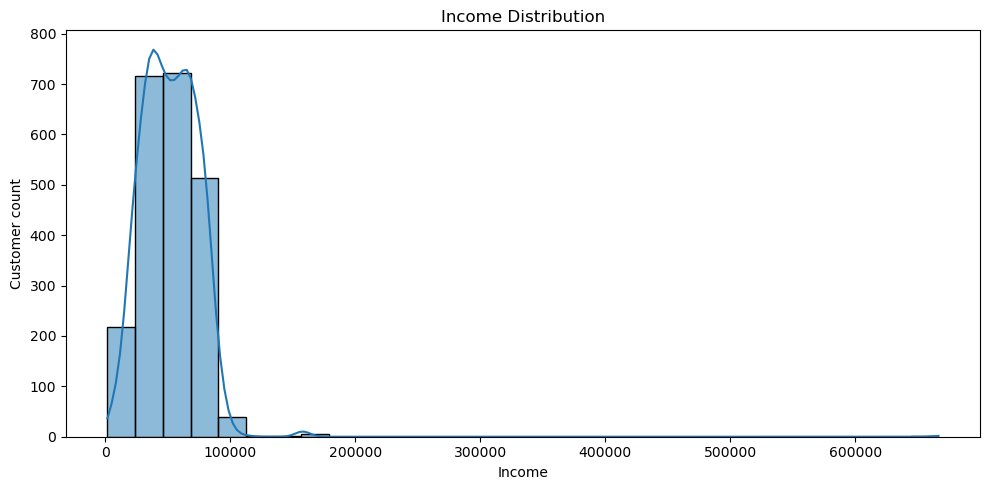

In [9]:
# Income distribution
if "Income" in raw_data.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(raw_data["Income"], bins=30, kde=True)
    plt.title("Income Distribution")
    plt.xlabel("Income")
    plt.ylabel("Customer count")
    plt.tight_layout()
    plt.show()

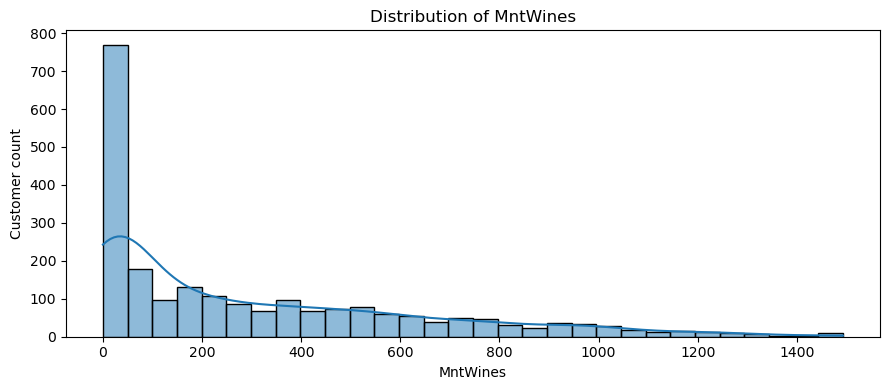

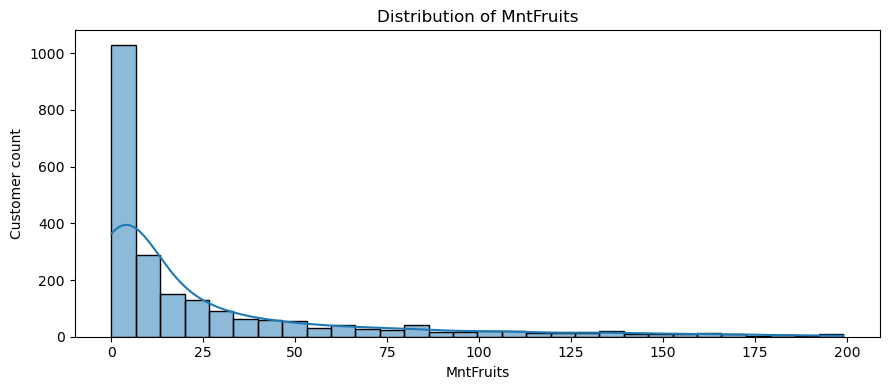

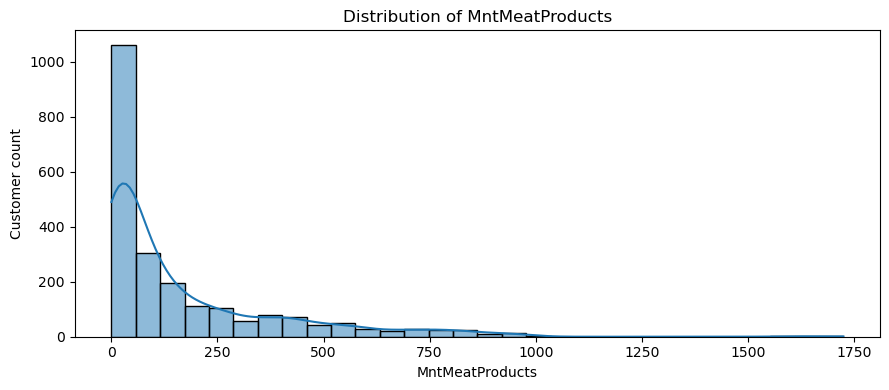

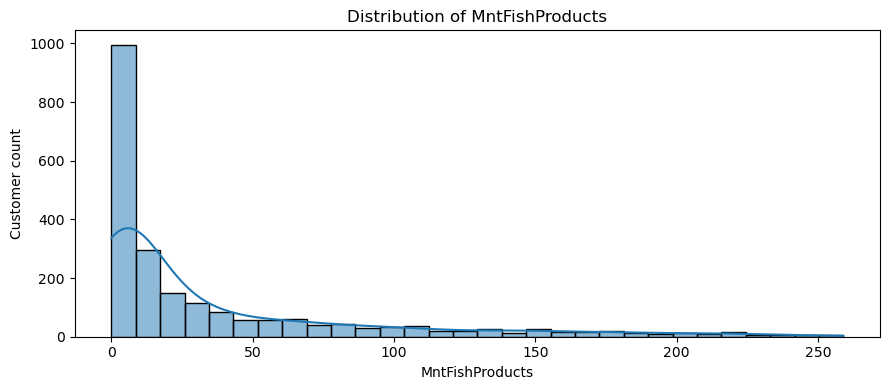

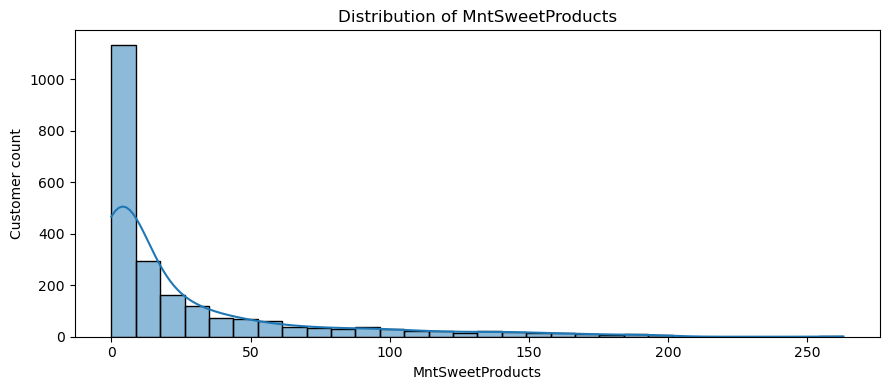

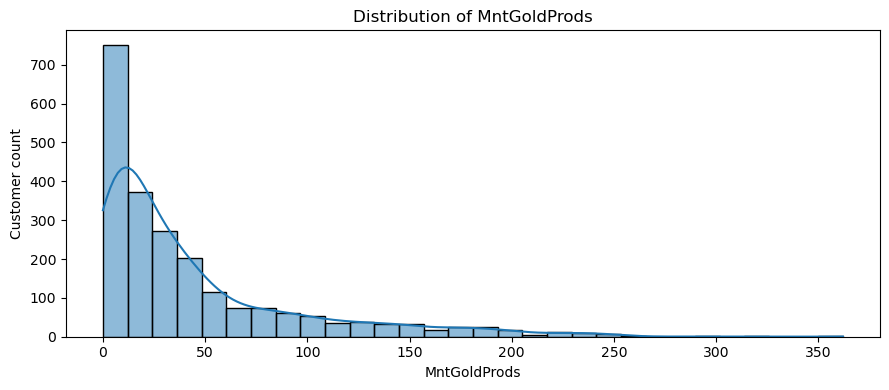

In [10]:
# Spending distributions by product category
available_spend_columns = [col for col in SPEND_COLUMNS if col in raw_data.columns]

for col in available_spend_columns:
    plt.figure(figsize=(9, 4))
    sns.histplot(raw_data[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer count")
    plt.tight_layout()
    plt.show()

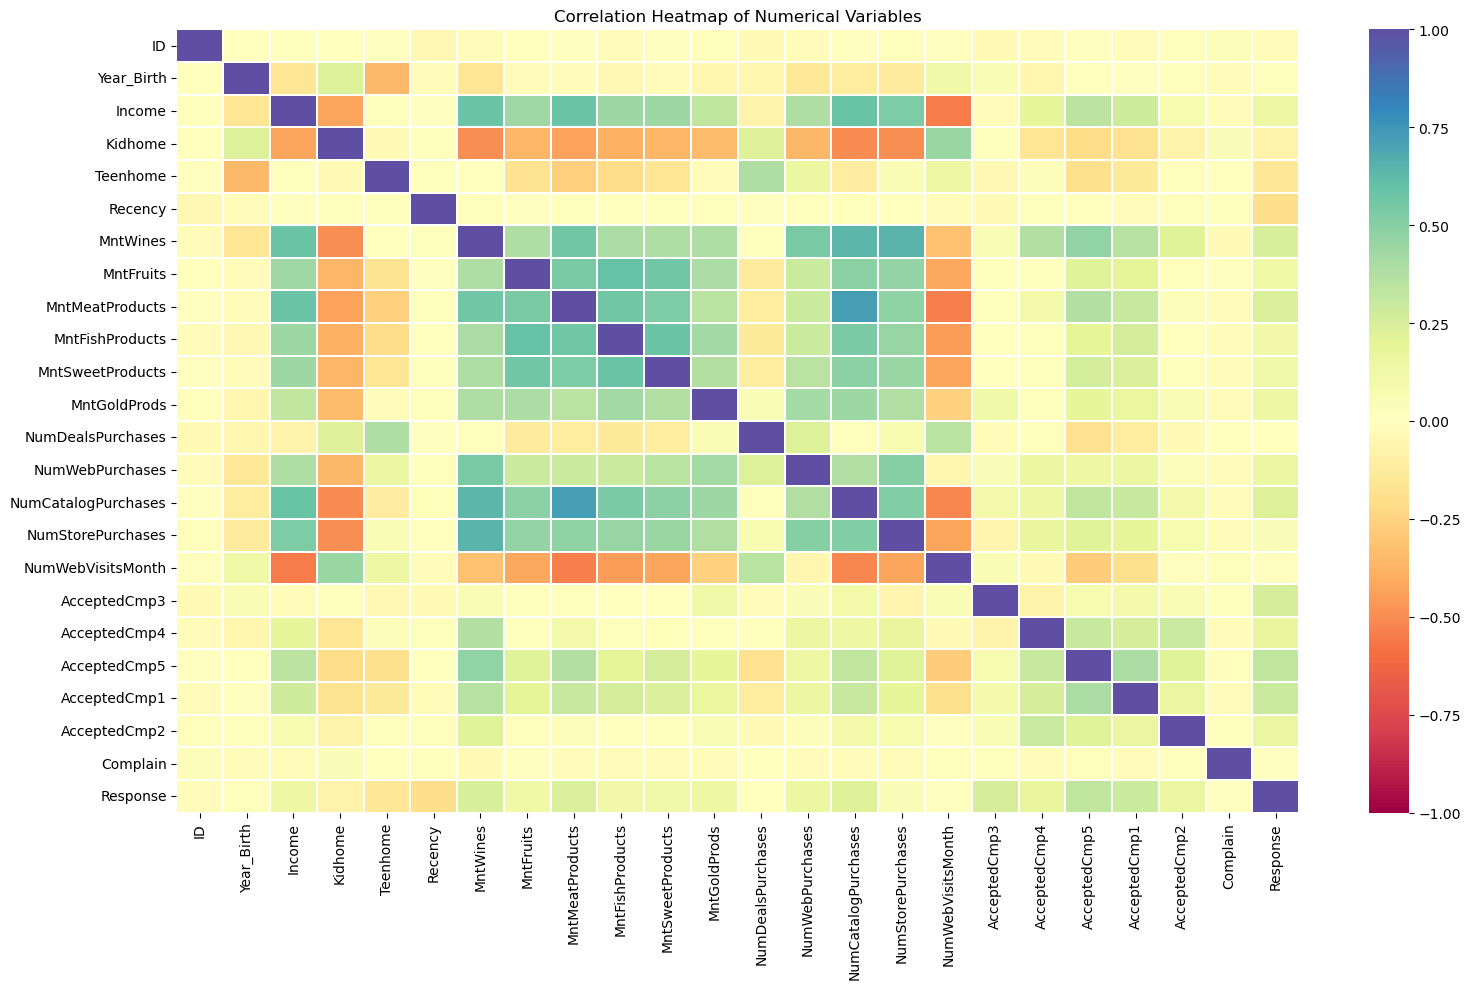

In [11]:
# Correlation heatmap for numerical variables
plt.figure(figsize=(16, 10))
sns.heatmap(
    raw_data.corr(numeric_only=True),
    cmap="Spectral",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### EDA insights

- Spending variables are strongly skewed and have different scales, so scaling is required before distance-based clustering.
- Product category spending variables are correlated with each other and with total customer value.
- Purchase channel variables such as catalog, store, web, and deals describe how customers buy, not only how much they spend.
- Complaint status is expected to be highly imbalanced and is more useful for profiling than for fitting clusters.

## 5. Data cleaning

The cleaning logic is intentionally conservative:

- Missing income is imputed using the median because income is skewed.
- Rare marital status labels are grouped into broader categories.
- Clearly unrealistic income and age values are removed.
- Dates are converted to proper datetime format.

In [12]:
def clean_customer_data(data: pd.DataFrame) -> pd.DataFrame:
    """Clean missing values, rare categories, dates, and unrealistic values."""
    data = data.copy()

    # Median imputation is robust for skewed income distributions.
    if "Income" in data.columns:
        data["Income"] = data["Income"].fillna(data["Income"].median())

        # Remove clear unrealistic income values, while keeping valid high-income customers.
        data = data[data["Income"] < 300_000].copy()

    # Group rare and unusual marital status labels.
    if "Marital_Status" in data.columns:
        data["Marital_Status"] = data["Marital_Status"].replace({
            "Alone": "Single",
            "Absurd": "Single",
            "YOLO": "Single"
        })

    # Convert customer registration date.
    if "Dt_Customer" in data.columns:
        data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True, errors="coerce")

    # The analysis reference year is 2016, following the original dataset context.
    if "Year_Birth" in data.columns:
        data["Age"] = 2016 - data["Year_Birth"]
        data = data[data["Age"] <= 115].copy()

    return data

data_clean = clean_customer_data(raw_data)
print(f"Cleaned data shape: {data_clean.shape}")
data_clean.head()

Cleaned data shape: (2236, 28)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age
0,5524,1957,Graduation,Single,"58,138.00",0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,59
1,2174,1954,Graduation,Single,"46,344.00",1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,62
2,4141,1965,Graduation,Together,"71,613.00",0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,51
3,6182,1984,Graduation,Together,"26,646.00",1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0,32
4,5324,1981,PhD,Married,"58,293.00",1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0,35


## 6. Feature engineering

The original variables are transformed into customer-level behavioural features that are easier to use for segmentation.

Key engineered features:

- `Kids`: total number of children or teenagers at home
- `Family_Size`: estimated household size
- `Expenses`: total spend across all product categories
- `NumTotalPurchases`: total number of purchases across channels
- `Engaged_in_days`: customer tenure relative to a reference date
- `TotalAcceptedCmp`: total number of accepted campaigns
- `AmountPerPurchase`: average spend per purchase

In [13]:
def engineer_customer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Create business-oriented customer features for segmentation and profiling."""
    data = data.copy()

    # Household composition.
    data["Kids"] = data.get("Kidhome", 0) + data.get("Teenhome", 0)

    if "Marital_Status" in data.columns:
        data["Marital_Status"] = data["Marital_Status"].replace({
            "Married": "Relationship",
            "Together": "Relationship",
            "Divorced": "Single",
            "Widow": "Single"
        })
        data["Status"] = data["Marital_Status"].map({"Single": 1, "Relationship": 2}).fillna(1)
    else:
        data["Status"] = 1

    data["Family_Size"] = data["Status"] + data["Kids"]

    # Total customer value across product categories.
    spend_cols = [col for col in SPEND_COLUMNS if col in data.columns]
    data["Expenses"] = data[spend_cols].sum(axis=1)

    # Total purchase activity across buying channels.
    purchase_cols = [col for col in PURCHASE_COLUMNS if col in data.columns]
    data["NumTotalPurchases"] = data[purchase_cols].sum(axis=1)

    # Total campaign acceptance across all campaign flags.
    campaign_cols = [col for col in CAMPAIGN_COLUMNS if col in data.columns]
    data["TotalAcceptedCmp"] = data[campaign_cols].sum(axis=1)

    # Customer tenure. A fixed reference date keeps the feature reproducible.
    if "Dt_Customer" in data.columns:
        reference_date = pd.to_datetime("2015-01-01")
        data["Engaged_in_days"] = (reference_date - data["Dt_Customer"]).dt.days
    else:
        data["Engaged_in_days"] = np.nan

    # Avoid division by zero when calculating average order value proxy.
    data = data[data["NumTotalPurchases"] > 0].copy()
    data["AmountPerPurchase"] = data["Expenses"] / data["NumTotalPurchases"]

    return data

data_features = engineer_customer_features(data_clean)
print(f"Feature-engineered data shape: {data_features.shape}")
data_features.head()

Feature-engineered data shape: (2232, 36)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase
0,5524,1957,Graduation,Single,"58,138.00",0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,59,0,1,1,1617,25,1,849,64.68
1,2174,1954,Graduation,Single,"46,344.00",1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,62,2,1,3,27,6,0,299,4.50
2,4141,1965,Graduation,Relationship,"71,613.00",0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,51,0,2,2,776,21,0,498,36.95
3,6182,1984,Graduation,Relationship,"26,646.00",1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0,32,1,2,3,53,8,0,325,6.62
4,5324,1981,PhD,Relationship,"58,293.00",1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0,35,1,2,3,422,19,0,347,22.21


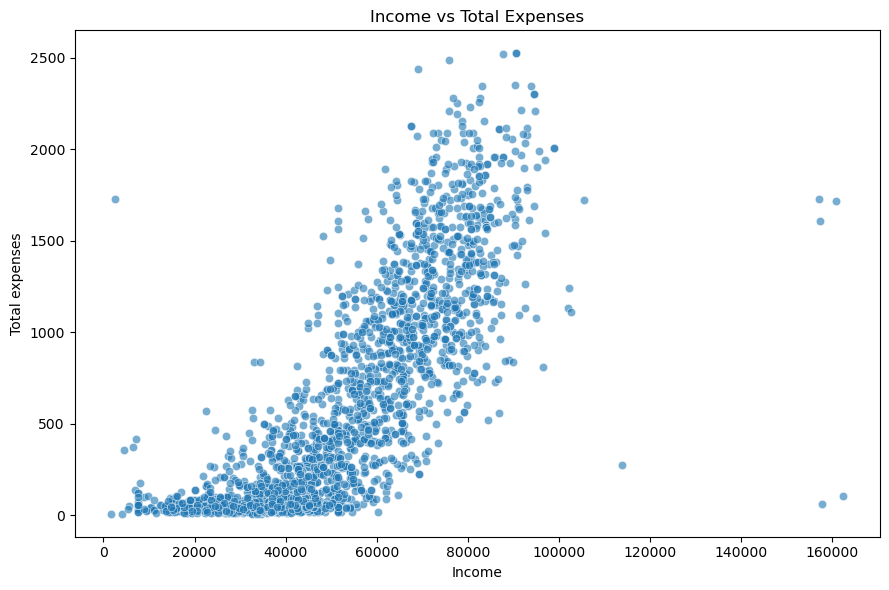

In [14]:
# Relationship between income and total spend
if {"Income", "Expenses"}.issubset(data_features.columns):
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=data_features, x="Income", y="Expenses", alpha=0.6)
    plt.title("Income vs Total Expenses")
    plt.xlabel("Income")
    plt.ylabel("Total expenses")
    plt.tight_layout()
    plt.show()

### Feature engineering insights

- `Expenses` captures total customer value more directly than individual product columns alone.
- `NumTotalPurchases` captures buying intensity across channels.
- `AmountPerPurchase` separates frequent low-ticket buyers from high-ticket buyers.
- `TotalAcceptedCmp` helps identify customers who have historically responded to campaigns.
- Demographic variables such as age, income, and family size are useful for interpreting clusters, but the model is fitted mainly on behavioural variables.

## 7. Create modelling dataset

The clustering model should be fitted mainly on behavioural customer variables.

Variables removed from fitting include:

- IDs and raw dates
- Categorical descriptors such as education and marital status
- Demographic variables such as income, age, family size, and children at home
- Campaign outcome and complaint flags used mainly for profiling

These variables are not lost. They remain in the full `data_features` dataframe and are used later to interpret the clusters.

In [15]:
def create_model_dataset(data: pd.DataFrame) -> pd.DataFrame:
    """Create the numerical behavioural dataset used as clustering input."""
    columns_to_drop = [
        "ID", "Year_Birth", "Dt_Customer", "day",
        "Complain", "Response",
        "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5",
        "Marital_Status", "Status", "Kids", "Education",
        "Kidhome", "Teenhome", "Income", "Age", "Family_Size"
    ]

    model_data = data.drop(columns=columns_to_drop, errors="ignore")
    model_data = model_data.select_dtypes(include=[np.number]).copy()

    return model_data

data_model = create_model_dataset(data_features)
print(f"Model dataset shape: {data_model.shape}")
data_model.head()

Model dataset shape: (2232, 17)


,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase
0,58,635,88,546,172,88,88,3,8,10,4,7,1617,25,1,849,64.68
1,38,11,1,6,2,1,6,2,1,1,2,5,27,6,0,299,4.50
2,26,426,49,127,111,21,42,1,8,2,10,4,776,21,0,498,36.95
3,26,11,4,20,10,3,5,2,2,0,4,6,53,8,0,325,6.62
4,94,173,43,118,46,27,15,5,5,3,6,5,422,19,0,347,22.21


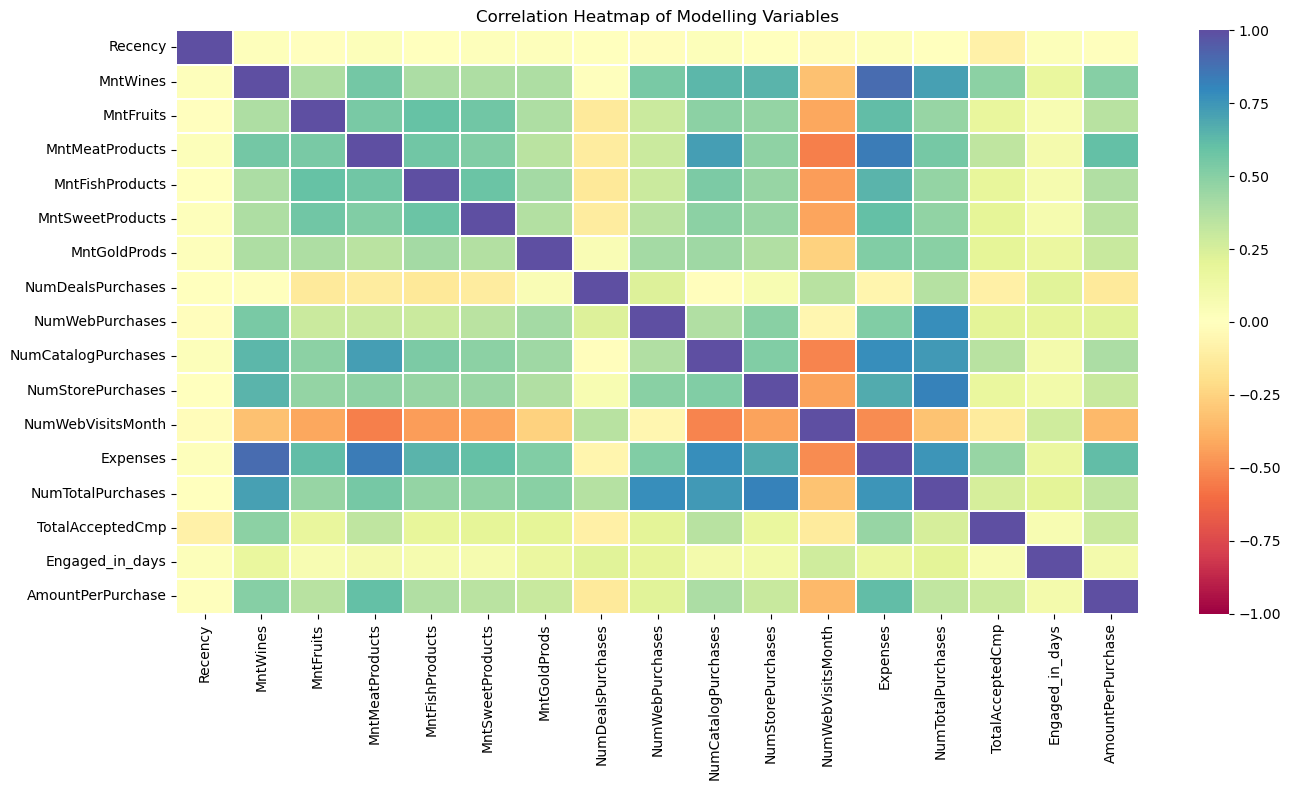

In [16]:
# Check correlation within the modelling dataset.
plt.figure(figsize=(14, 8))
sns.heatmap(
    data_model.corr(numeric_only=True),
    cmap="Spectral",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2
)
plt.title("Correlation Heatmap of Modelling Variables")
plt.tight_layout()
plt.show()

### Modelling input logic

The model is not fitted on the raw customer table.

The flow is:

`raw data → cleaned data → engineered features → behavioural model dataset → scaled data → PCA feature space → clustering`

Demographic and response variables are kept for profiling. The clustering itself is fitted mainly on behavioural variables such as product spend, purchase channels, total purchases, recency, and amount per purchase.


## 8. Scaling and PCA transformation

Scaling is required because distance-based clustering methods are sensitive to variable scale. For example, spending variables can have much larger numeric ranges than recency or purchase counts.

PCA is applied after scaling. In this notebook, all PCA components are retained. This means PCA does not remove information; it transforms the scaled variables into uncorrelated components. The first two components are used for visualization only.

In [17]:
scaler = StandardScaler()
scaled_array = scaler.fit_transform(data_model)

scaled_data = pd.DataFrame(
    scaled_array,
    columns=data_model.columns,
    index=data_model.index
)

# All PCA components are retained. This keeps the full information from the
# scaled modelling dataset while removing linear correlation between features.
pca = PCA(n_components=data_model.shape[1], random_state=RANDOM_STATE)
pca_array = pca.fit_transform(scaled_data)

data_pca = pd.DataFrame(
    pca_array,
    columns=[f"PC{i + 1}" for i in range(pca_array.shape[1])],
    index=data_model.index
)

# Keep a clean copy for model fitting. Cluster labels are added later only to data_pca.
pca_features = data_pca.copy()

explained_variance = pd.Series(
    pca.explained_variance_ratio_,
    index=data_pca.columns,
    name="explained_variance_ratio"
)

print(f"Number of PCA components retained: {data_pca.shape[1]}")
print(f"Cumulative variance retained: {explained_variance.sum() * 100:.2f}%")
data_pca.head()


Number of PCA components retained: 17
Cumulative variance retained: 100.00%


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
0,4.54,0.85,0.09,1.71,-1.21,0.02,-0.17,1.43,0.36,-0.60,-1.85,0.25,0.31,-0.36,0.41,-0.00,0.00
1,-2.86,-1.19,-0.08,-0.71,0.13,-0.15,0.34,0.41,0.02,-0.08,-0.08,-0.05,0.16,-0.28,-0.10,-0.00,0.00
2,1.51,0.06,-0.87,-1.10,-0.58,0.23,-0.56,-1.35,0.19,0.42,-0.59,0.81,-0.67,-0.05,0.05,0.00,-0.00
3,-2.60,-0.72,-0.10,-0.99,-0.26,-0.14,0.10,-0.02,0.26,0.10,-0.01,0.14,0.15,0.17,-0.05,0.00,-0.00
4,-0.15,0.54,-1.54,0.09,1.41,-0.26,0.12,0.91,0.91,0.36,-0.08,0.01,-0.38,-0.19,0.14,-0.00,-0.00


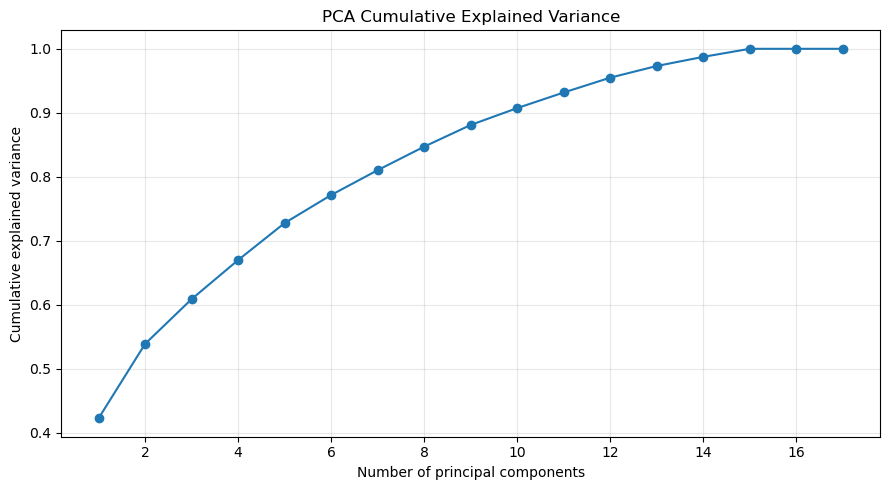

In [18]:
# Cumulative explained variance plot.
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance.cumsum(), marker="o")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

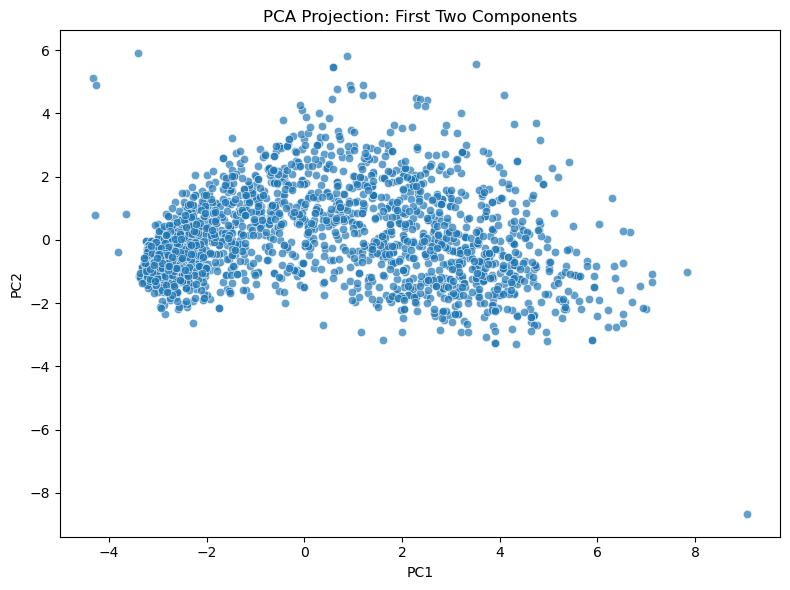

In [19]:
# PC1 and PC2 are used for visualization only.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_pca, x="PC1", y="PC2", alpha=0.7)
plt.title("PCA Projection: First Two Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

### PCA interpretation

- Clustering is fitted on `data_pca`, which contains all retained PCA components.
- Because all components are kept, PCA mainly decorrelates the scaled variables instead of reducing the number of dimensions.
- A possible future improvement would be to compare this approach against reduced PCA, for example keeping only components explaining 85–90% of variance.

## 9. Helper functions for modelling and profiling

These functions keep the notebook readable and make the workflow easier to reuse.

In [20]:
def get_pca_features(pca_df: pd.DataFrame) -> pd.DataFrame:
    """Return only PCA component columns, excluding any model label columns."""
    return pca_df.filter(regex=r"^PC\d+$|^\d+$").copy()


def pca_cluster_plot(pca_df: pd.DataFrame, label_column: str, title: str) -> None:
    """Plot cluster labels on the first two PCA components."""
    pca_cols = get_pca_features(pca_df).columns.tolist()
    pc1, pc2 = pca_cols[0], pca_cols[1]

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=pca_df,
        x=pc1,
        y=pc2,
        hue=label_column,
        palette="tab10",
        alpha=0.75
    )
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend(title=label_column, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def profile_clusters(data: pd.DataFrame, cluster_column: str) -> pd.DataFrame:
    """Return cluster-wise numeric averages with customer counts."""
    profile = data.groupby(cluster_column).mean(numeric_only=True)
    counts = data[cluster_column].value_counts().sort_index().rename("customer_count")
    return profile.join(counts)


def plot_cluster_boxplots(data: pd.DataFrame, cluster_column: str, columns) -> None:
    """Create profiling boxplots for a selected cluster label."""
    columns = [col for col in columns if col in data.columns]
    n_cols = 4
    n_rows = math.ceil(len(columns) / n_cols)

    plt.figure(figsize=(24, 4 * n_rows))

    for idx, column in enumerate(columns, start=1):
        plt.subplot(n_rows, n_cols, idx)
        sns.boxplot(data=data, x=cluster_column, y=column, showmeans=True)
        plt.title(column)
        plt.xlabel(cluster_column)

    plt.tight_layout()
    plt.show()


PROFILE_COLUMNS = [
    "Income", "Age", "Family_Size", "Kidhome", "Teenhome", "Recency",
    "Expenses", "AmountPerPurchase", "NumTotalPurchases",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumWebVisitsMonth",
    "TotalAcceptedCmp", "Response", "Complain"
]


## 10. K-Means clustering

K-Means is tested first because it is simple, interpretable, and commonly used for customer segmentation.

The elbow method and silhouette score are used to compare different cluster counts. Cluster profiles are then reviewed to assess business interpretability.

In [21]:
kmeans_results = []

for k in range(2, 10):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(pca_features)

    kmeans_results.append({
        "n_clusters": k,
        "silhouette": silhouette_score(pca_features, labels),
        "inertia": model.inertia_
    })

kmeans_results = pd.DataFrame(kmeans_results)
kmeans_results


,n_clusters,silhouette,inertia
0,2,0.35,"25,194.87"
1,3,0.27,"22,049.64"
2,4,0.25,"20,722.22"
3,5,0.24,"19,819.66"
4,6,0.13,"19,019.74"
5,7,0.22,"17,706.62"
6,8,0.13,"16,939.96"
7,9,0.13,"16,387.73"


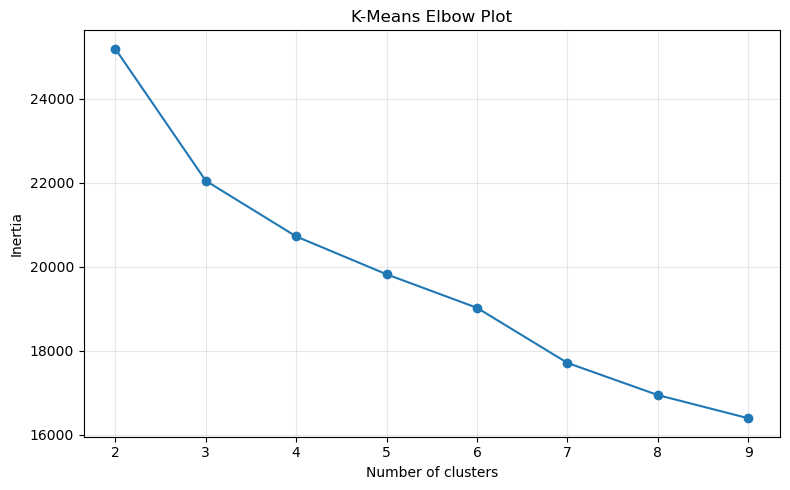

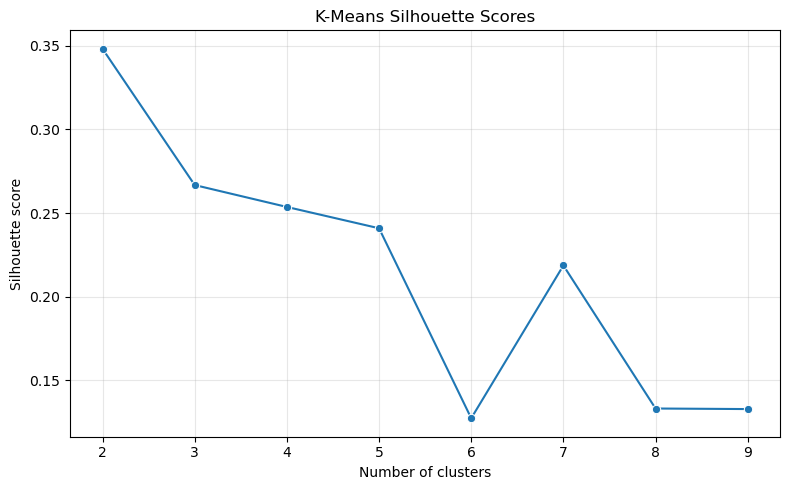

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(kmeans_results["n_clusters"], kmeans_results["inertia"], marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Plot")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.lineplot(data=kmeans_results, x="n_clusters", y="silhouette", marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("K-Means Silhouette Scores")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
candidate_k = [2, 3, 4, 5]

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(pca_features)

    print(f"\nCluster distribution for K={k}")
    print((pd.Series(labels).value_counts(normalize=True).sort_index() * 100).round(2))



Cluster distribution for K=2
0   58.47
1   41.53
Name: proportion, dtype: float64

Cluster distribution for K=3
0   25.45
1   27.87
2   46.68
Name: proportion, dtype: float64

Cluster distribution for K=4
0   45.70
1   20.03
2   11.07
3   23.21
Name: proportion, dtype: float64

Cluster distribution for K=5
0   12.86
1   18.19
2   15.99
3    8.42
4   44.53
Name: proportion, dtype: float64


In [24]:
candidate_k = [2, 3, 4, 5, 7]

quality_results = []

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(pca_features)

    quality_results.append({
        "n_clusters": k,
        "silhouette": silhouette_score(pca_features, labels),
        "calinski_harabasz": calinski_harabasz_score(pca_features, labels),
        "davies_bouldin": davies_bouldin_score(pca_features, labels),
        "inertia": model.inertia_
    })

quality_results = pd.DataFrame(quality_results)
quality_results.round(3)


,n_clusters,silhouette,calinski_harabasz,davies_bouldin,inertia
0,2,0.35,"1,128.43",1.30,"25,194.87"
1,3,0.27,803.38,1.73,"22,049.64"
2,4,0.25,617.21,2.06,"20,722.22"
3,5,0.24,509.13,2.08,"19,819.66"
4,7,0.22,423.83,1.72,"17,706.62"


* Based on the quantitative cluster quality metrics, K=2 produced the strongest statistical separation, with the highest Calinski-Harabasz score and lowest Davies-Bouldin score.  
 
* However, K=2 created a very broad segmentation.

* K=3 was selected as a more practical business solution because it preserved a similar silhouette score while providing a more actionable low-, medium-, and high-value customer structure.

* K=5 was reviewed for additional business detail, but it showed weaker statistical quality and was therefore not selected as the final model.

KMeans_3
0     568
1     622
2    1042
Name: count, dtype: int64


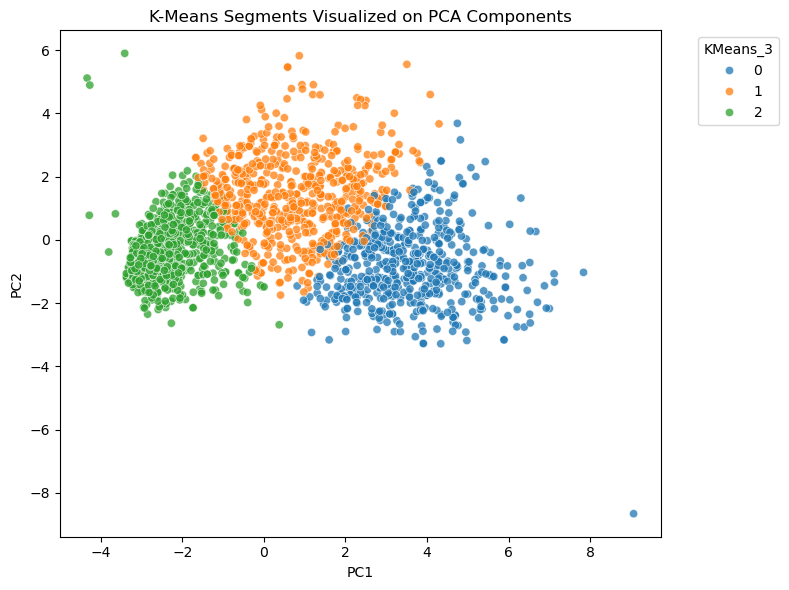

In [25]:
# Final K-Means model used for the customer segments.
kmeans_final = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans_final.fit_predict(pca_features)

data_pca["KMeans_3"] = kmeans_labels
data_segments = data_features.copy()
data_segments["KMeans_3"] = kmeans_labels

print(data_segments["KMeans_3"].value_counts().sort_index())

pca_cluster_plot(
    data_pca,
    "KMeans_3",
    "K-Means Segments Visualized on PCA Components"
)


In [26]:
kmeans_profile = profile_clusters(data_segments, "KMeans_3")
kmeans_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,customer_count
KMeans_3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,635.76","1,968.18","76,349.11",0.04,0.21,50.40,632.33,69.38,466.46,101.73,70.82,78.47,1.36,5.19,6.12,8.30,2.89,0.08,0.14,0.26,0.21,0.03,0.01,0.29,47.82,0.25,1.62,1.87,"1,419.19",20.98,1.02,551.03,73.24,568
1,"5,485.48","1,965.95","57,184.02",0.30,0.84,47.82,443.19,22.66,136.03,29.76,24.07,61.16,3.81,6.44,3.04,7.79,5.81,0.07,0.12,0.02,0.04,0.01,0.01,0.14,50.05,1.14,1.66,2.80,716.87,21.09,0.40,596.95,33.73,622
2,"5,616.26","1,971.06","35,424.26",0.75,0.47,49.14,43.37,5.03,22.85,7.33,5.14,15.10,1.97,2.09,0.56,3.26,6.35,0.07,0.02,0.00,0.00,0.00,0.01,0.08,44.94,1.22,1.65,2.88,98.82,7.89,0.17,500.01,11.32,1042


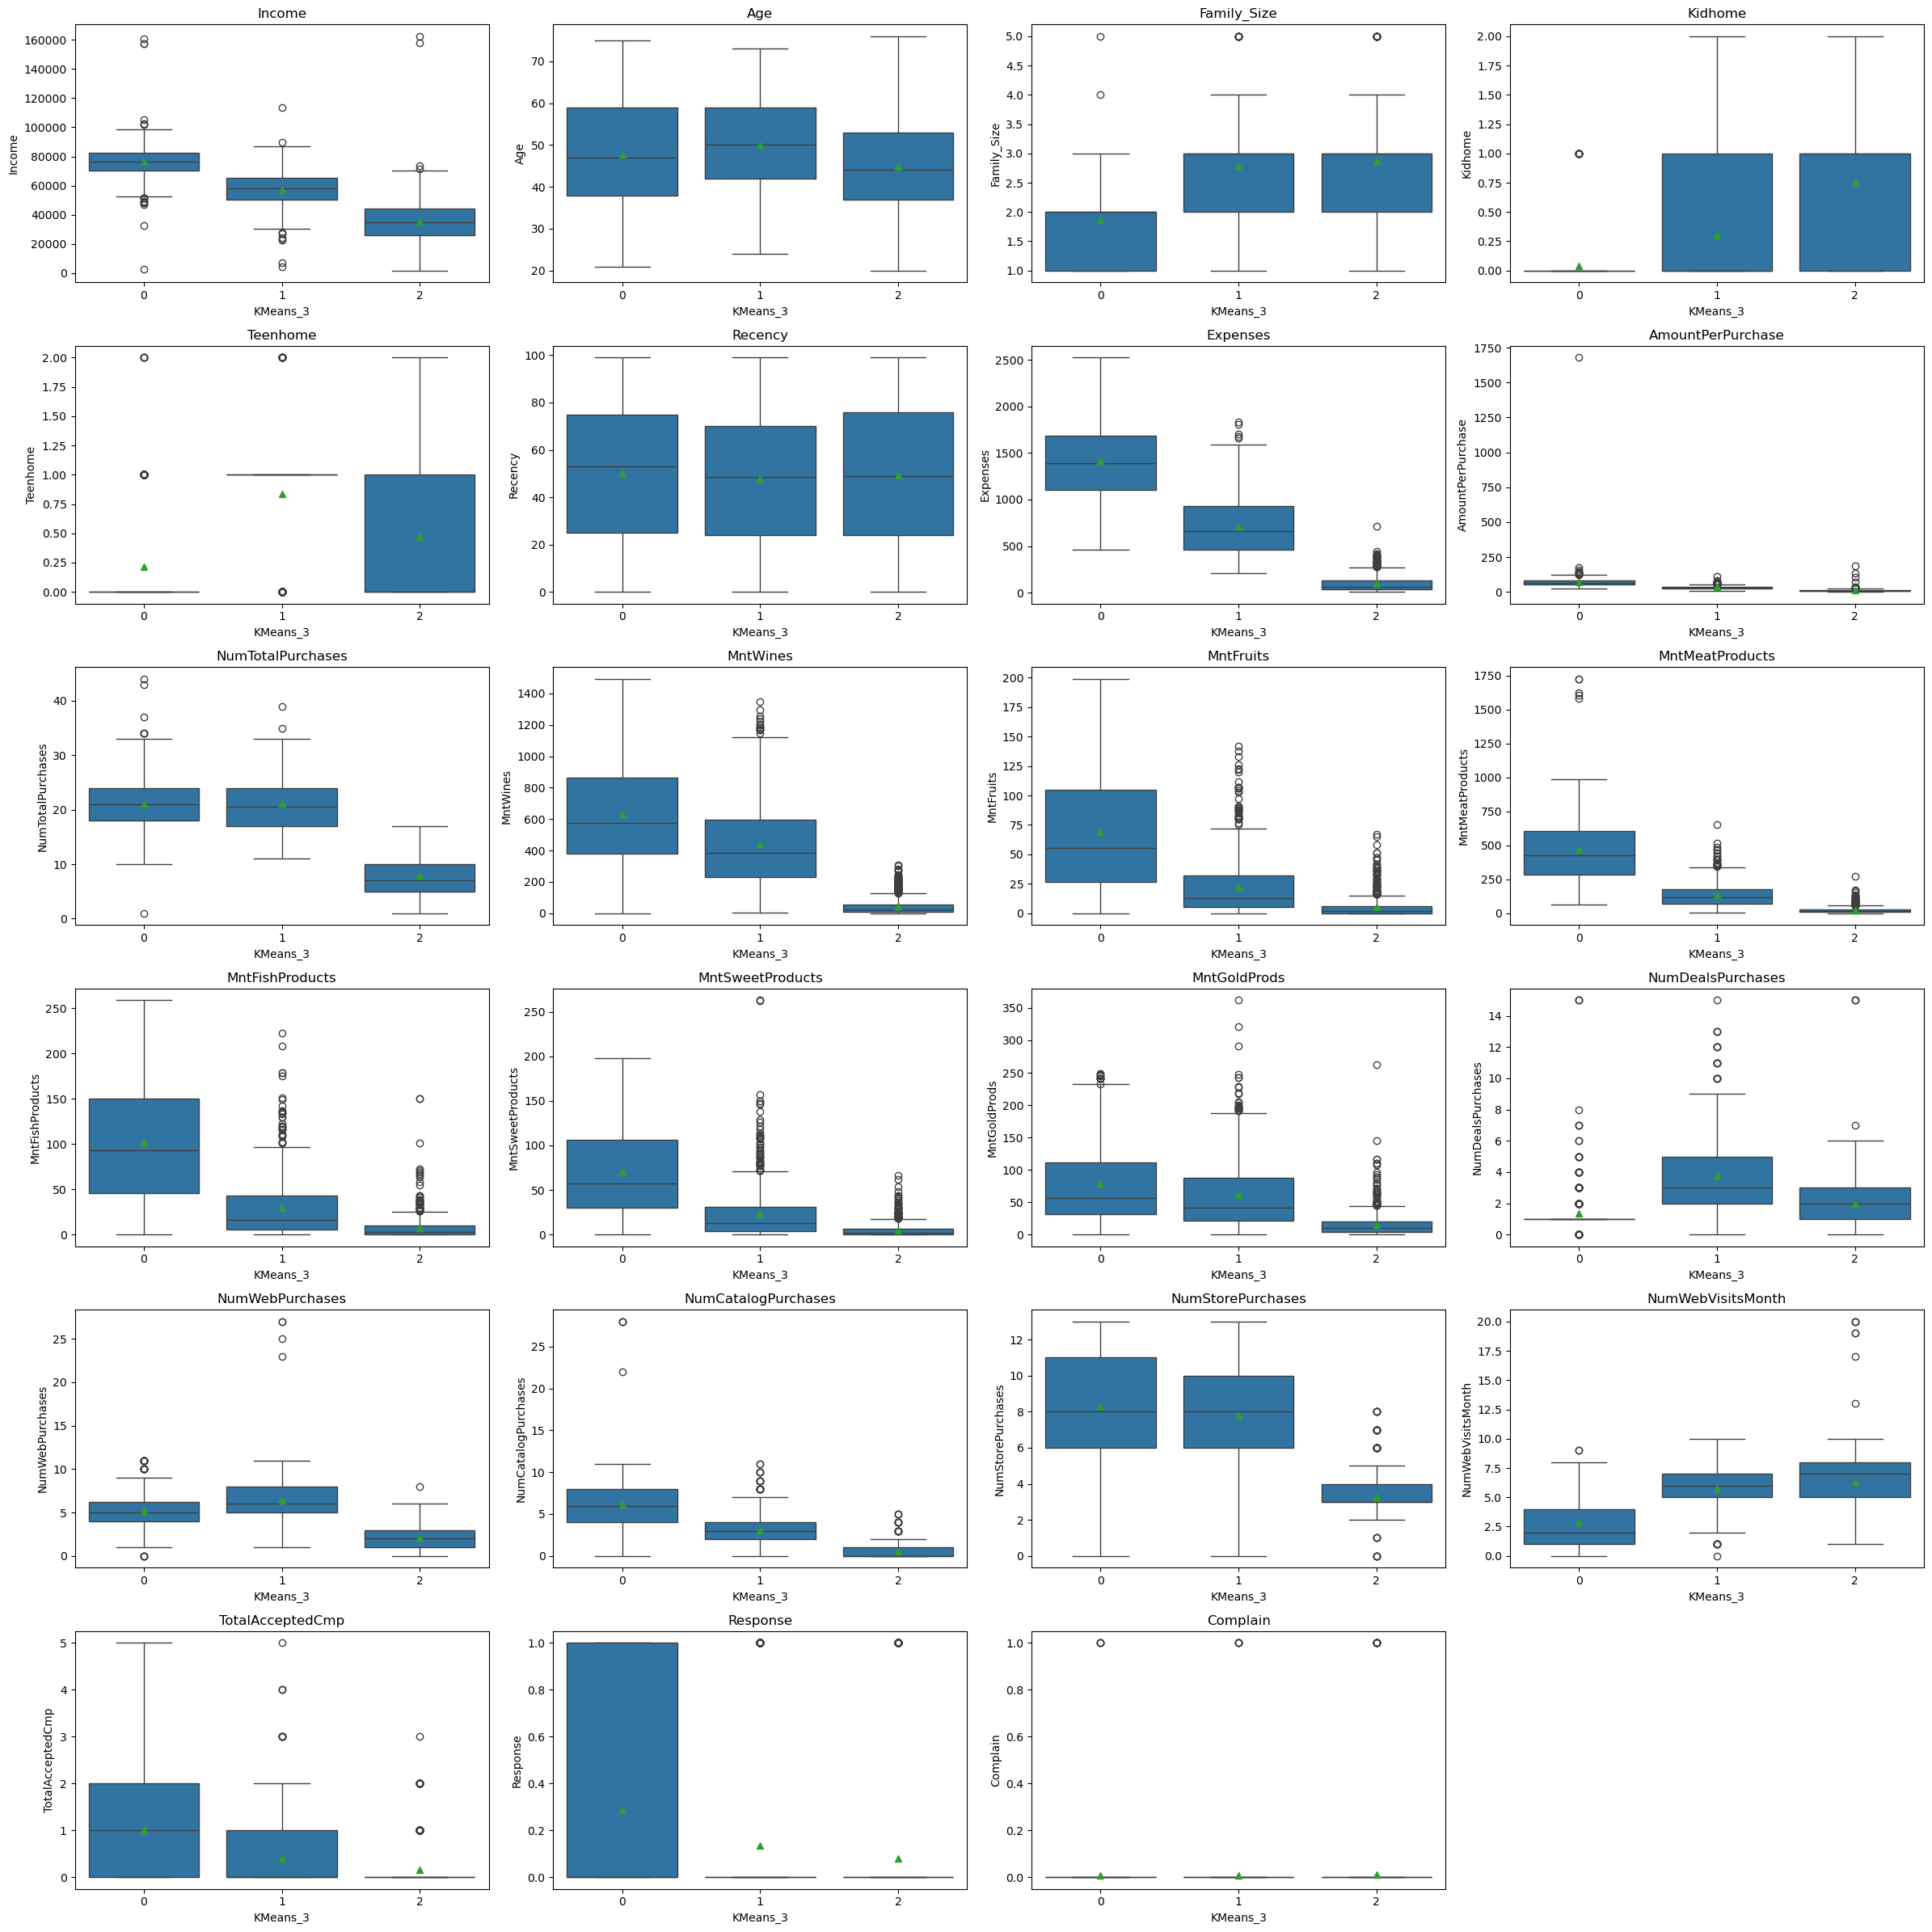

In [27]:
plot_cluster_boxplots(data_segments, "KMeans_3", PROFILE_COLUMNS)

### K-Means Cluster Insights: 3-Cluster Solution

The 3-cluster K-Means solution provides a simple and business-friendly segmentation of customers into low-value, medium-value, and high-value groups.

#### Cluster 0: Low-value customers

These customers have the lowest income, lowest expenses, and weakest purchase activity. They spend little across most product categories and have low total purchases.

**Business action:** Use low-cost reactivation campaigns, simple discounts, or automated emails.

#### Cluster 1: Medium-value active customers

These customers have moderate income, moderate spending, and reasonable purchase activity across channels. They are active but not yet premium customers.

**Business action:** Use cross-selling, bundles, and upselling campaigns to increase value.

#### Cluster 2: High-value premium customers

These customers have the highest income, highest expenses, and strongest spending across product categories. They also show high total purchases and stronger campaign response.

**Business action:** Prioritize loyalty programs, personalized offers, premium bundles, and retention campaigns.

### Overall Interpretation

The clusters are mainly separated by income, expenses, product spending, purchase frequency, and channel activity. Recency and complaints are not major drivers.

## 11. Hierarchical clustering

Hierarchical clustering is used as a comparison method. Dendrograms help inspect whether the data has visible nested cluster structure.

Euclidean distance with Ward linkage is useful for compact clusters. Other linkage methods are also compared using cophenetic correlation. 

Only a selected set of distance and linkage combinations was tested to keep the hierarchical clustering analysis focused and interpretable. Since the data was standardized and transformed using PCA, Euclidean distance was the most appropriate baseline distance metric.

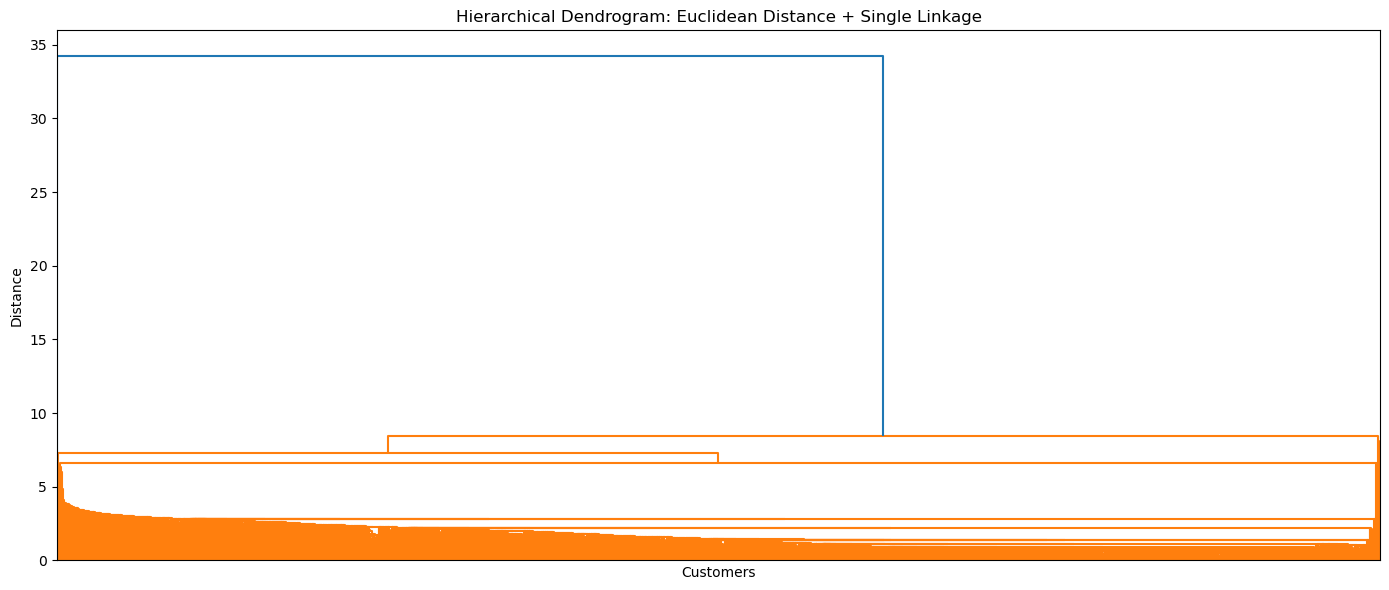

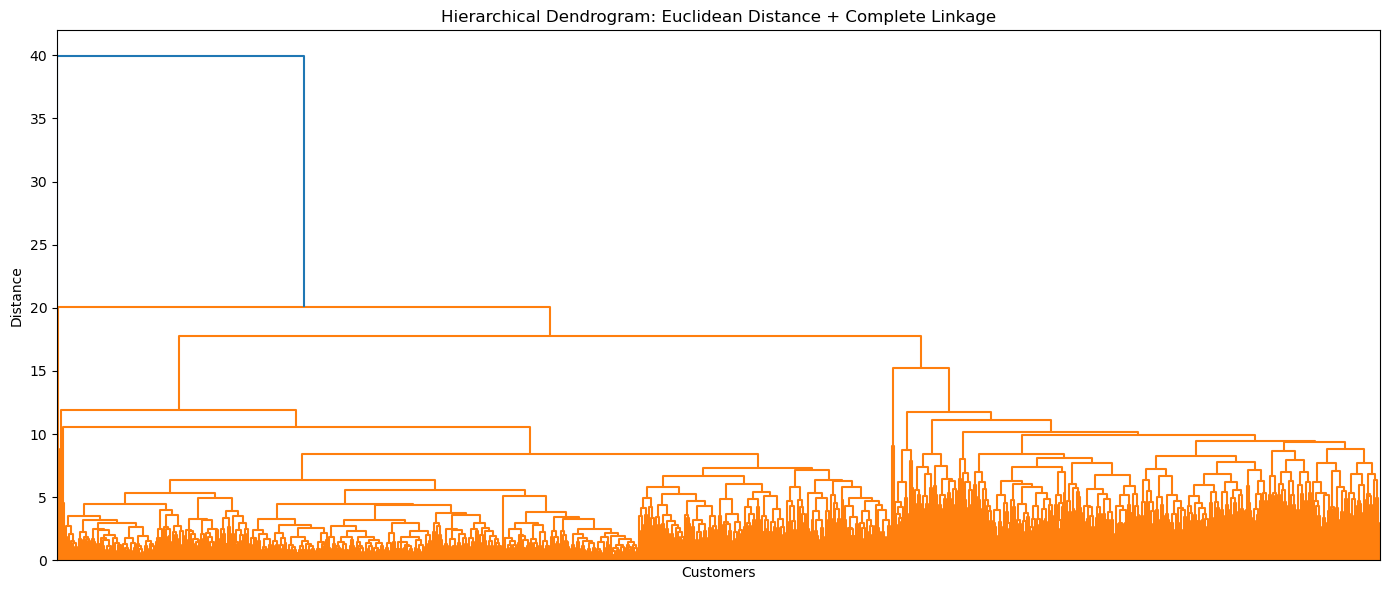

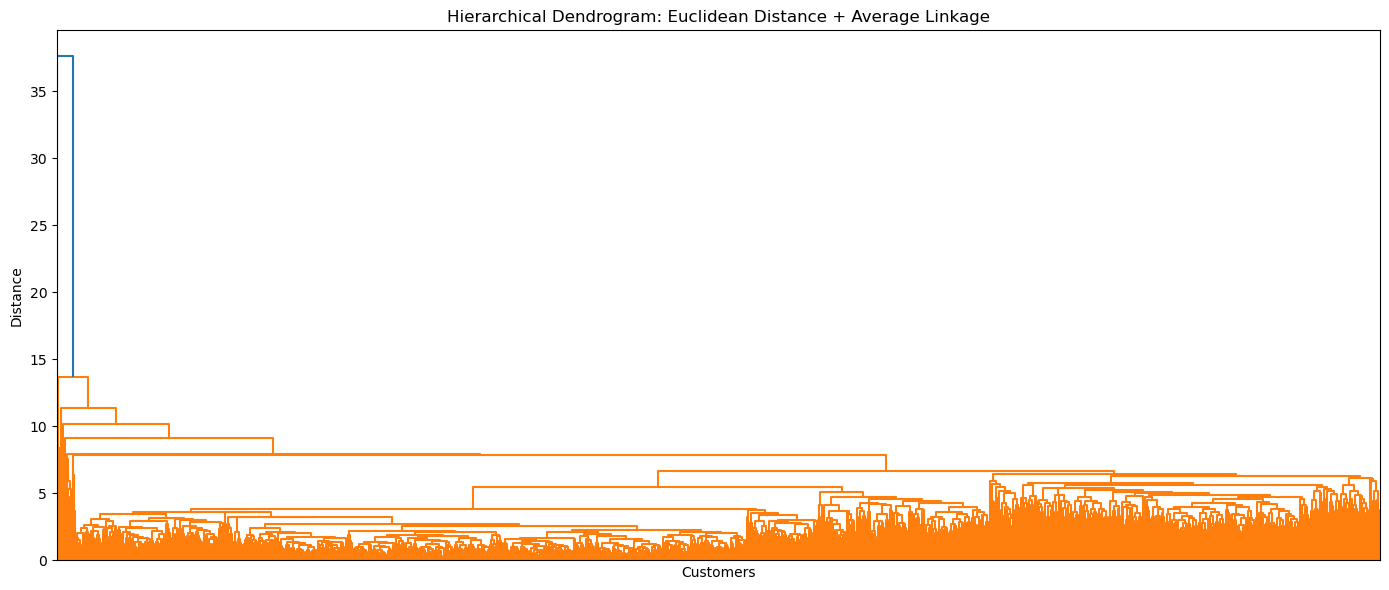

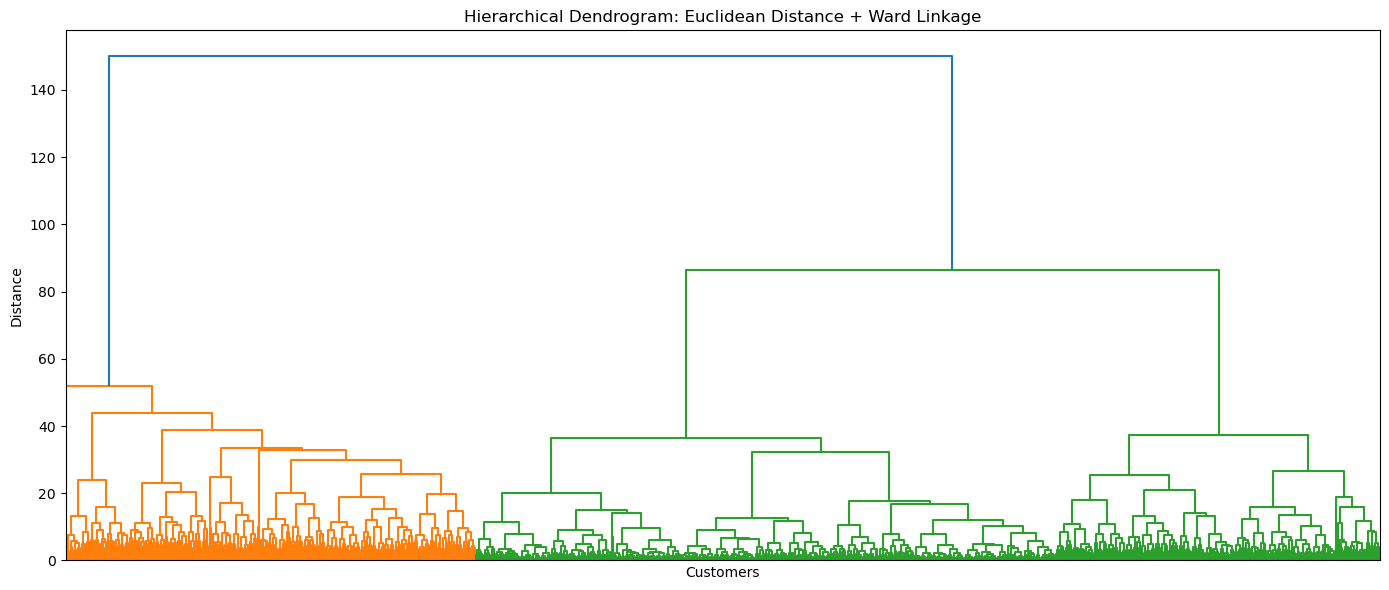

,distance,linkage,cophenetic_correlation
0,euclidean,single,0.82
1,euclidean,complete,0.72
2,euclidean,average,0.86
3,euclidean,ward,0.61


In [28]:
euclidean_dist = pdist(pca_features, metric="euclidean")
hierarchical_results = []

for method in ["single", "complete", "average", "ward"]:
    z_matrix = linkage(
        pca_features,
        method=method,
        metric="euclidean"
    )

    coph_corr, _ = cophenet(z_matrix, euclidean_dist)

    hierarchical_results.append({
        "distance": "euclidean",
        "linkage": method,
        "cophenetic_correlation": coph_corr
    })

    plt.figure(figsize=(14, 6))
    dendrogram(z_matrix, no_labels=True)
    plt.title(f"Hierarchical Dendrogram: Euclidean Distance + {method.capitalize()} Linkage")
    plt.xlabel("Customers")
    plt.ylabel("Distance")
    plt.tight_layout()
    plt.show()

hierarchical_results = pd.DataFrame(hierarchical_results)
hierarchical_results.round(3)


### Hierarchical Clustering Insights

The hierarchical clustering comparison shows that **Euclidean distance with average linkage** gives the highest cophenetic correlation, around **0.86**. This means it preserves the original distance structure better than the other linkage methods.

Single linkage also gives a relatively good cophenetic correlation, around **0.82**, but the dendrogram shows a chaining effect, where observations are gradually connected instead of forming compact groups.

Complete linkage performs weaker, with a cophenetic correlation around **0.72**. It creates more compact clusters than single linkage, but it does not preserve the original distance structure as well.

Ward linkage gives the lowest cophenetic correlation, around **0.61**, although visually it can still show clearer large splits. This means Ward may be useful for creating compact clusters, but it is not the best method based on cophenetic correlation.

Overall, **average linkage is the best hierarchical method based on cophenetic correlation**, while Ward linkage can still be tested if the goal is to create compact and business-interpretable customer groups.

In [29]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

# Fit a 3-cluster hierarchical model using Ward linkage
try:
    hc_model = AgglomerativeClustering(
        n_clusters=3,
        metric="euclidean",
        linkage="ward"
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    hc_model = AgglomerativeClustering(
        n_clusters=3,
        affinity="euclidean",
        linkage="ward"
    )

# Fit on PCA features only
hc_labels = hc_model.fit_predict(pca_features)

# Add labels
data_pca["HC_3"] = hc_labels
data_segments["HC_3"] = hc_labels

# Check distribution
print(data_segments["HC_3"].value_counts().sort_index())

HC_3
0    696
1    550
2    986
Name: count, dtype: int64


In [30]:
hc_profile = profile_clusters(data_segments, "HC_3")
hc_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,customer_count
HC_3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,629.80","1,967.67","73,308.28",0.06,0.34,49.10,635.92,63.03,412.56,88.33,65.01,83.15,1.78,5.60,5.78,8.40,3.53,0.09,0.14,0.23,0.18,0.03,0.00,0.27,48.33,0.40,1.61,2.01,"1,347.99",21.56,0.94,576.08,67.79,0.22,696
1,"5,475.99","1,966.34","55,094.61",0.35,0.80,48.64,360.85,18.72,119.43,29.31,19.69,48.45,3.81,5.95,2.59,7.19,5.79,0.06,0.11,0.01,0.03,0.01,0.01,0.12,49.66,1.14,1.68,2.82,596.45,19.55,0.34,571.57,30.11,1.08,550
2,"5,613.68","1,971.20","35,012.41",0.77,0.47,49.35,39.50,4.65,20.83,6.42,4.54,14.02,1.89,1.99,0.51,3.20,6.31,0.07,0.01,0.00,0.00,0.00,0.01,0.08,44.80,1.24,1.65,2.89,89.97,7.60,0.16,496.93,10.80,1.99,986


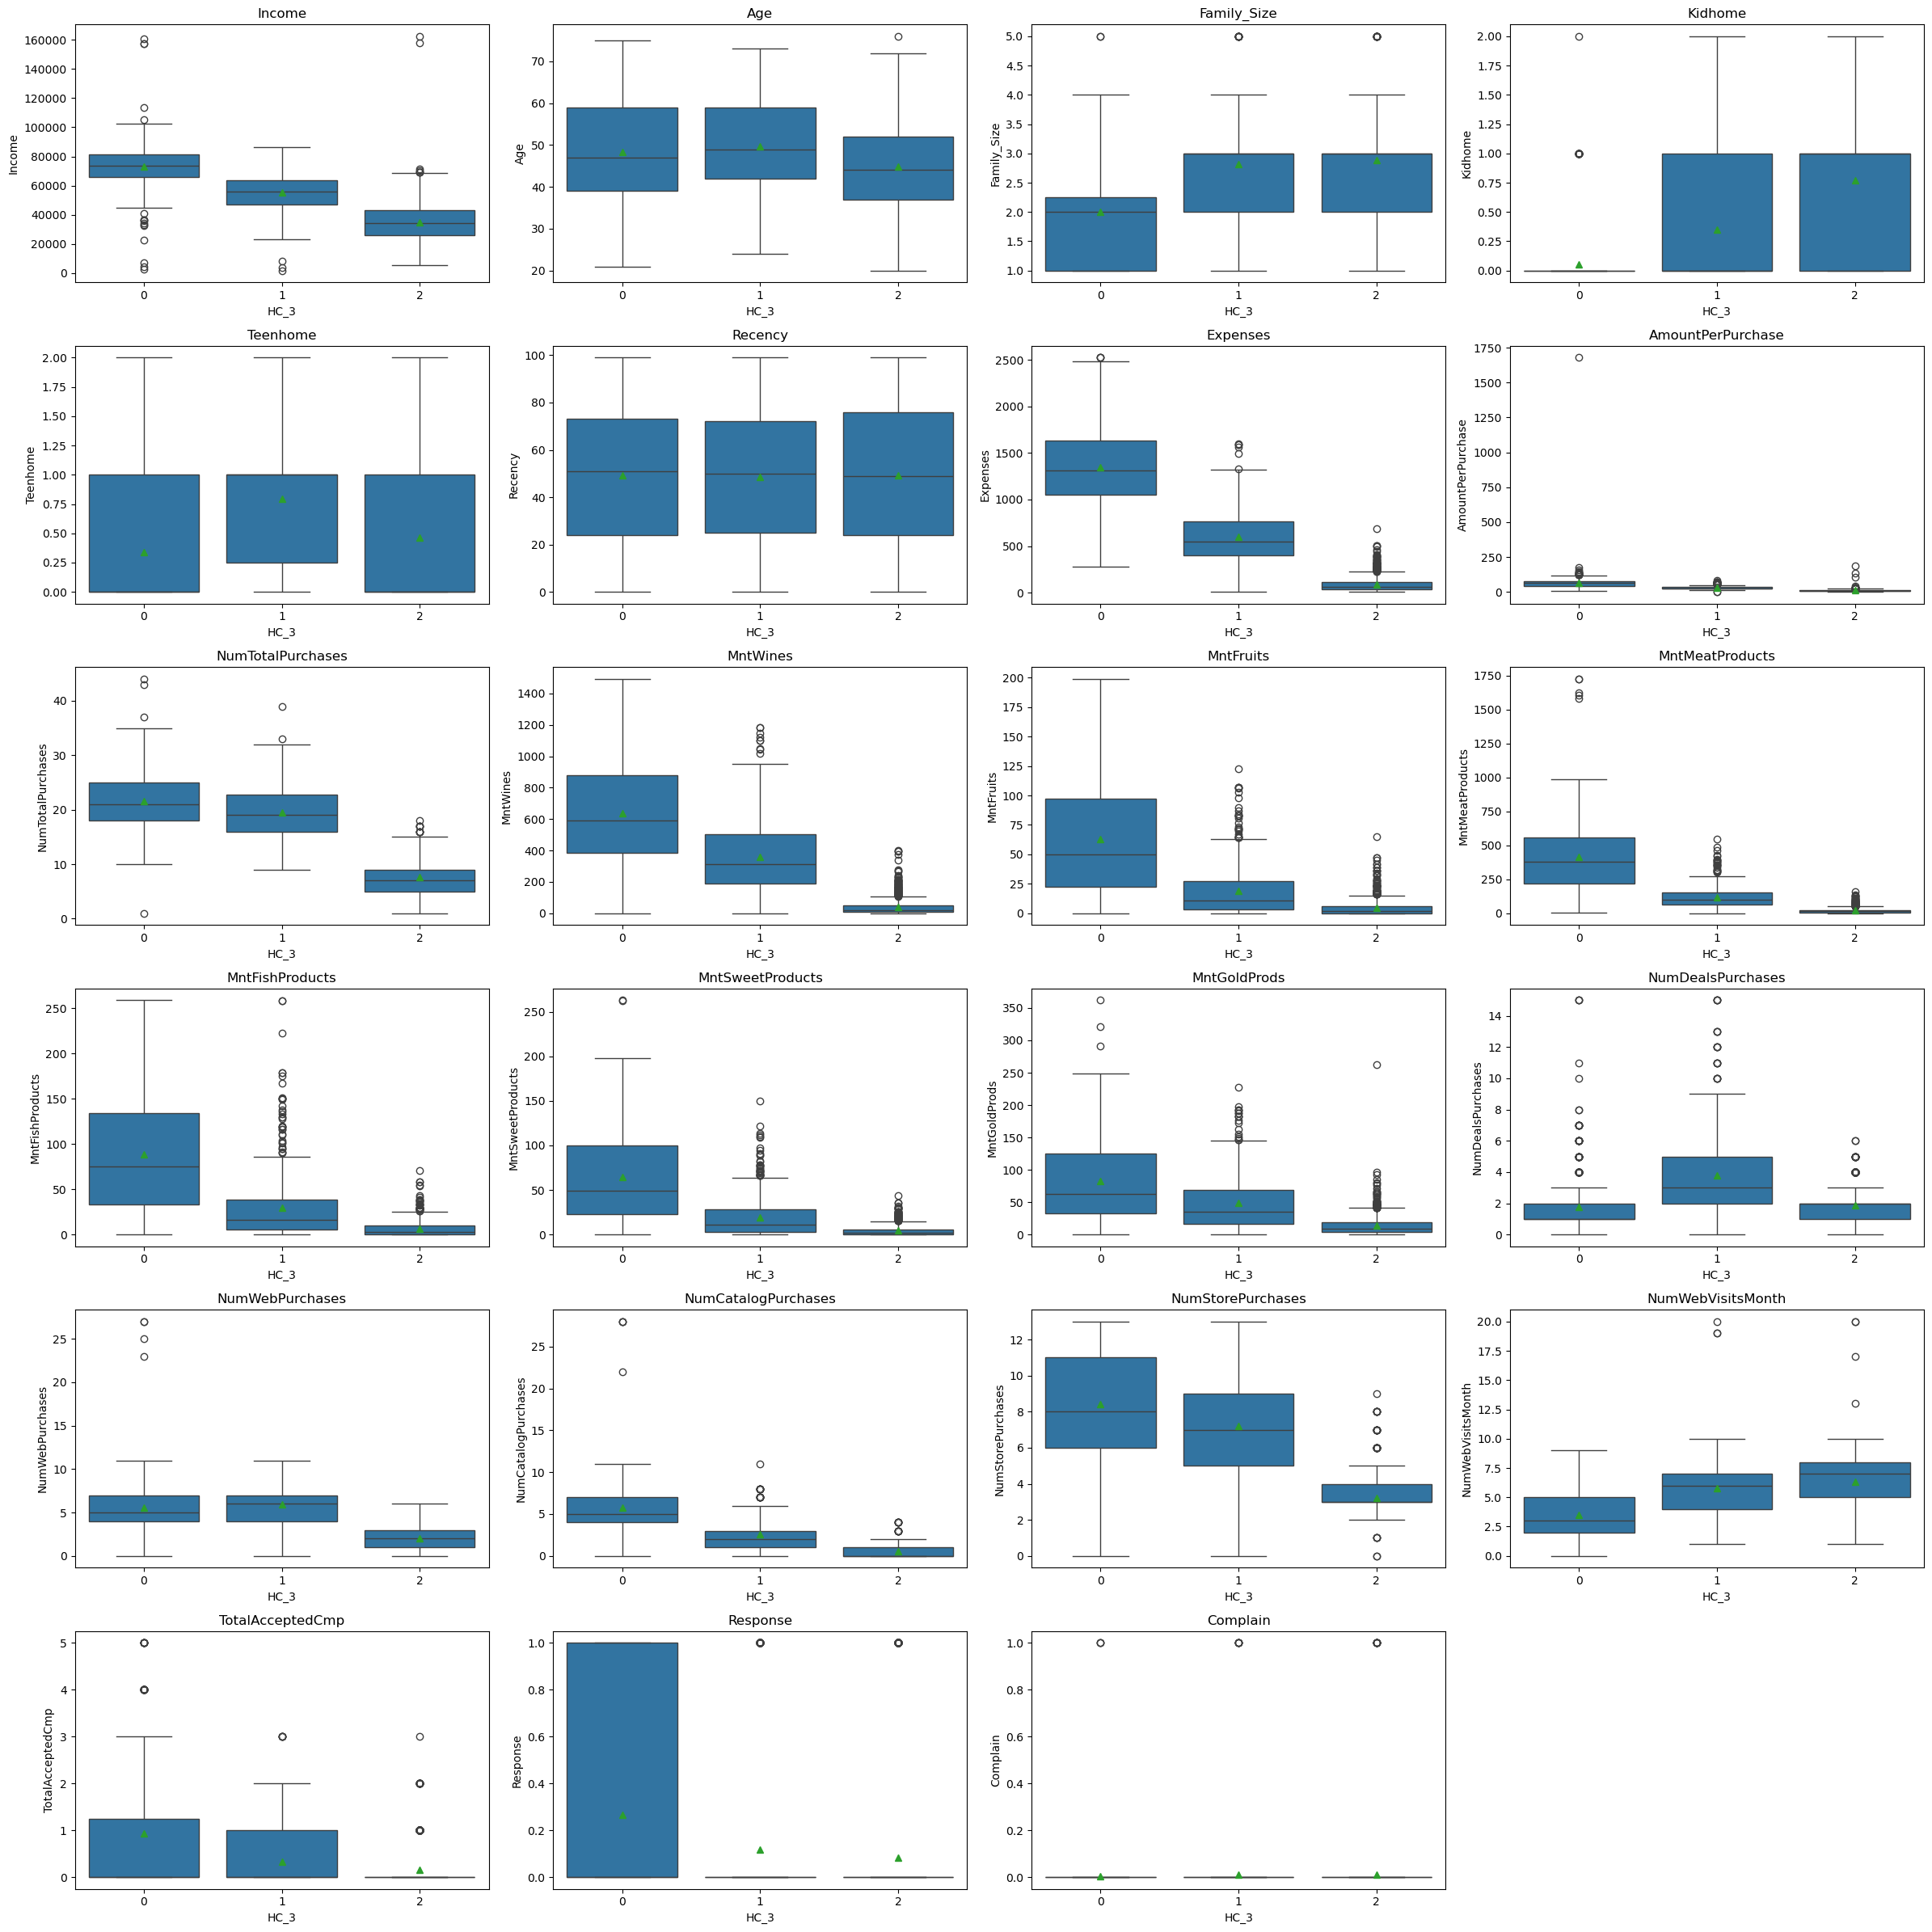

In [31]:
# Boxplot profiling for Ward hierarchical clustering
plot_cluster_boxplots(data_segments, "HC_3", PROFILE_COLUMNS)

HC_Average_3
0    2227
1       1
2       4
Name: count, dtype: int64


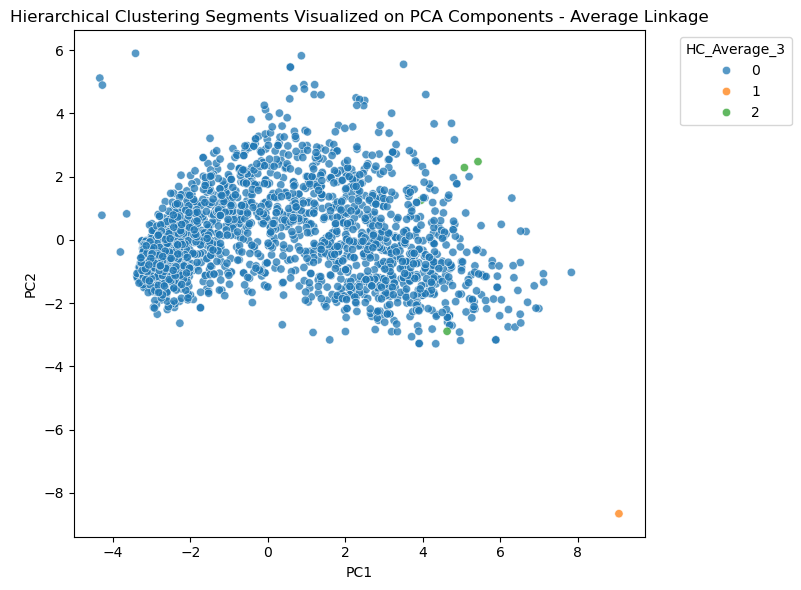

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,customer_count
HC_Average_3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,584.29","1,968.88","51,781.69",0.44,0.51,49.10,305.30,26.37,163.95,37.67,27.18,44.15,2.32,4.10,2.63,5.82,5.33,0.07,0.07,0.07,0.06,0.01,0.01,0.15,47.12,0.95,1.64,2.60,604.62,14.86,0.45,539.69,32.56,1.22,1.13,2227
1,"8,720.00","1,978.00","51,381.50",0.00,0.00,53.00,32.00,2.00,"1,607.00",12.00,4.00,22.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,38.00,0.00,2.00,2.00,"1,679.00",1.00,1.00,872.00,"1,679.00",0.00,0.00,1
2,"5,070.75","1,977.75","119,409.75",0.25,0.25,43.50,19.25,4.75,"1,663.50",5.25,1.75,1.75,11.25,0.00,26.50,0.25,0.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,38.25,0.50,2.00,2.50,"1,696.25",38.00,0.00,630.75,46.13,0.00,0.00,4


In [32]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

# Fit a 3-cluster hierarchical model using Average linkage
try:
    hc_avg_model = AgglomerativeClustering(
        n_clusters=3,
        metric="euclidean",
        linkage="average"
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    hc_avg_model = AgglomerativeClustering(
        n_clusters=3,
        affinity="euclidean",
        linkage="average"
    )

# Fit on PCA features only
hc_avg_labels = hc_avg_model.fit_predict(pca_features)

# Add labels
data_pca["HC_Average_3"] = hc_avg_labels
data_segments["HC_Average_3"] = hc_avg_labels

# Check distribution
print(data_segments["HC_Average_3"].value_counts().sort_index())

# Visualize clusters on PCA components
pca_cluster_plot(
    data_pca,
    "HC_Average_3",
    "Hierarchical Clustering Segments Visualized on PCA Components - Average Linkage"
)

# Profile clusters
hc_avg_profile = profile_clusters(data_segments, "HC_Average_3")

hc_avg_profile.round(2)

### Hierarchical Clustering Insights

Average linkage had the highest cophenetic correlation, which means it preserved the original distance structure better. However, the 3-cluster solution was not practical because it created one very large cluster and two very small outlier groups.

Ward linkage had a lower cophenetic correlation, but it produced more balanced and interpretable customer segments. The clusters were easier to explain from a business perspective and showed clearer separation in the PCA plot.

Overall, Average linkage was stronger statistically for the dendrogram structure, while Ward linkage was more useful for customer segmentation. For business use, Ward linkage is the better hierarchical clustering option.

### Ward Linkage Cluster Insights

Ward linkage produced three practical customer segments based on value, spending, purchase activity, and deal sensitivity.

#### Cluster 0: High-value customers

These customers have the highest income, highest expenses, and strongest spending across most product categories. They also show strong activity across store, catalog, and web channels.

**Business action:** Prioritize retention, loyalty rewards, premium bundles, and personalized offers.

#### Cluster 1: Low-value customers

These customers have the lowest income, lowest expenses, and weakest purchase activity across most channels and product categories.

**Business action:** Use low-cost reactivation campaigns, automated emails, and simple discounts. Avoid high marketing spend on this group.

#### Cluster 2: Deal-oriented active customers

These customers have moderate spending but higher deal purchases and web activity. They appear more price-sensitive and promotion-driven.

**Business action:** Target with controlled discounts, online offers, bundles, and category-specific promotions.

### Overall Interpretation

Ward clustering gives a useful segmentation for business action: retain high-value customers, reactivate low-value customers efficiently, and grow deal-oriented customers through targeted promotions.

## 12. DBSCAN clustering

DBSCAN is tested because it can identify dense groups and outliers. However, it often performs less well when customer data does not have clearly separated density regions.

In [33]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

dbscan_results = []

for eps in [2, 3, 4, 5]:
    for min_samples in [5, 10, 20]:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(pca_features)

        # Number of clusters, excluding noise label -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Number of noise points
        n_noise = int(np.sum(labels == -1))

        # Silhouette can be calculated only if DBSCAN finds more than 1 cluster
        if n_clusters > 1:
            score = silhouette_score(pca_features, labels)
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "silhouette": score
        })

dbscan_results = pd.DataFrame(dbscan_results)

dbscan_results.sort_values(
    ["silhouette", "n_clusters"],
    ascending=False
)

,eps,min_samples,n_clusters,n_noise,silhouette
3,3,5,2,149,0.32
1,2,10,2,866,0.19
0,2,5,8,760,0.07
2,2,20,1,940,NaN
4,3,10,1,222,NaN
5,3,20,1,319,NaN
6,4,5,1,18,NaN
7,4,10,1,20,NaN
8,4,20,1,22,NaN
9,5,5,1,13,NaN


DBSCAN
-1     149
 0    2078
 1       5
Name: count, dtype: int64


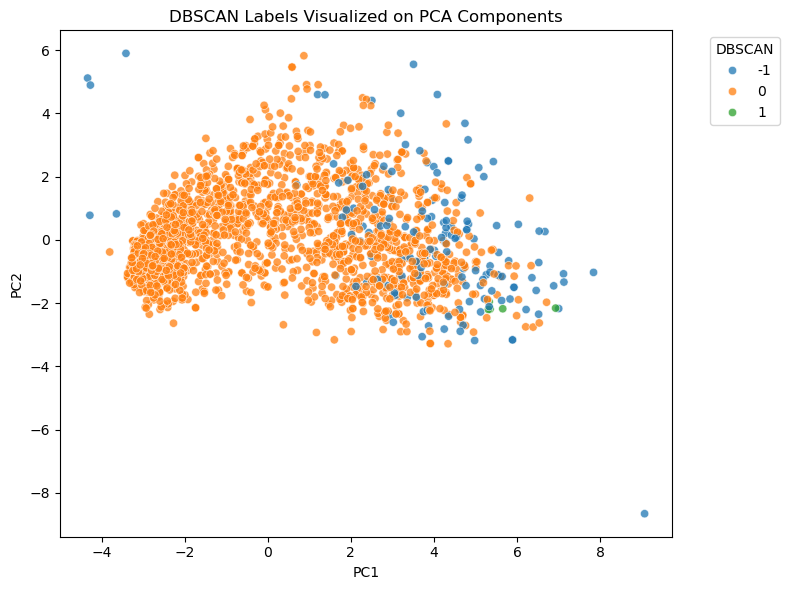

In [34]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

# Best DBSCAN configuration from the search results
dbscan_model = DBSCAN(
    eps=3,
    min_samples=5
)

# Fit DBSCAN on PCA features only
dbscan_labels = dbscan_model.fit_predict(pca_features)

# Add labels for profiling and visualization
data_pca["DBSCAN"] = dbscan_labels
data_segments["DBSCAN"] = dbscan_labels

# Check distribution
print(data_segments["DBSCAN"].value_counts().sort_index())

# Visualize clusters
pca_cluster_plot(
    data_pca,
    "DBSCAN",
    "DBSCAN Labels Visualized on PCA Components"
)

### DBSCAN Insights

DBSCAN was tested to identify density-based customer groups and potential outliers. The best configuration produced one dominant cluster, a small number of noise points, and one very small isolated group.

Most customers were assigned to one large cluster, while 149 customers were classified as noise and only 5 customers formed a separate small cluster. This suggests that the customer base does not contain strong density-separated groups in the PCA feature space.

DBSCAN may be useful for detecting unusual or outlier customers, but it is not suitable as the main segmentation model for this project. K-Means and Ward hierarchical clustering provide more balanced and business-interpretable customer segments.

## 13. Gaussian Mixture Model

Gaussian Mixture Models are tested because they allow softer and more flexible cluster shapes than K-Means.

In [35]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

# Keep only PCA component columns
pca_features = get_pca_features(data_pca)

gmm_results = []

for n in [2, 3, 4, 5]:
    gmm_model = GaussianMixture(
        n_components=n,
        random_state=RANDOM_STATE
    )
    
    labels = gmm_model.fit_predict(pca_features)
    
    gmm_results.append({
        "n_components": n,
        "silhouette": silhouette_score(pca_features, labels),
        "calinski_harabasz": calinski_harabasz_score(pca_features, labels),
        "davies_bouldin": davies_bouldin_score(pca_features, labels),
        "bic": gmm_model.bic(pca_features),
        "aic": gmm_model.aic(pca_features)
    })

gmm_results = pd.DataFrame(gmm_results)
gmm_results

,n_components,silhouette,calinski_harabasz,davies_bouldin,bic,aic
0,2,0.30,986.35,1.32,-225.93,"-2,173.26"
1,3,0.17,645.98,1.78,"-9,494.99","-12,418.85"
2,4,0.15,476.51,2.39,"-12,673.57","-16,573.94"
3,5,0.13,405.29,2.62,"-14,343.81","-19,220.71"


### Gaussian Mixture Model Results

GMM was tested with 2 to 5 components. Based on silhouette score, Calinski-Harabasz, and Davies-Bouldin, the 2-component solution performed best, showing the clearest separation between groups.

Although AIC and BIC improved as the number of components increased, the additional components reduced cluster separation and made the segmentation less clear. Therefore, GMM was not selected as the final segmentation model.

Overall, GMM can model customer distribution flexibly, but in this case K-Means and Ward hierarchical clustering produced more interpretable and business-actionable segments.

GMM silhouette score: 0.3015
GMM_2
0    1143
1    1089
Name: count, dtype: int64


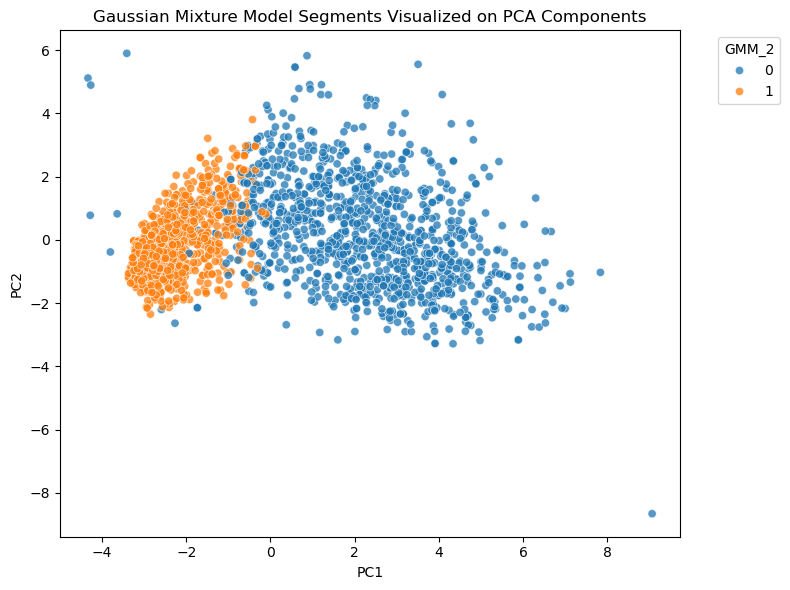

In [36]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

gmm_model = GaussianMixture(
    n_components=2,
    random_state=RANDOM_STATE
)

gmm_labels = gmm_model.fit_predict(pca_features)

gmm_score = silhouette_score(pca_features, gmm_labels)

data_pca["GMM_2"] = gmm_labels
data_segments["GMM_2"] = gmm_labels

print(f"GMM silhouette score: {gmm_score:.4f}")
print(data_segments["GMM_2"].value_counts().sort_index())

pca_cluster_plot(
    data_pca,
    "GMM_2",
    "Gaussian Mixture Model Segments Visualized on PCA Components"
)

In [37]:
gmm_profile = profile_clusters(data_segments, "GMM_2")
gmm_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,customer_count
GMM_2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,583.86","1,967.27","66,747.76",0.14,0.50,49.45,537.05,47.29,302.63,67.44,48.77,71.97,2.46,5.73,4.64,8.05,4.31,0.08,0.13,0.14,0.12,0.02,0.01,0.20,48.73,0.64,1.64,2.28,"1,075.16",20.88,0.70,569.93,54.30,0.55,0.42,0.01,-0.13,1143
1,"5,585.74","1,970.62","36,321.53",0.76,0.52,48.72,60.76,4.31,25.22,6.29,4.41,14.77,2.19,2.38,0.60,3.45,6.37,0.07,0.02,0.00,0.00,0.00,0.01,0.09,45.38,1.28,1.65,2.93,115.75,8.62,0.18,508.60,11.31,1.91,1.88,0.00,0.00,1089


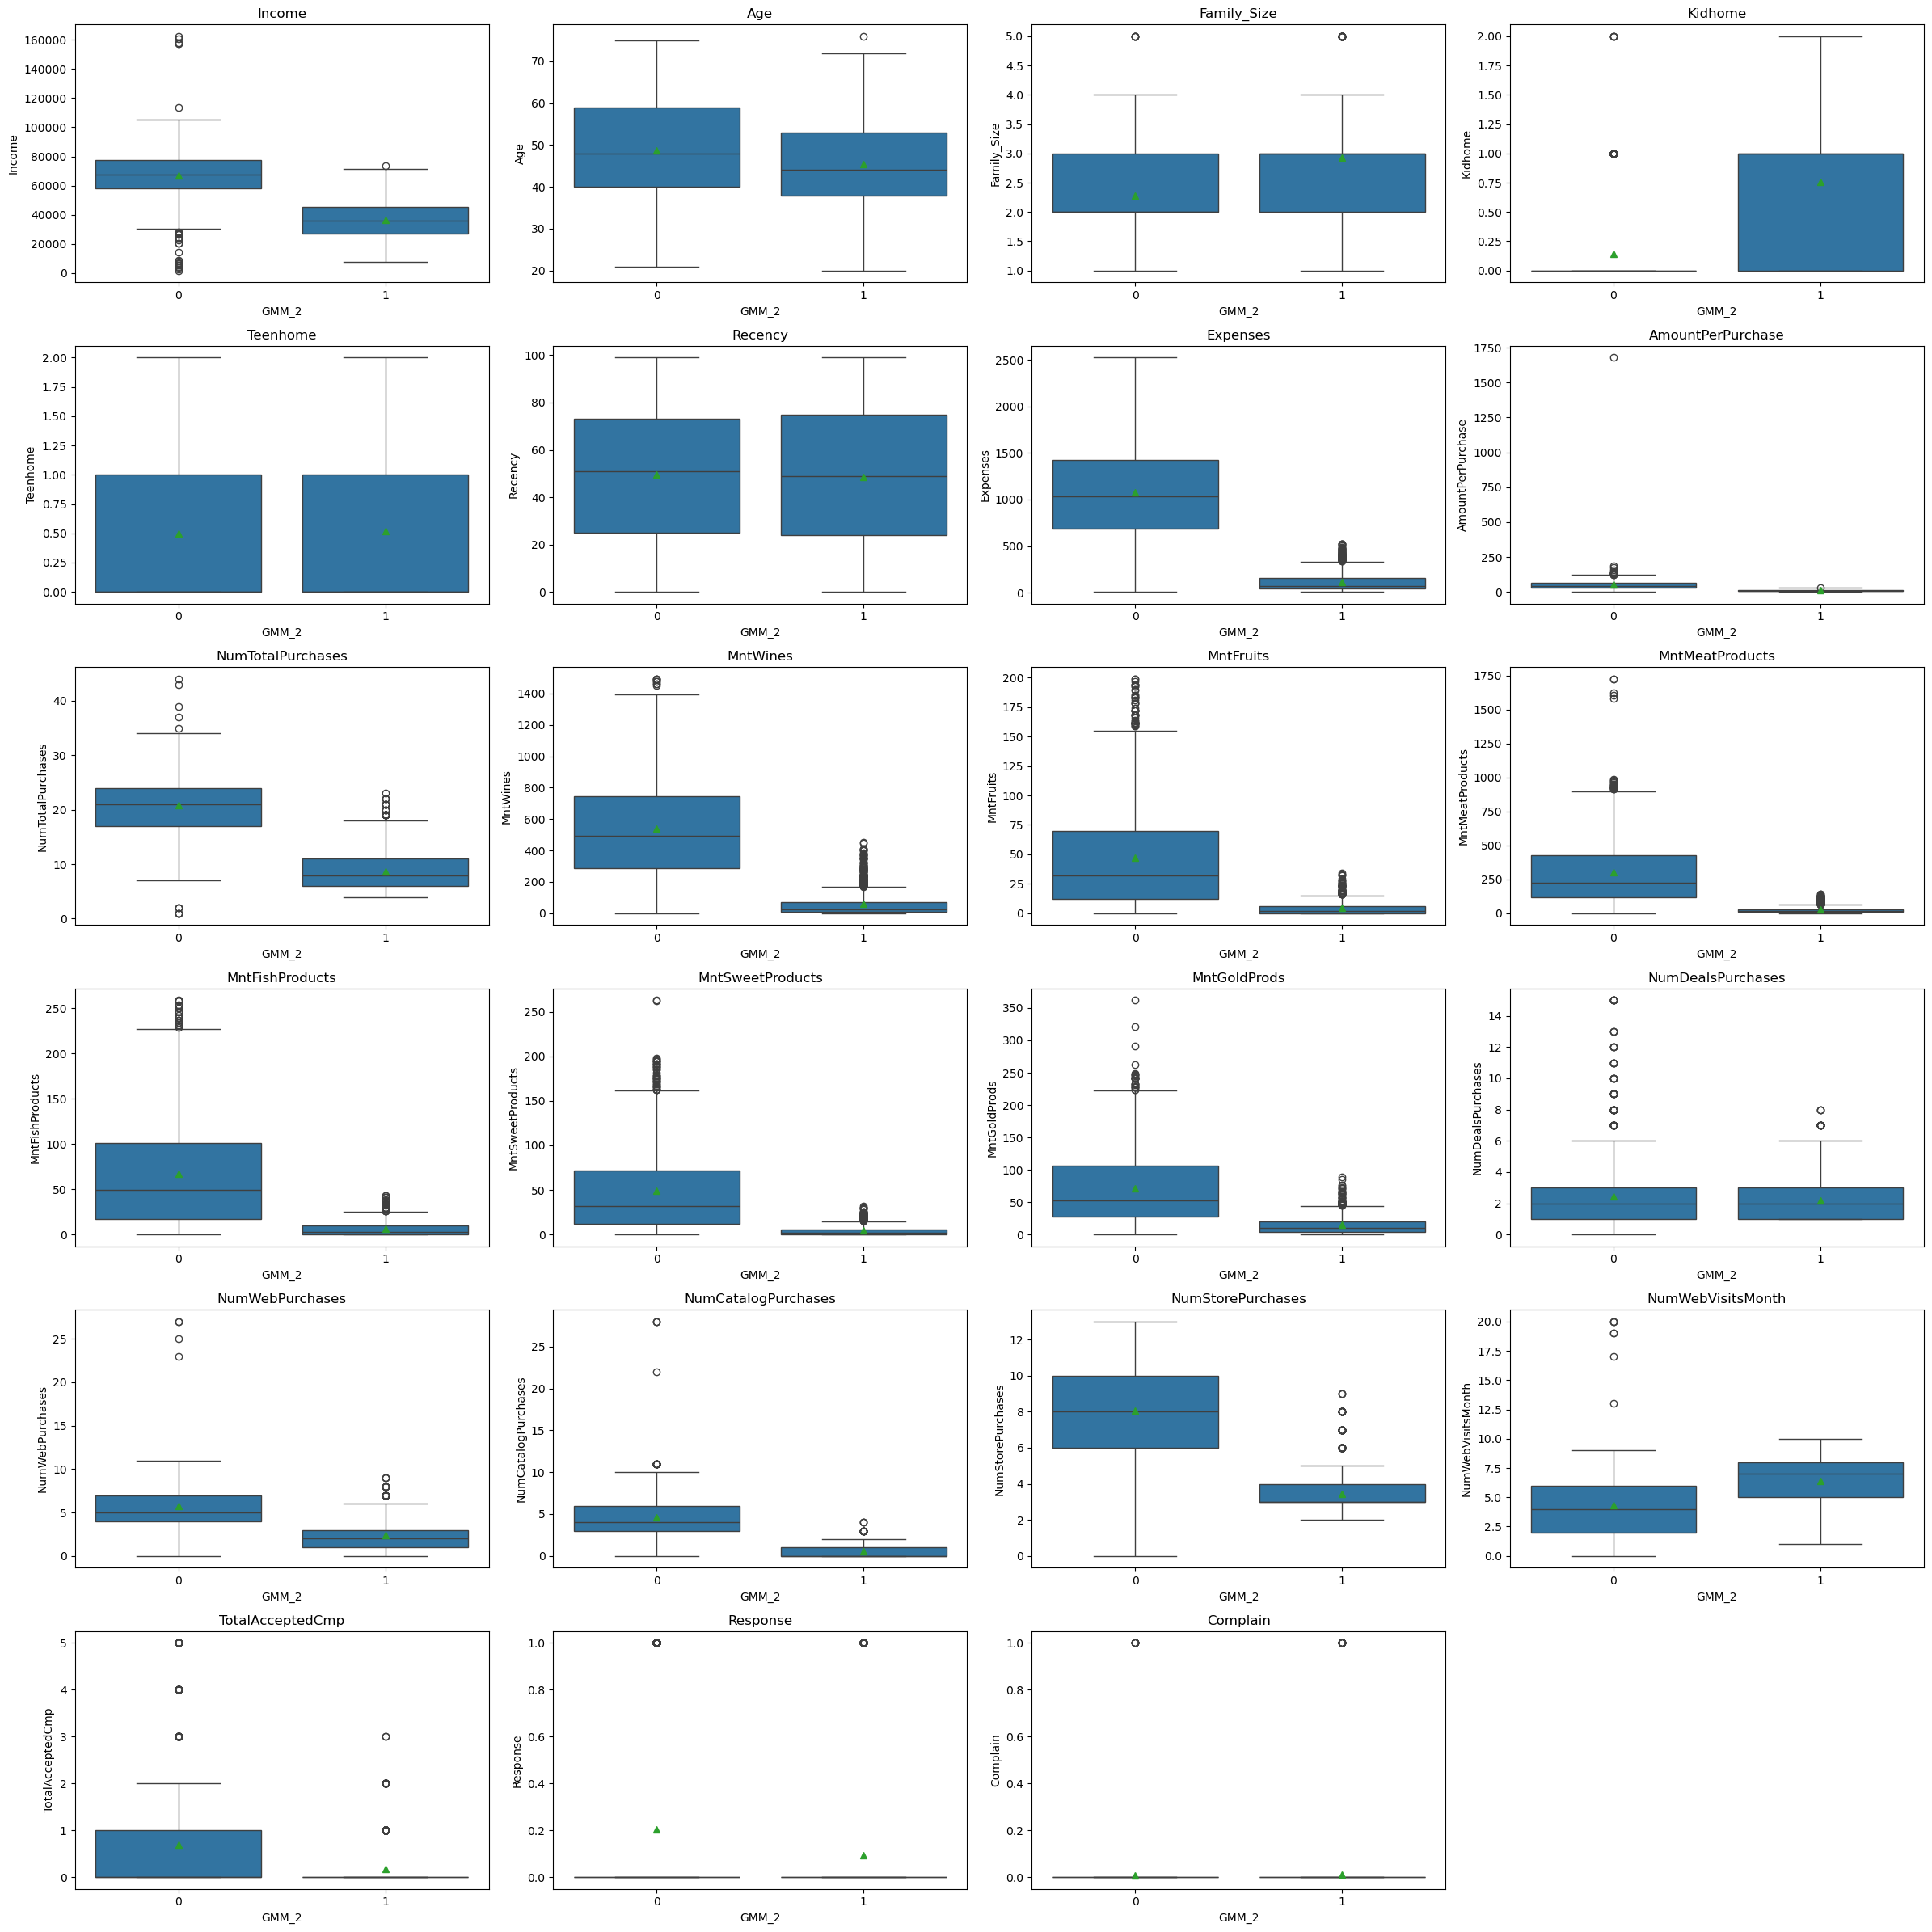

In [38]:
# Boxplot profiling for GMM 2-component solution
plot_cluster_boxplots(
    data_segments,
    "GMM_2",
    PROFILE_COLUMNS
)

### GMM Cluster Insights and Business Interpretation

The 2-component Gaussian Mixture Model separates customers into two broad value groups: higher-value customers and lower-value customers.

#### Cluster 0: Higher-value customers

Cluster 0 has higher income, higher total expenses, and stronger spending across most product categories, especially wines, meat, fish, sweets, and gold products. These customers also have more total purchases and stronger activity across store, catalog, and web channels.

**Business action:** Prioritize this group for retention, loyalty campaigns, personalized offers, premium bundles, and cross-selling. These customers already show strong value, so the goal is to protect and increase their long-term value.

#### Cluster 1: Lower-value customers

Cluster 1 has lower income, lower expenses, and much weaker spending across product categories. These customers also have fewer total purchases and lower store, catalog, and web activity.

**Business action:** Use low-cost reactivation campaigns, simple discounts, and automated email offers. Marketing spend should be controlled because this group has lower commercial value.

### Overall Interpretation

GMM provides a clear high-level split between low-value and high-value customers. It is useful as a benchmark model, but it is less detailed than K-Means or Ward hierarchical clustering because it does not create separate medium-value or deal-oriented segments.

## 14. Bisecting K-Means

To check the robustness of the customer segmentation, I tested Bisecting K-Means as an additional clustering model.

Bisecting K-Means is related to standard K-Means, but instead of directly splitting the data into K clusters, it starts with one cluster and repeatedly splits clusters into smaller groups. This can sometimes create more structured and stable segments.

The model was compared against standard K-Means using the same PCA-transformed feature space. The comparison included silhouette score, Calinski-Harabasz score, Davies-Bouldin score, inertia, cluster size distribution, and business interpretability.

The purpose of this step is to check whether a different K-Means-based approach produces similar or better customer segments.

In [39]:
# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

if BISECTING_KMEANS_AVAILABLE:
    # Fit Bisecting K-Means with 3 clusters
    bisecting_model = BisectingKMeans(
        n_clusters=3,
        random_state=RANDOM_STATE
    )

    bisecting_labels = bisecting_model.fit_predict(pca_features)

    # Add labels for visualization and profiling
    data_pca["BisectingKMeans_3"] = bisecting_labels
    data_segments["BisectingKMeans_3"] = bisecting_labels

    # Check cluster distribution
    print(data_segments["BisectingKMeans_3"].value_counts().sort_index())

    # Calculate silhouette score
    bisecting_score = silhouette_score(pca_features, bisecting_labels)
    print(f"Bisecting K-Means silhouette score: {bisecting_score:.4f}")
else:
    print("Bisecting K-Means was skipped because it is not available in this scikit-learn version.")


BisectingKMeans_3
0     468
1     453
2    1311
Name: count, dtype: int64
Bisecting K-Means silhouette score: 0.2951


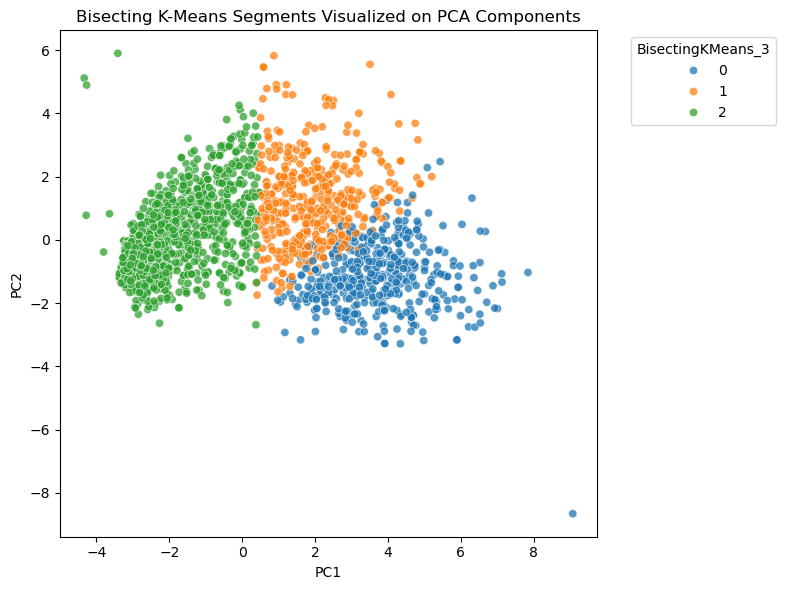

In [40]:
if "BisectingKMeans_3" in data_pca.columns:
    pca_cluster_plot(
        data_pca,
        "BisectingKMeans_3",
        "Bisecting K-Means Segments Visualized on PCA Components"
    )
else:
    print("Bisecting K-Means plot skipped.")


In [41]:
if "BisectingKMeans_3" in data_segments.columns:
    bisecting_profile = profile_clusters(data_segments, "BisectingKMeans_3")
    display(bisecting_profile.round(2))
else:
    print("Bisecting K-Means profile skipped.")


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,customer_count
BisectingKMeans_3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,649.53","1,968.53","77,811.31",0.03,0.13,50.20,626.11,70.61,505.90,107.11,73.41,77.59,1.20,4.82,6.25,8.08,2.51,0.08,0.14,0.29,0.24,0.03,0.00,0.31,47.47,0.16,1.62,1.78,"1,460.74",20.35,1.09,528.56,77.50,0.00,0.03,0.02,-0.21,0.00,468
1,"5,452.28","1,965.83","63,480.44",0.17,0.76,48.59,585.14,37.89,200.16,46.46,39.33,74.04,3.25,6.92,4.21,9.09,5.22,0.09,0.13,0.05,0.06,0.02,0.01,0.15,50.17,0.93,1.64,2.58,983.02,23.48,0.50,612.13,42.95,0.78,0.48,0.00,-0.09,0.00,453
2,"5,607.45","1,970.10","38,653.32",0.69,0.55,48.88,93.01,6.51,35.04,9.73,6.39,21.73,2.42,2.86,0.86,3.86,6.35,0.06,0.03,0.00,0.01,0.00,0.01,0.09,45.90,1.24,1.66,2.90,172.41,9.99,0.20,519.17,14.23,1.79,1.75,0.00,-0.00,0.83,1311


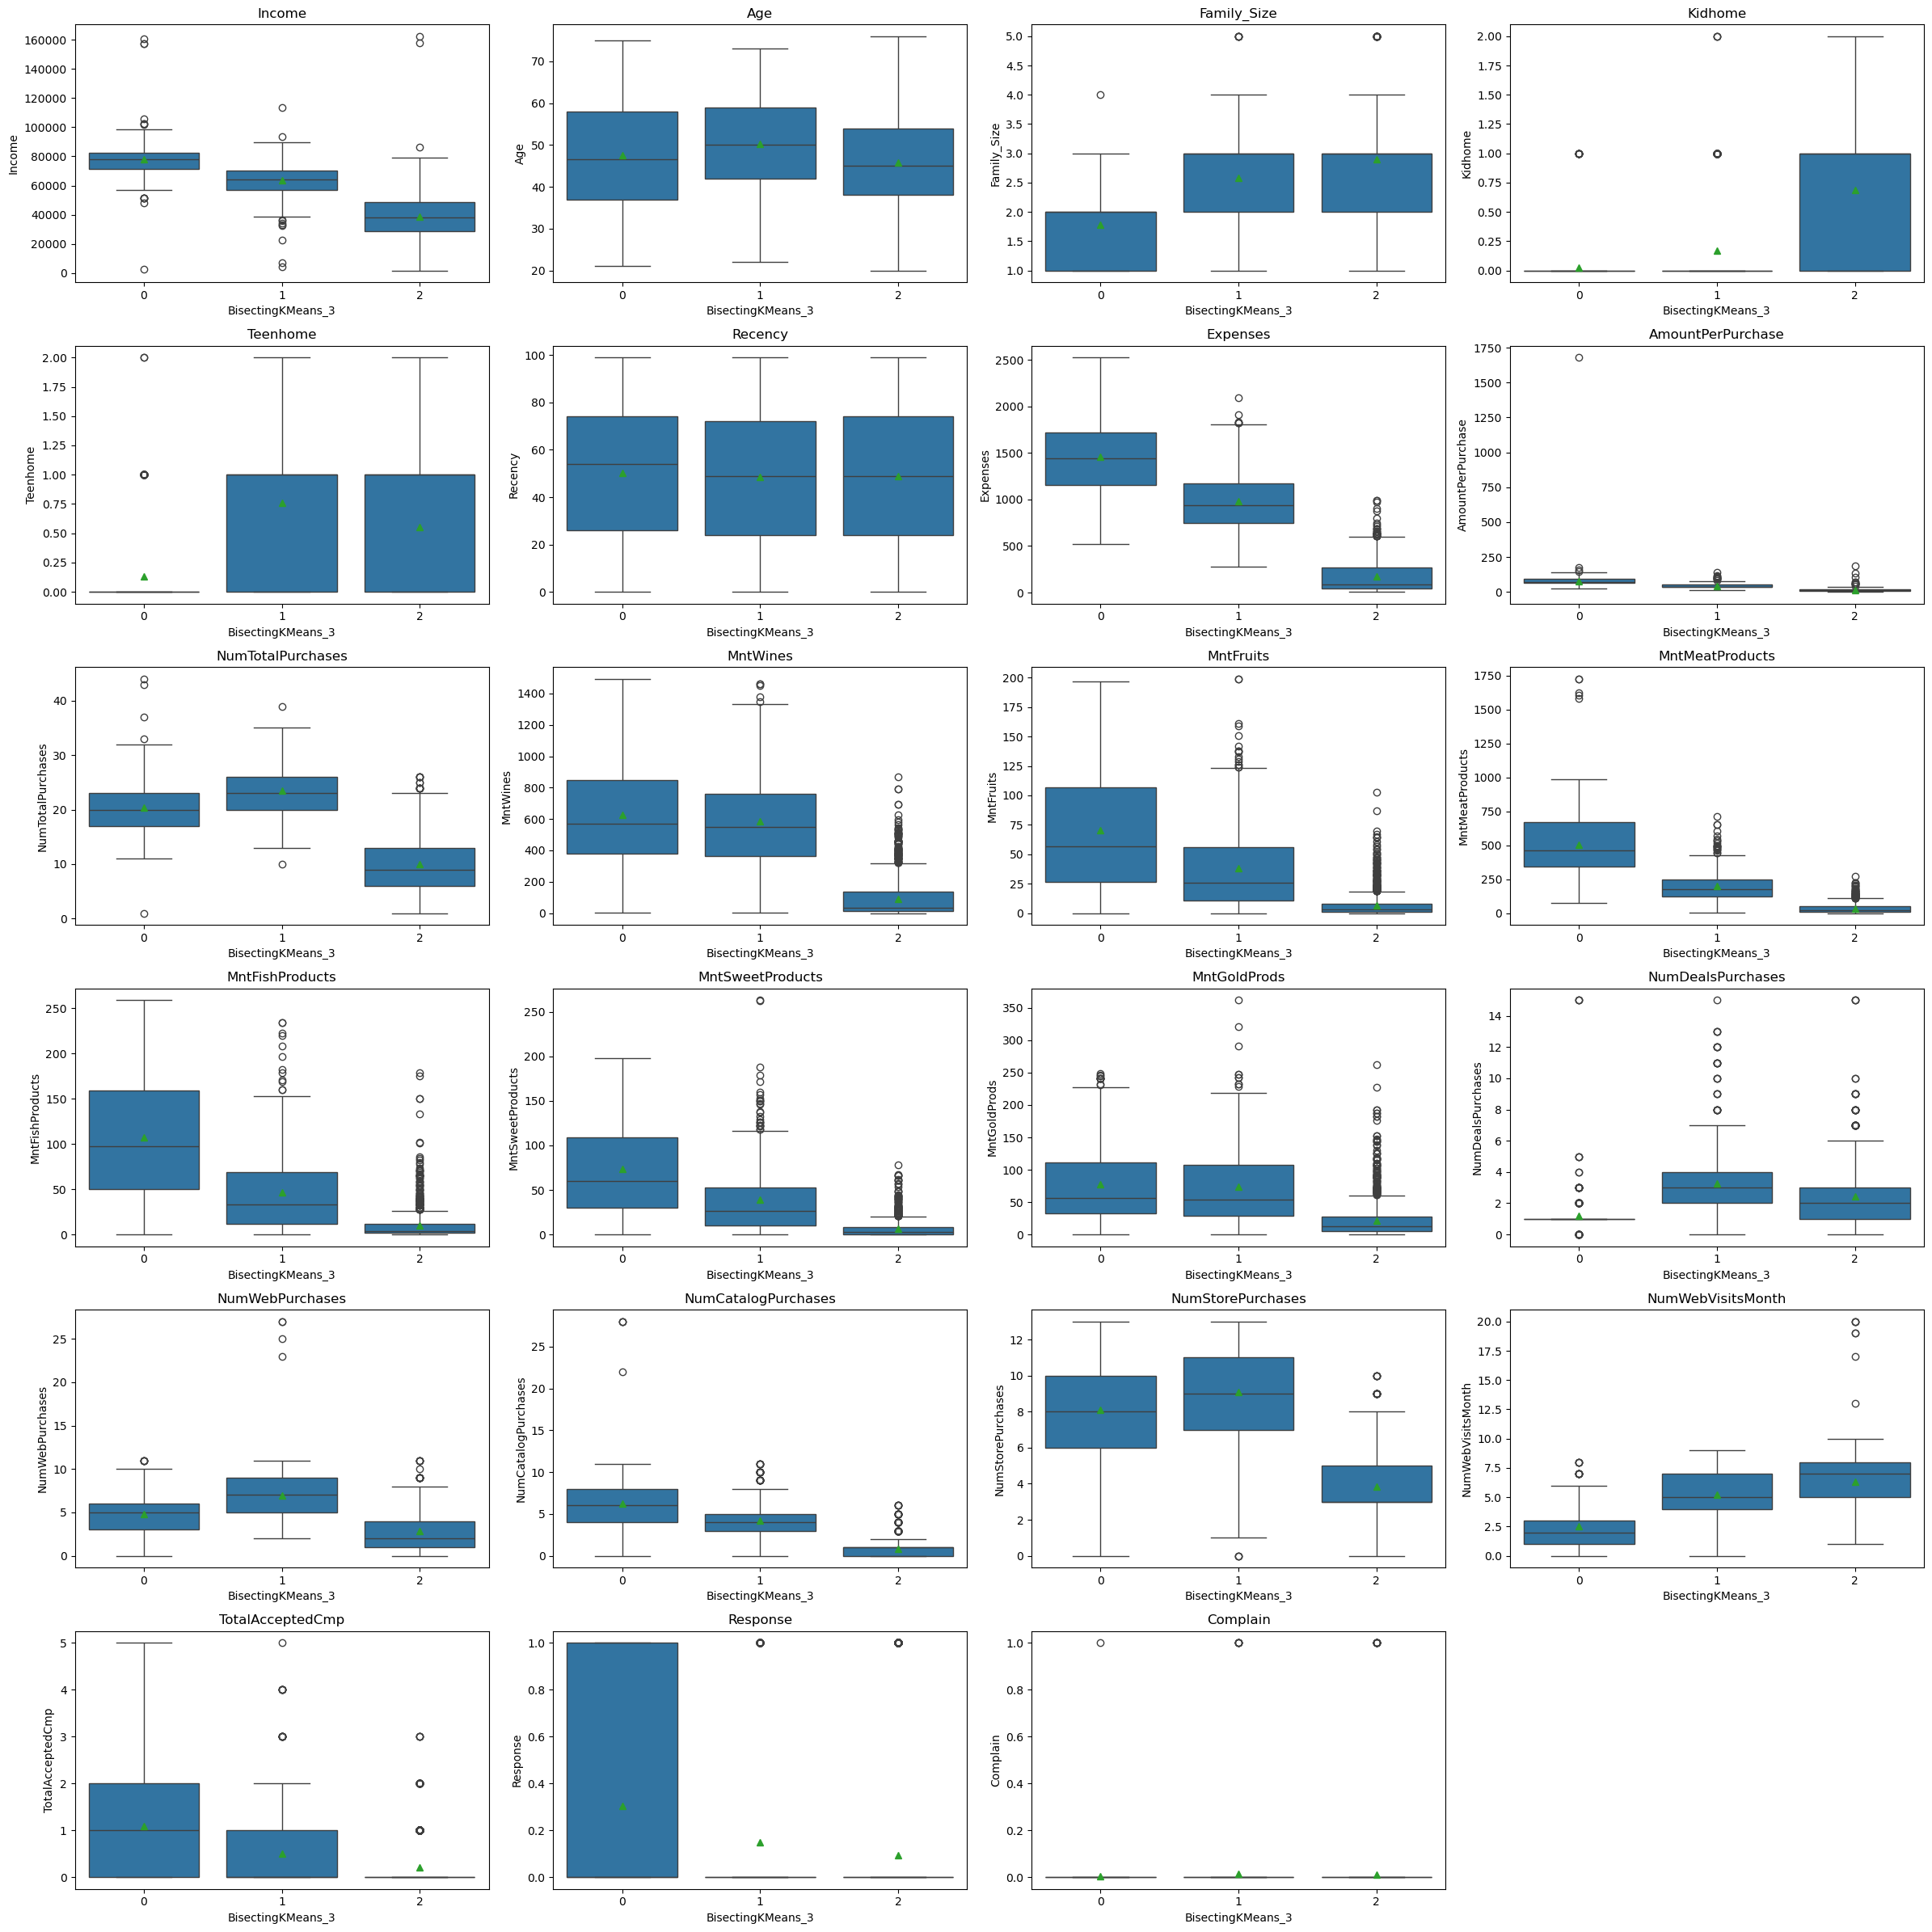

In [42]:
if "BisectingKMeans_3" in data_segments.columns:
    plot_cluster_boxplots(
        data_segments,
        "BisectingKMeans_3",
        PROFILE_COLUMNS
    )
else:
    print("Bisecting K-Means boxplots skipped.")


### Bisecting K-Means Business Insights

Bisecting K-Means produced three clear customer groups with a strong value-based structure.

#### Cluster 0: High-value customers

These customers have the highest income, highest expenses, and strongest spending across most product categories. They also show high total purchases and strong activity across store, catalog, and web channels.

**Business recommendation:** Prioritize this group for loyalty programs, premium bundles, personalized offers, and retention campaigns.

#### Cluster 1: Medium-value active customers

These customers have moderate-to-high income, solid expenses, and strong purchase activity. They buy frequently, especially through store and web channels, but their total spending is lower than Cluster 0.

**Business recommendation:** Use cross-selling, upselling, product bundles, and category-specific campaigns to move them closer to the high-value segment.

#### Cluster 2: Low-value / low-engagement customers

These customers have the lowest income, lowest expenses, and weakest product spending. They also have fewer total purchases and lower activity across most purchase channels.

**Business recommendation:** Use low-cost reactivation campaigns, simple discounts, and automated emails. Avoid heavy marketing investment unless they show signs of reactivation.

### Overall Interpretation

Bisecting K-Means gives a practical segmentation into high-value, medium-value, and low-value customers. The main business opportunity is to retain Cluster 0, grow Cluster 1, and reactivate Cluster 2 with controlled marketing spend.

## 15. Bayesian Gaussian Mixture Model

Bayesian Gaussian Mixture Model was fitted as an additional probabilistic clustering approach. Unlike standard GMM, it can assign very low weights to unnecessary components, which makes it useful for testing whether the data naturally supports fewer or more customer groups.

The model is fitted on the same PCA-transformed feature space used by the other clustering models. The resulting clusters are then profiled using the original customer variables to understand their business meaning.

In [43]:
from sklearn.mixture import BayesianGaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import numpy as np

# Keep only PCA component columns
pca_features = get_pca_features(data_pca)

bgmm_results = []

for n in [2, 3, 4, 5]:
    bgmm_model = BayesianGaussianMixture(
        n_components=n,
        random_state=RANDOM_STATE,
        covariance_type="full"
    )
    
    labels = bgmm_model.fit_predict(pca_features)
    
    n_clusters_used = len(set(labels))
    
    bgmm_results.append({
        "max_components": n,
        "clusters_used": n_clusters_used,
        "silhouette": silhouette_score(pca_features, labels),
        "calinski_harabasz": calinski_harabasz_score(pca_features, labels),
        "davies_bouldin": davies_bouldin_score(pca_features, labels),
        "active_component_weights": np.sum(bgmm_model.weights_ > 0.01)
    })

bgmm_results = pd.DataFrame(bgmm_results)
bgmm_results.round(3)

,max_components,clusters_used,silhouette,calinski_harabasz,davies_bouldin,active_component_weights
0,2,2,0.30,989.22,1.32,2
1,3,3,0.18,665.82,1.81,3
2,4,4,0.16,473.98,2.29,4
3,5,5,0.15,403.44,2.46,5


### Bayesian Gaussian Mixture Model Results

Bayesian Gaussian Mixture Model was tested with 2 to 5 maximum components. The 2-component solution performed best, with the highest silhouette score, highest Calinski-Harabasz score, and lowest Davies-Bouldin score.

As more components were added, the cluster quality decreased. This suggests that Bayesian GMM mainly supports a broad split between lower-value and higher-value customers, rather than a more detailed segmentation.

Therefore, Bayesian GMM is useful as a benchmark model, but it is less actionable than K-Means or Ward hierarchical clustering, which provide more detailed business segments.

BayesianGMM_2
0    1137
1    1095
Name: count, dtype: int64


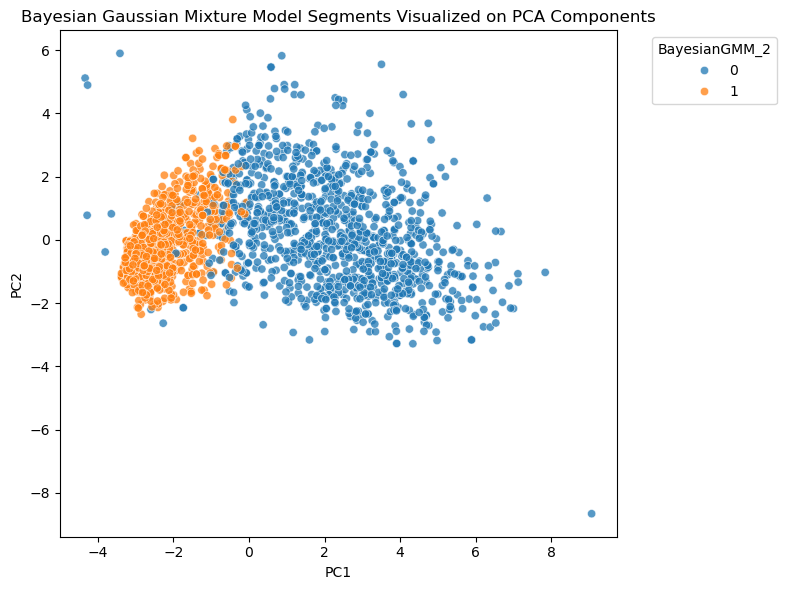

In [44]:
# Fit final Bayesian Gaussian Mixture Model with 2 components

bgmm_final = BayesianGaussianMixture(
    n_components=2,
    random_state=RANDOM_STATE,
    covariance_type="full"
)

bgmm_labels = bgmm_final.fit_predict(pca_features)

data_pca["BayesianGMM_2"] = bgmm_labels
data_segments["BayesianGMM_2"] = bgmm_labels

print(data_segments["BayesianGMM_2"].value_counts().sort_index())

pca_cluster_plot(
    data_pca,
    "BayesianGMM_2",
    "Bayesian Gaussian Mixture Model Segments Visualized on PCA Components"
)

In [45]:
# Profile Bayesian GMM 2-component solution
bgmm_profile = profile_clusters(
    data_segments,
    "BayesianGMM_2"
)

bgmm_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,BisectingKMeans_3,customer_count
BayesianGMM_2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,584.50","1,967.25","66,849.68",0.14,0.49,49.53,538.63,47.49,303.77,67.68,48.94,72.14,2.46,5.73,4.65,8.06,4.30,0.08,0.13,0.14,0.12,0.02,0.01,0.20,48.75,0.64,1.64,2.28,"1,078.67",20.90,0.70,569.47,54.46,0.54,0.42,0.01,-0.13,0.00,0.78,1137
1,"5,585.06","1,970.62","36,382.42",0.76,0.52,48.64,61.73,4.34,25.55,6.37,4.48,14.90,2.20,2.40,0.61,3.46,6.37,0.06,0.02,0.00,0.00,0.00,0.01,0.09,45.38,1.28,1.65,2.93,117.37,8.67,0.18,509.41,11.38,1.91,1.87,0.00,0.00,0.99,2.00,1095


In [ ]:
# Boxplot profiling for Bayesian GMM 2-component solution
plot_cluster_boxplots(
    data_segments,
    "BayesianGMM_2",
    PROFILE_COLUMNS
)

### Bayesian GMM Business Recommendations

The Bayesian GMM 2-component model separates customers into two broad groups: higher-value customers and lower-value customers.

#### Cluster 0: Higher-value customers

Cluster 0 has higher income, higher total expenses, stronger product spending, and more purchases across store, catalog, and web channels. These customers also show stronger campaign acceptance.

**Business recommendation:**  
Prioritize this segment for retention, loyalty rewards, premium bundles, personalized offers, and cross-selling. These customers already generate high value, so the main goal is to protect and increase long-term customer value.

#### Cluster 1: Lower-value customers

Cluster 1 has lower income, lower expenses, weaker product spending, and fewer purchases across most channels. They also show higher web visits but lower purchasing activity, which may indicate browsing without strong conversion.

**Business recommendation:**  
Use low-cost reactivation campaigns, simple discounts, automated emails, and conversion-focused web offers. Avoid expensive personalized campaigns unless customers start showing higher engagement.

### Overall Business Interpretation

Bayesian GMM gives a clear high-level split between high-value and low-value customers. It is useful for broad targeting and budget allocation, but it is less detailed than K-Means or Ward clustering because it does not separate medium-value or deal-oriented customers.

## 61. OPTICS

OPTICS was fitted as an additional density-based clustering model. It is related to DBSCAN, but it is more flexible because it can detect clusters across different density levels.

The model is fitted on the same PCA-transformed feature space used by the other clustering models. The purpose is to check whether a more flexible density-based method can identify meaningful customer groups or mainly detect outliers.

In [46]:
from sklearn.cluster import OPTICS
from sklearn.metrics import silhouette_score
import numpy as np

# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

# Fit OPTICS model
optics_model = OPTICS(
    min_samples=10,
    xi=0.05,
    min_cluster_size=0.05
)

optics_labels = optics_model.fit_predict(pca_features)

# Add labels for visualization and profiling
data_pca["OPTICS"] = optics_labels
data_segments["OPTICS"] = optics_labels

# Check cluster distribution
print(data_segments["OPTICS"].value_counts().sort_index())

OPTICS
0    2232
Name: count, dtype: int64


### OPTICS Insights

OPTICS was tested as a more flexible density-based alternative to DBSCAN. However, with the selected parameters, the model assigned all customers to one single cluster.

This means OPTICS did not identify meaningful density-separated customer groups in the PCA feature space. Since there is only one cluster, cluster profiling and silhouette score are not useful.

Overall, OPTICS was not selected as a final segmentation model. For this dataset, K-Means and Ward hierarchical clustering provide more balanced, interpretable, and business-actionable customer segments.

## 17. BIRCH

BIRCH was fitted as an additional clustering model to test whether a tree-based clustering approach can identify meaningful customer groups.

The model is fitted on the same PCA-transformed feature space used by the other clustering models. The goal is to check whether BIRCH produces balanced and interpretable customer segments compared with K-Means, Ward hierarchical clustering, and GMM.

In [47]:
from sklearn.cluster import Birch
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import numpy as np

pca_features = get_pca_features(data_pca)

birch_results = []

for k in [2, 3, 4, 5]:
    birch_model = Birch(
        n_clusters=k,
        threshold=0.5
    )
    
    labels = birch_model.fit_predict(pca_features)
    n_clusters_found = len(set(labels))
    
    if n_clusters_found > 1:
        silhouette = silhouette_score(pca_features, labels)
        calinski = calinski_harabasz_score(pca_features, labels)
        davies = davies_bouldin_score(pca_features, labels)
    else:
        silhouette = np.nan
        calinski = np.nan
        davies = np.nan
    
    birch_results.append({
        "n_clusters": k,
        "clusters_found": n_clusters_found,
        "silhouette": silhouette,
        "calinski_harabasz": calinski,
        "davies_bouldin": davies
    })

birch_results = pd.DataFrame(birch_results)
birch_results.round(3)

,n_clusters,clusters_found,silhouette,calinski_harabasz,davies_bouldin
0,2,2,0.33,823.40,1.44
1,3,3,0.24,728.30,1.87
2,4,4,0.24,561.82,1.42
3,5,5,0.23,470.09,1.89


### BIRCH Results

BIRCH was tested with 2 to 5 clusters. The 2-cluster solution performed best based on silhouette score and Calinski-Harabasz score, suggesting the clearest separation and strongest cluster structure.

Although the 4-cluster solution had a slightly better Davies-Bouldin score, its other metrics were weaker. Therefore, BIRCH mainly supports a broad two-segment split between lower-value and higher-value customers.

BIRCH is useful as a benchmark model, but it is less detailed than the 3-cluster K-Means and Ward solutions.

BIRCH_2
0    1618
1     614
Name: count, dtype: int64


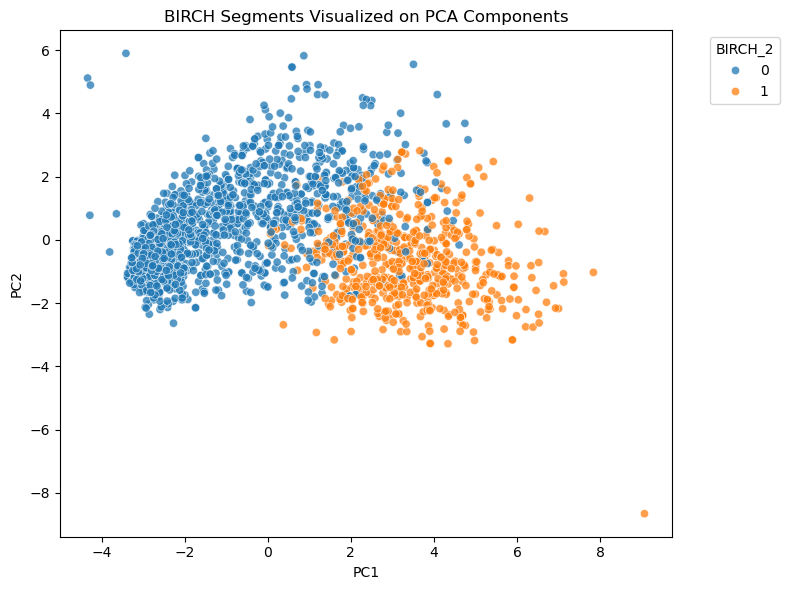

In [48]:
birch_model = Birch(
    n_clusters=2,
    threshold=0.5
)

birch_labels = birch_model.fit_predict(pca_features)

data_pca["BIRCH_2"] = birch_labels
data_segments["BIRCH_2"] = birch_labels

print(data_segments["BIRCH_2"].value_counts().sort_index())

pca_cluster_plot(
    data_pca,
    "BIRCH_2",
    "BIRCH Segments Visualized on PCA Components"
)

In [49]:
# ------------------------------------------------------------
# Profile BIRCH 2-cluster solution
# ------------------------------------------------------------

birch_profile = profile_clusters(
    data_segments,
    "BIRCH_2"
)

birch_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,BisectingKMeans_3,BayesianGMM_2,OPTICS,customer_count
BIRCH_2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,557.49","1,969.08","43,386.56",0.59,0.60,48.90,194.92,9.75,66.52,13.85,10.64,32.39,2.62,3.61,1.52,4.78,6.12,0.07,0.06,0.01,0.02,0.01,0.01,0.10,46.92,1.19,1.65,2.84,328.07,12.53,0.26,533.41,19.88,1.61,1.53,0.00,-0.02,0.67,1.79,0.68,0.00,1618
1,"5,656.69","1,968.43","74,344.27",0.07,0.27,49.62,593.87,69.98,432.79,100.20,70.59,74.81,1.57,5.38,5.68,8.50,3.19,0.08,0.12,0.24,0.19,0.03,0.01,0.27,47.57,0.33,1.63,1.96,"1,342.25",21.13,0.93,557.40,68.75,0.16,0.08,0.01,-0.19,0.00,0.29,0.00,0.00,614


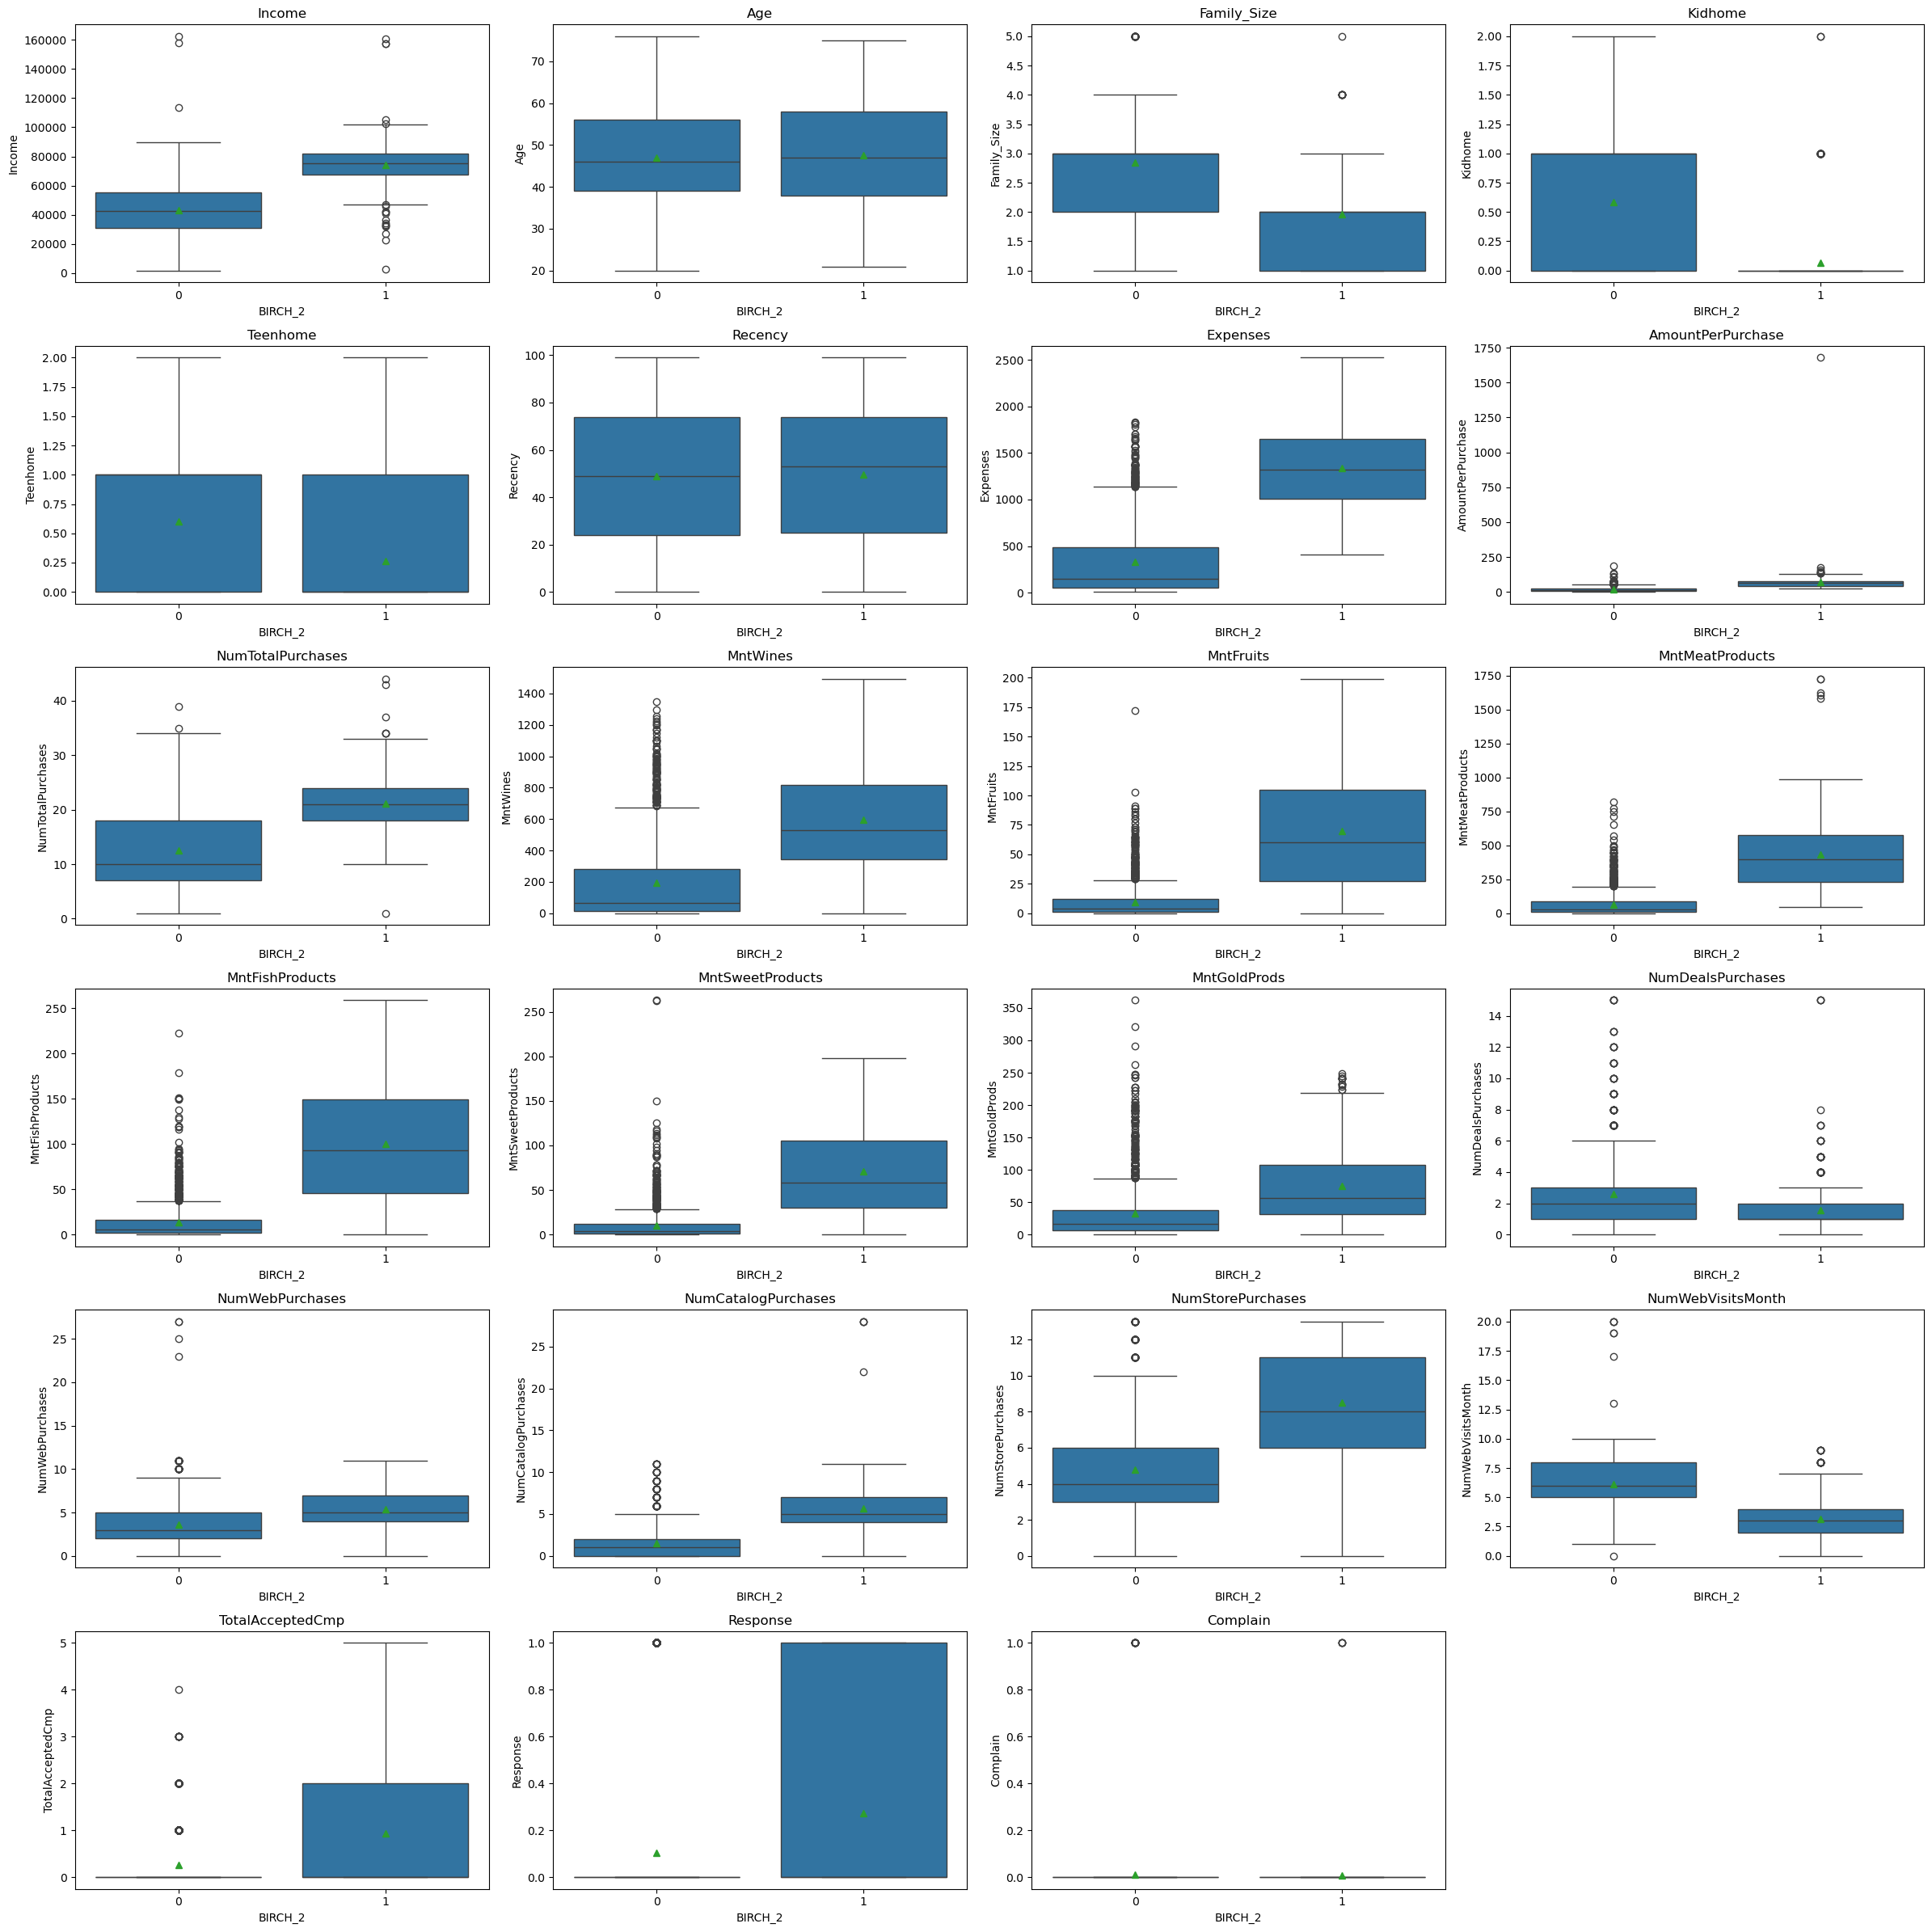

In [50]:
# ------------------------------------------------------------
# Boxplot profiling for BIRCH 2-cluster solution
# ------------------------------------------------------------

plot_cluster_boxplots(
    data_segments,
    "BIRCH_2",
    PROFILE_COLUMNS
)

### BIRCH Business Insights and Recommendations

BIRCH produced a clear 2-cluster segmentation, separating customers into lower-value and higher-value groups.

#### Cluster 0: Lower-value customers

Cluster 0 has lower income, lower total expenses, and weaker spending across most product categories. These customers also have fewer total purchases and lower catalog, store, and web purchase activity. They appear to visit the web channel more often, but this does not translate into strong purchasing behaviour.

**Business recommendation:**  
Use low-cost reactivation campaigns, automated emails, simple discounts, and conversion-focused web offers. Marketing spend should be controlled because this group has lower commercial value.

#### Cluster 1: Higher-value customers

Cluster 1 has higher income, higher total expenses, and stronger spending across wines, meat, fruits, fish, sweets, and gold products. These customers also show more total purchases, stronger store activity, higher catalog purchases, and stronger campaign response.

**Business recommendation:**  
Prioritize this group for retention, loyalty rewards, premium bundles, personalized offers, and cross-selling campaigns. The goal is to protect their value and increase long-term engagement.

### Overall Interpretation

BIRCH provides a useful high-level split between low-value and high-value customers. It is easy to interpret and useful for broad marketing budget allocation, but it is less detailed than the 3-cluster K-Means or Ward solutions because it does not separate a medium-value segment.

## 18.Spectral Clustering

Spectral Clustering was tested as an additional clustering method to check whether the customer data contains non-linear cluster structure.

Unlike K-Means, which separates customers based on distance to cluster centroids, Spectral Clustering uses a similarity graph between observations. This can help identify clusters that are not perfectly spherical.

The model is fitted on the same PCA-transformed feature space used by the other clustering models. Different numbers of clusters are tested and compared using silhouette score, Calinski-Harabasz score, Davies-Bouldin score, cluster size balance, and business interpretability.

In [51]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd
import numpy as np

# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

spectral_results = []

for k in [2, 3, 4, 5, 6, 7]:
    
    spectral_model = SpectralClustering(
        n_clusters=k,
        affinity="nearest_neighbors",
        n_neighbors=10,
        assign_labels="kmeans",
        random_state=RANDOM_STATE
    )
    
    labels = spectral_model.fit_predict(pca_features)
    
    n_clusters_found = len(set(labels))
    
    if n_clusters_found > 1:
        silhouette = silhouette_score(pca_features, labels)
        calinski = calinski_harabasz_score(pca_features, labels)
        davies = davies_bouldin_score(pca_features, labels)
    else:
        silhouette = np.nan
        calinski = np.nan
        davies = np.nan
    
    spectral_results.append({
        "n_clusters": k,
        "clusters_found": n_clusters_found,
        "silhouette": silhouette,
        "calinski_harabasz": calinski,
        "davies_bouldin": davies
    })

spectral_results = pd.DataFrame(spectral_results)

spectral_results.round(3)

,n_clusters,clusters_found,silhouette,calinski_harabasz,davies_bouldin
0,2,2,0.29,974.59,1.29
1,3,3,0.11,566.41,1.69
2,4,4,0.10,443.66,1.58
3,5,5,0.11,433.12,1.57
4,6,6,0.10,352.77,1.59
5,7,7,0.09,295.78,1.59


In [52]:
# Final Spectral Clustering model based on the best metrics

best_spectral_k = 2

spectral_final = SpectralClustering(
    n_clusters=best_spectral_k,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=RANDOM_STATE
)

spectral_labels = spectral_final.fit_predict(pca_features)

data_pca["Spectral_2"] = spectral_labels
data_segments["Spectral_2"] = spectral_labels

print(data_segments["Spectral_2"].value_counts().sort_index())

Spectral_2
0    1016
1    1216
Name: count, dtype: int64


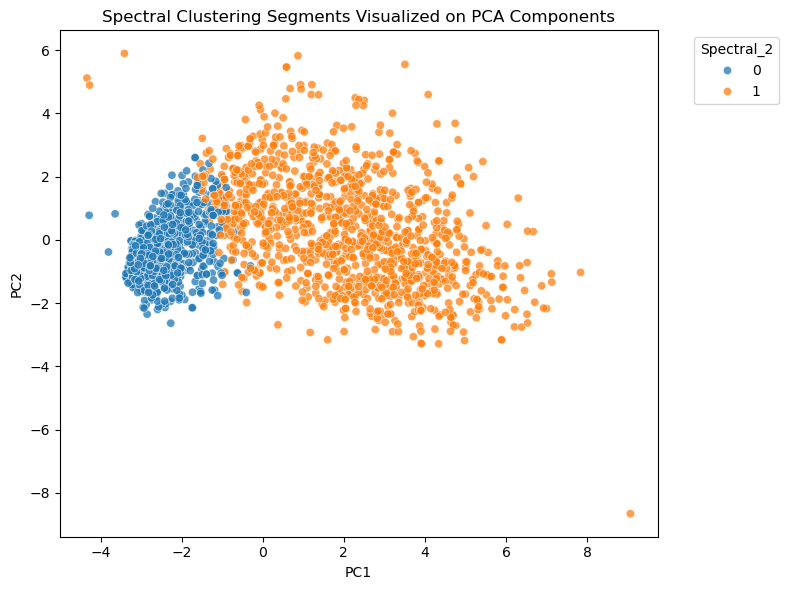

In [53]:
pca_cluster_plot(
    data_pca,
    "Spectral_2",
    "Spectral Clustering Segments Visualized on PCA Components"
)

In [54]:
spectral_profile = profile_clusters(
    data_segments,
    "Spectral_2"
)

spectral_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,BisectingKMeans_3,BayesianGMM_2,OPTICS,BIRCH_2,customer_count
Spectral_2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,569.59","1,971.20","35,017.29",0.78,0.47,49.85,40.71,4.57,21.56,6.40,4.76,14.45,1.98,2.06,0.53,3.20,6.38,0.07,0.01,0.00,0.00,0.00,0.01,0.09,44.80,1.25,1.65,2.90,92.46,7.77,0.17,505.96,10.91,1.99,1.95,0.00,-0.00,0.97,2.00,0.97,0.00,0.00,1016
1,"5,597.46","1,966.99","66,010.91",0.17,0.54,48.47,525.21,44.49,289.03,63.68,45.81,68.80,2.63,5.79,4.45,7.98,4.43,0.08,0.12,0.13,0.12,0.02,0.01,0.20,49.01,0.70,1.64,2.35,"1,037.02",20.86,0.68,568.45,52.05,0.57,0.45,0.01,-0.12,0.09,0.86,0.09,0.00,0.50,1216


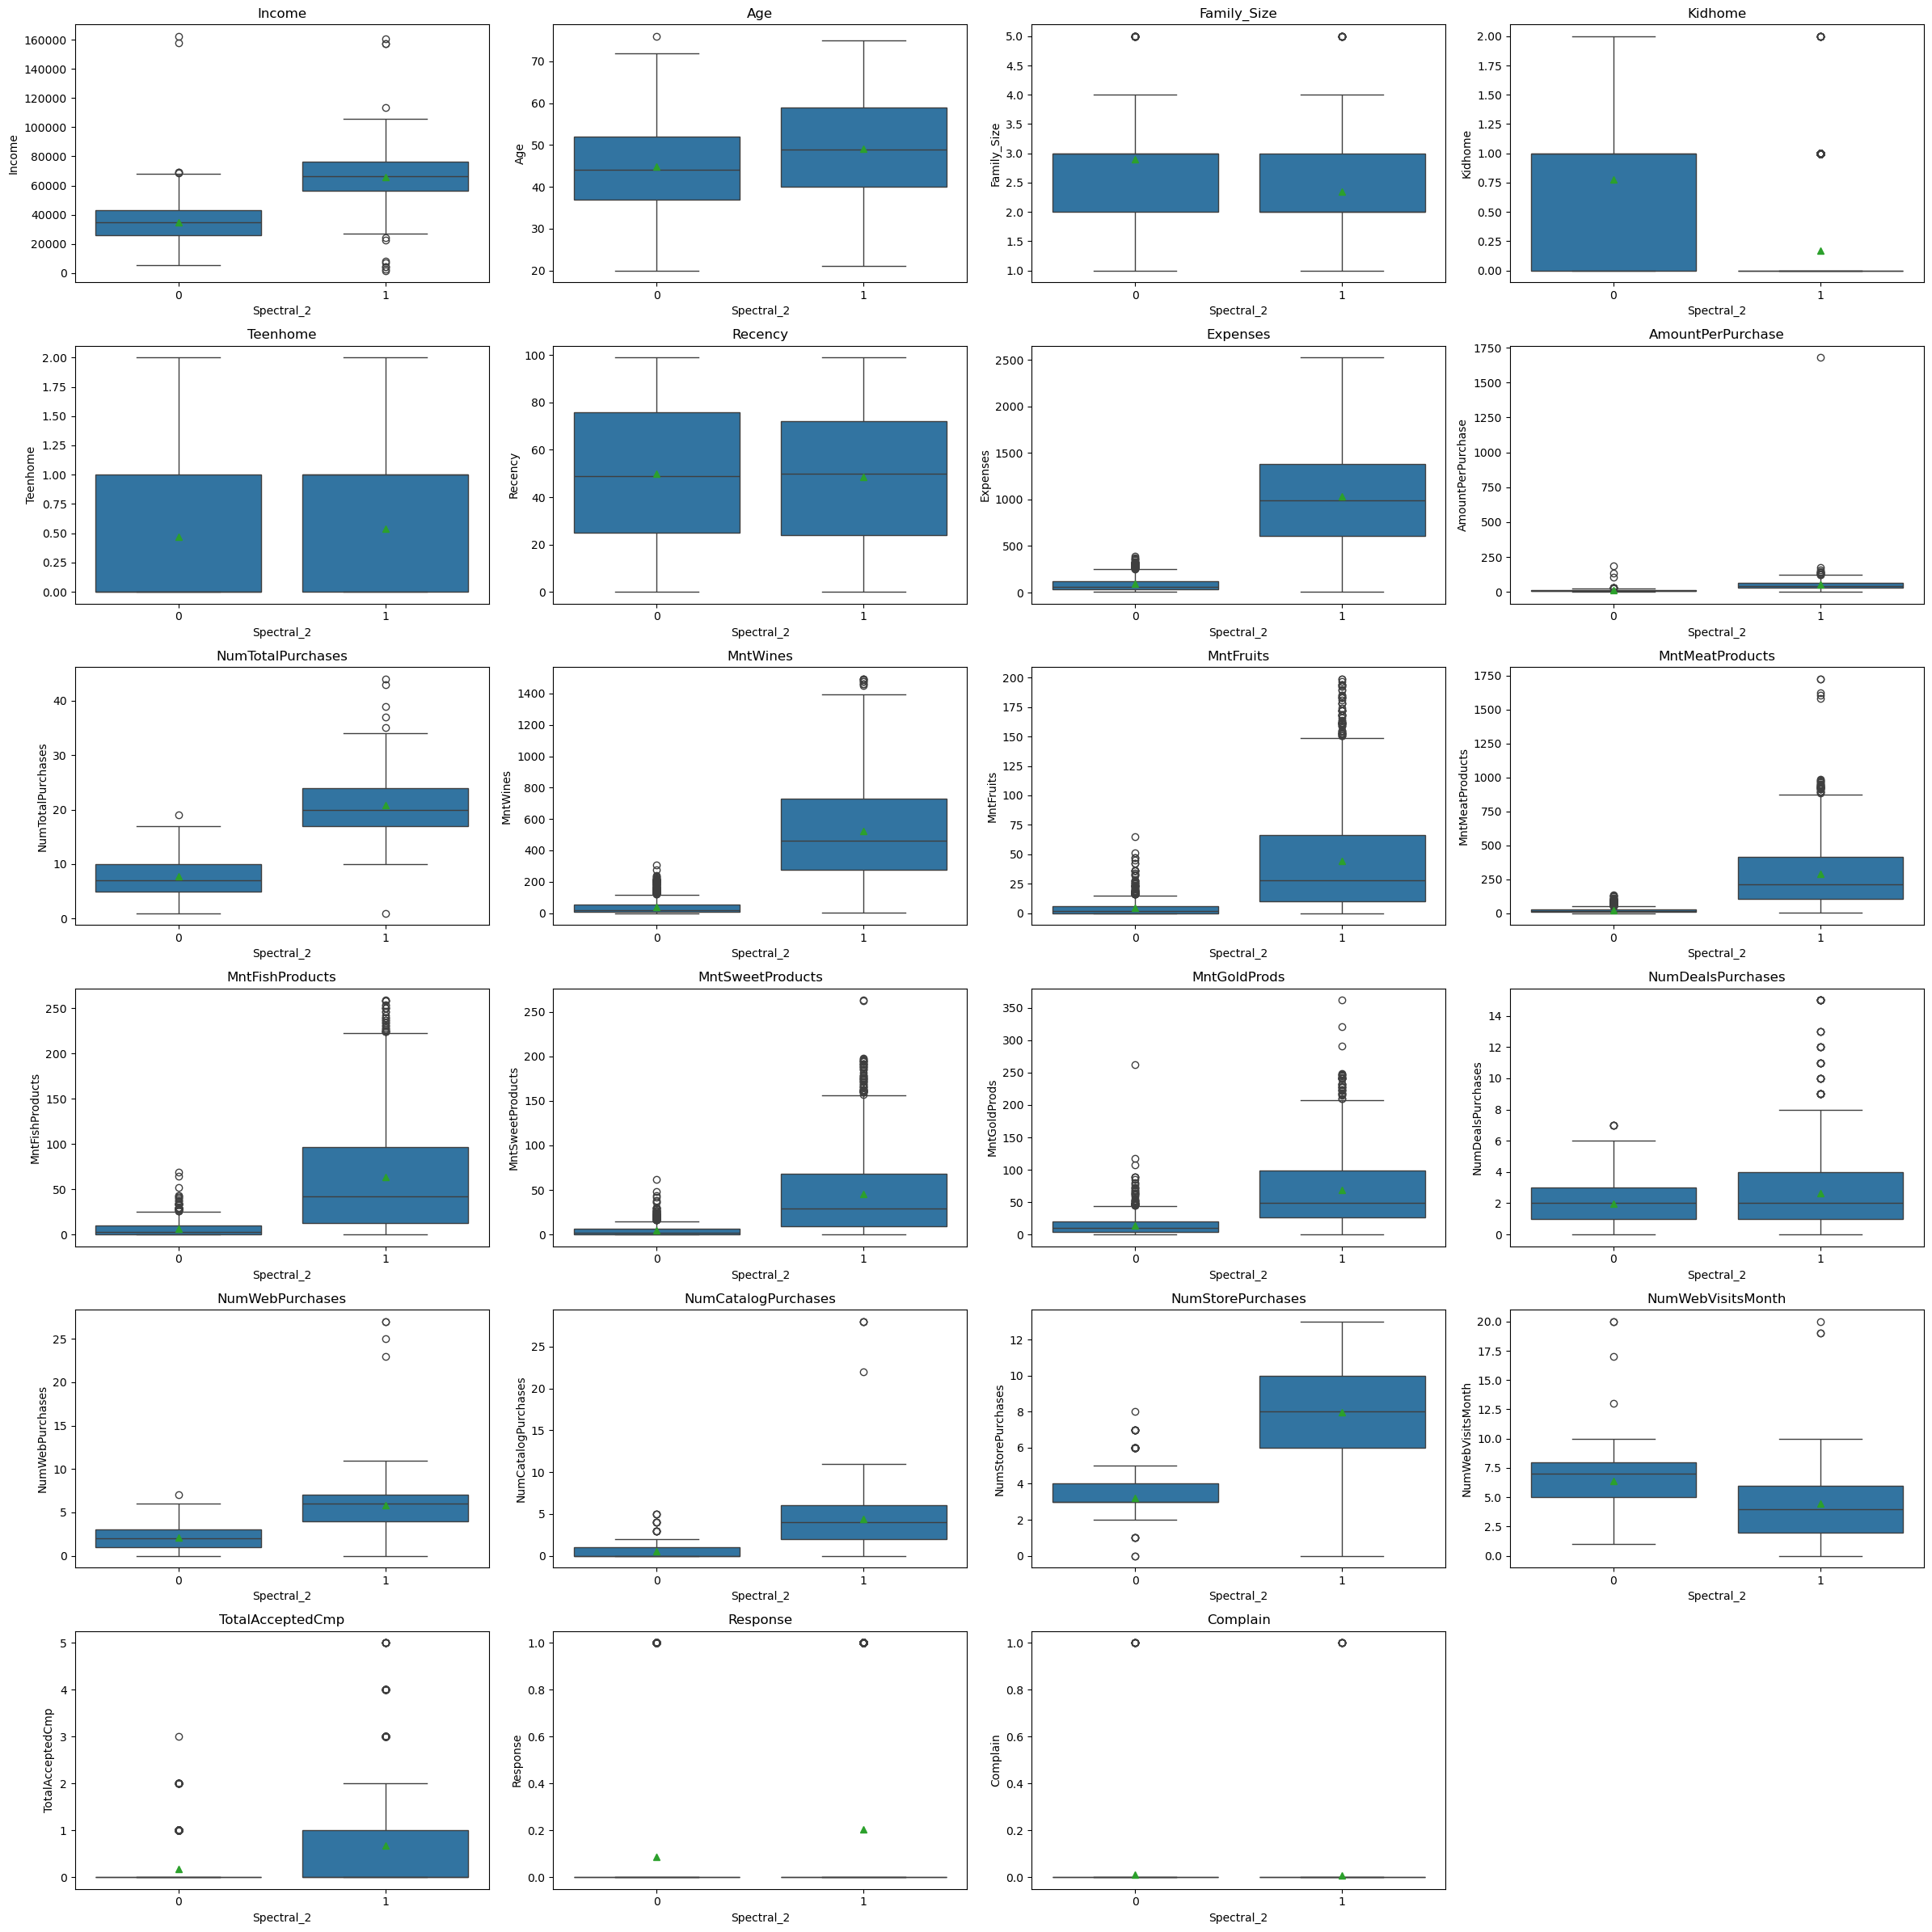

In [55]:
plot_cluster_boxplots(
    data_segments,
    "Spectral_2",
    PROFILE_COLUMNS
)

### Spectral Clustering Business Insights and Recommendations

Spectral Clustering produced a clear 2-cluster segmentation, separating customers mainly into lower-value and higher-value groups.

#### Cluster 0: Lower-value customers

Cluster 0 has lower income, lower expenses, weaker product spending, and fewer purchases across web, catalog, and store channels. These customers show higher web visits, but this does not convert into high purchasing activity.

**Business recommendation:**  
Use low-cost reactivation campaigns, automated emails, simple discounts, and web conversion offers. Marketing spend should be controlled because this group has lower customer value.

#### Cluster 1: Higher-value customers

Cluster 1 has higher income, higher expenses, stronger product spending, and more purchases across all major channels. These customers spend more on wines, meat, fruits, fish, sweets, and gold products, and they show stronger campaign response.

**Business recommendation:**  
Prioritize this group for retention, loyalty programs, premium bundles, personalized offers, and cross-selling campaigns.

### Overall Interpretation

Spectral Clustering gives a useful high-level split between low-value and high-value customers. However, it is less detailed than the 3-cluster K-Means, Ward, or Bisecting K-Means solutions because it does not separate a medium-value segment.

## 19. X-Means

X-Means was fitted as an additional K-Means-based clustering model. Unlike standard K-Means, where the number of clusters must be selected manually, X-Means starts with an initial number of centers and searches for a better number of clusters up to a predefined maximum.

The model is fitted on the same PCA-transformed feature space used by the other clustering methods. The purpose is to check whether the data naturally supports a different number of customer segments.

> X-Means uses the optional `pyclustering` package. If it is not installed, run `pip install pyclustering` once and rerun this section.

In [56]:
import numpy as np
import warnings
np.warnings = warnings  # Compatibility fix for pyclustering with newer NumPy versions.

try:
    from pyclustering.cluster.xmeans import xmeans
    from pyclustering.cluster.center_initializer import kmeans_plusplus_initializer
    XMEANS_AVAILABLE = True
except ImportError:
    XMEANS_AVAILABLE = False
    print("X-Means skipped. Install pyclustering to run this optional benchmark.")

pca_features = get_pca_features(data_pca)
xmeans_results = []

if XMEANS_AVAILABLE:
    xmeans_input = pca_features.values

    for kmax in [3, 4, 5, 6, 8, 10]:
        initial_centers = kmeans_plusplus_initializer(
            xmeans_input,
            2,
            random_state=RANDOM_STATE
        ).initialize()

        xmeans_model = xmeans(
            data=xmeans_input,
            initial_centers=initial_centers,
            kmax=kmax
        )

        xmeans_model.process()
        clusters = xmeans_model.get_clusters()

        labels = np.empty(len(pca_features), dtype=int)

        for cluster_id, cluster_indices in enumerate(clusters):
            labels[cluster_indices] = cluster_id

        xmeans_results.append({
            "kmax": kmax,
            "clusters_found": len(clusters),
            "silhouette": silhouette_score(pca_features, labels),
            "calinski_harabasz": calinski_harabasz_score(pca_features, labels),
            "davies_bouldin": davies_bouldin_score(pca_features, labels)
        })

xmeans_results = pd.DataFrame(xmeans_results)
xmeans_results.round(3)


,kmax,clusters_found,silhouette,calinski_harabasz,davies_bouldin
0,3,3,0.35,579.08,1.04
1,4,4,0.23,603.48,2.10
2,5,5,0.25,474.36,1.88
3,6,6,0.23,424.86,1.56
4,8,8,0.11,344.90,1.72
5,10,10,0.13,274.43,1.59


### X-Means results

X-Means was tested with different `kmax` values to see whether it would settle on a natural number of clusters.

In this run, the model kept reaching the maximum number of clusters allowed. That means it did not give strong evidence for a larger natural segmentation. The best X-Means setting was the 3-cluster version, which matched the low / medium / high value structure found by the other K-Means-based models.


In [57]:
# Fit X-Means with a maximum of 3 clusters.

if XMEANS_AVAILABLE:
    xmeans_input = pca_features.values

    initial_centers = kmeans_plusplus_initializer(
        xmeans_input,
        2,
        random_state=RANDOM_STATE
    ).initialize()

    xmeans_model = xmeans(
        data=xmeans_input,
        initial_centers=initial_centers,
        kmax=3
    )

    xmeans_model.process()
    xmeans_clusters = xmeans_model.get_clusters()

    print(f"Number of clusters found by X-Means: {len(xmeans_clusters)}")
else:
    xmeans_clusters = []
    print("X-Means was not fitted because pyclustering is not installed.")


Number of clusters found by X-Means: 3


In [58]:
if XMEANS_AVAILABLE and len(xmeans_clusters) > 0:
    xmeans_labels = np.empty(len(pca_features), dtype=int)

    for cluster_id, cluster_indices in enumerate(xmeans_clusters):
        xmeans_labels[cluster_indices] = cluster_id

    data_pca["XMeans_3"] = xmeans_labels
    data_segments["XMeans_3"] = xmeans_labels

    print(data_segments["XMeans_3"].value_counts().sort_index())
else:
    print("No X-Means labels available.")


XMeans_3
0    1059
1     610
2     563
Name: count, dtype: int64


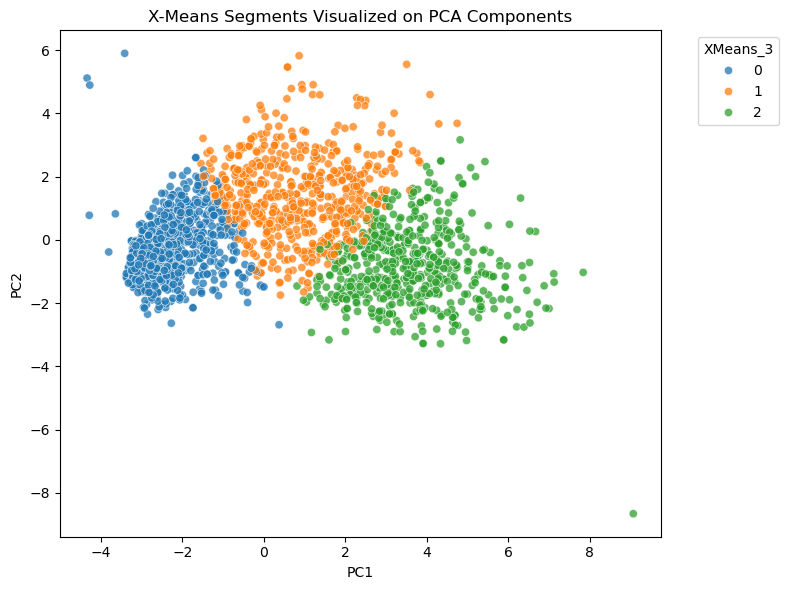

In [59]:
if "XMeans_3" in data_pca.columns:
    pca_cluster_plot(
        data_pca,
        "XMeans_3",
        "X-Means Segments Visualized on PCA Components"
    )
else:
    print("X-Means plot skipped.")


In [60]:
if "XMeans_3" in data_segments.columns:
    xmeans_profile = profile_clusters(
        data_segments,
        "XMeans_3"
    )

    display(xmeans_profile.round(2))
else:
    print("X-Means profile skipped.")


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,BisectingKMeans_3,BayesianGMM_2,OPTICS,BIRCH_2,Spectral_2,customer_count
XMeans_3,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,615.55","1,970.99","35,581.49",0.75,0.48,49.15,45.31,5.13,23.64,7.37,5.19,15.21,2.01,2.13,0.58,3.29,6.36,0.07,0.02,0.00,0.00,0.00,0.01,0.08,45.01,1.23,1.65,2.88,101.86,8.02,0.17,502.10,11.44,1.98,1.92,0.00,-0.01,0.95,2.00,0.95,0.00,0.00,0.05,1059
1,"5,467.48","1,965.97","57,717.52",0.29,0.84,47.87,453.35,23.03,138.84,30.47,24.74,62.23,3.79,6.49,3.10,7.88,5.77,0.07,0.13,0.03,0.04,0.01,0.01,0.14,50.03,1.12,1.66,2.78,732.65,21.26,0.41,596.71,34.31,0.99,0.76,0.00,-0.04,0.14,1.41,0.14,0.00,0.16,0.99,610
2,"5,653.98","1,968.15","76,302.56",0.03,0.21,50.34,631.44,69.74,468.28,102.20,70.98,78.63,1.35,5.18,6.13,8.29,2.87,0.09,0.13,0.26,0.21,0.03,0.01,0.29,47.85,0.24,1.62,1.86,"1,421.27",20.95,1.01,549.87,73.43,0.00,0.04,0.02,-0.20,0.00,0.17,0.00,0.00,0.91,1.00,563


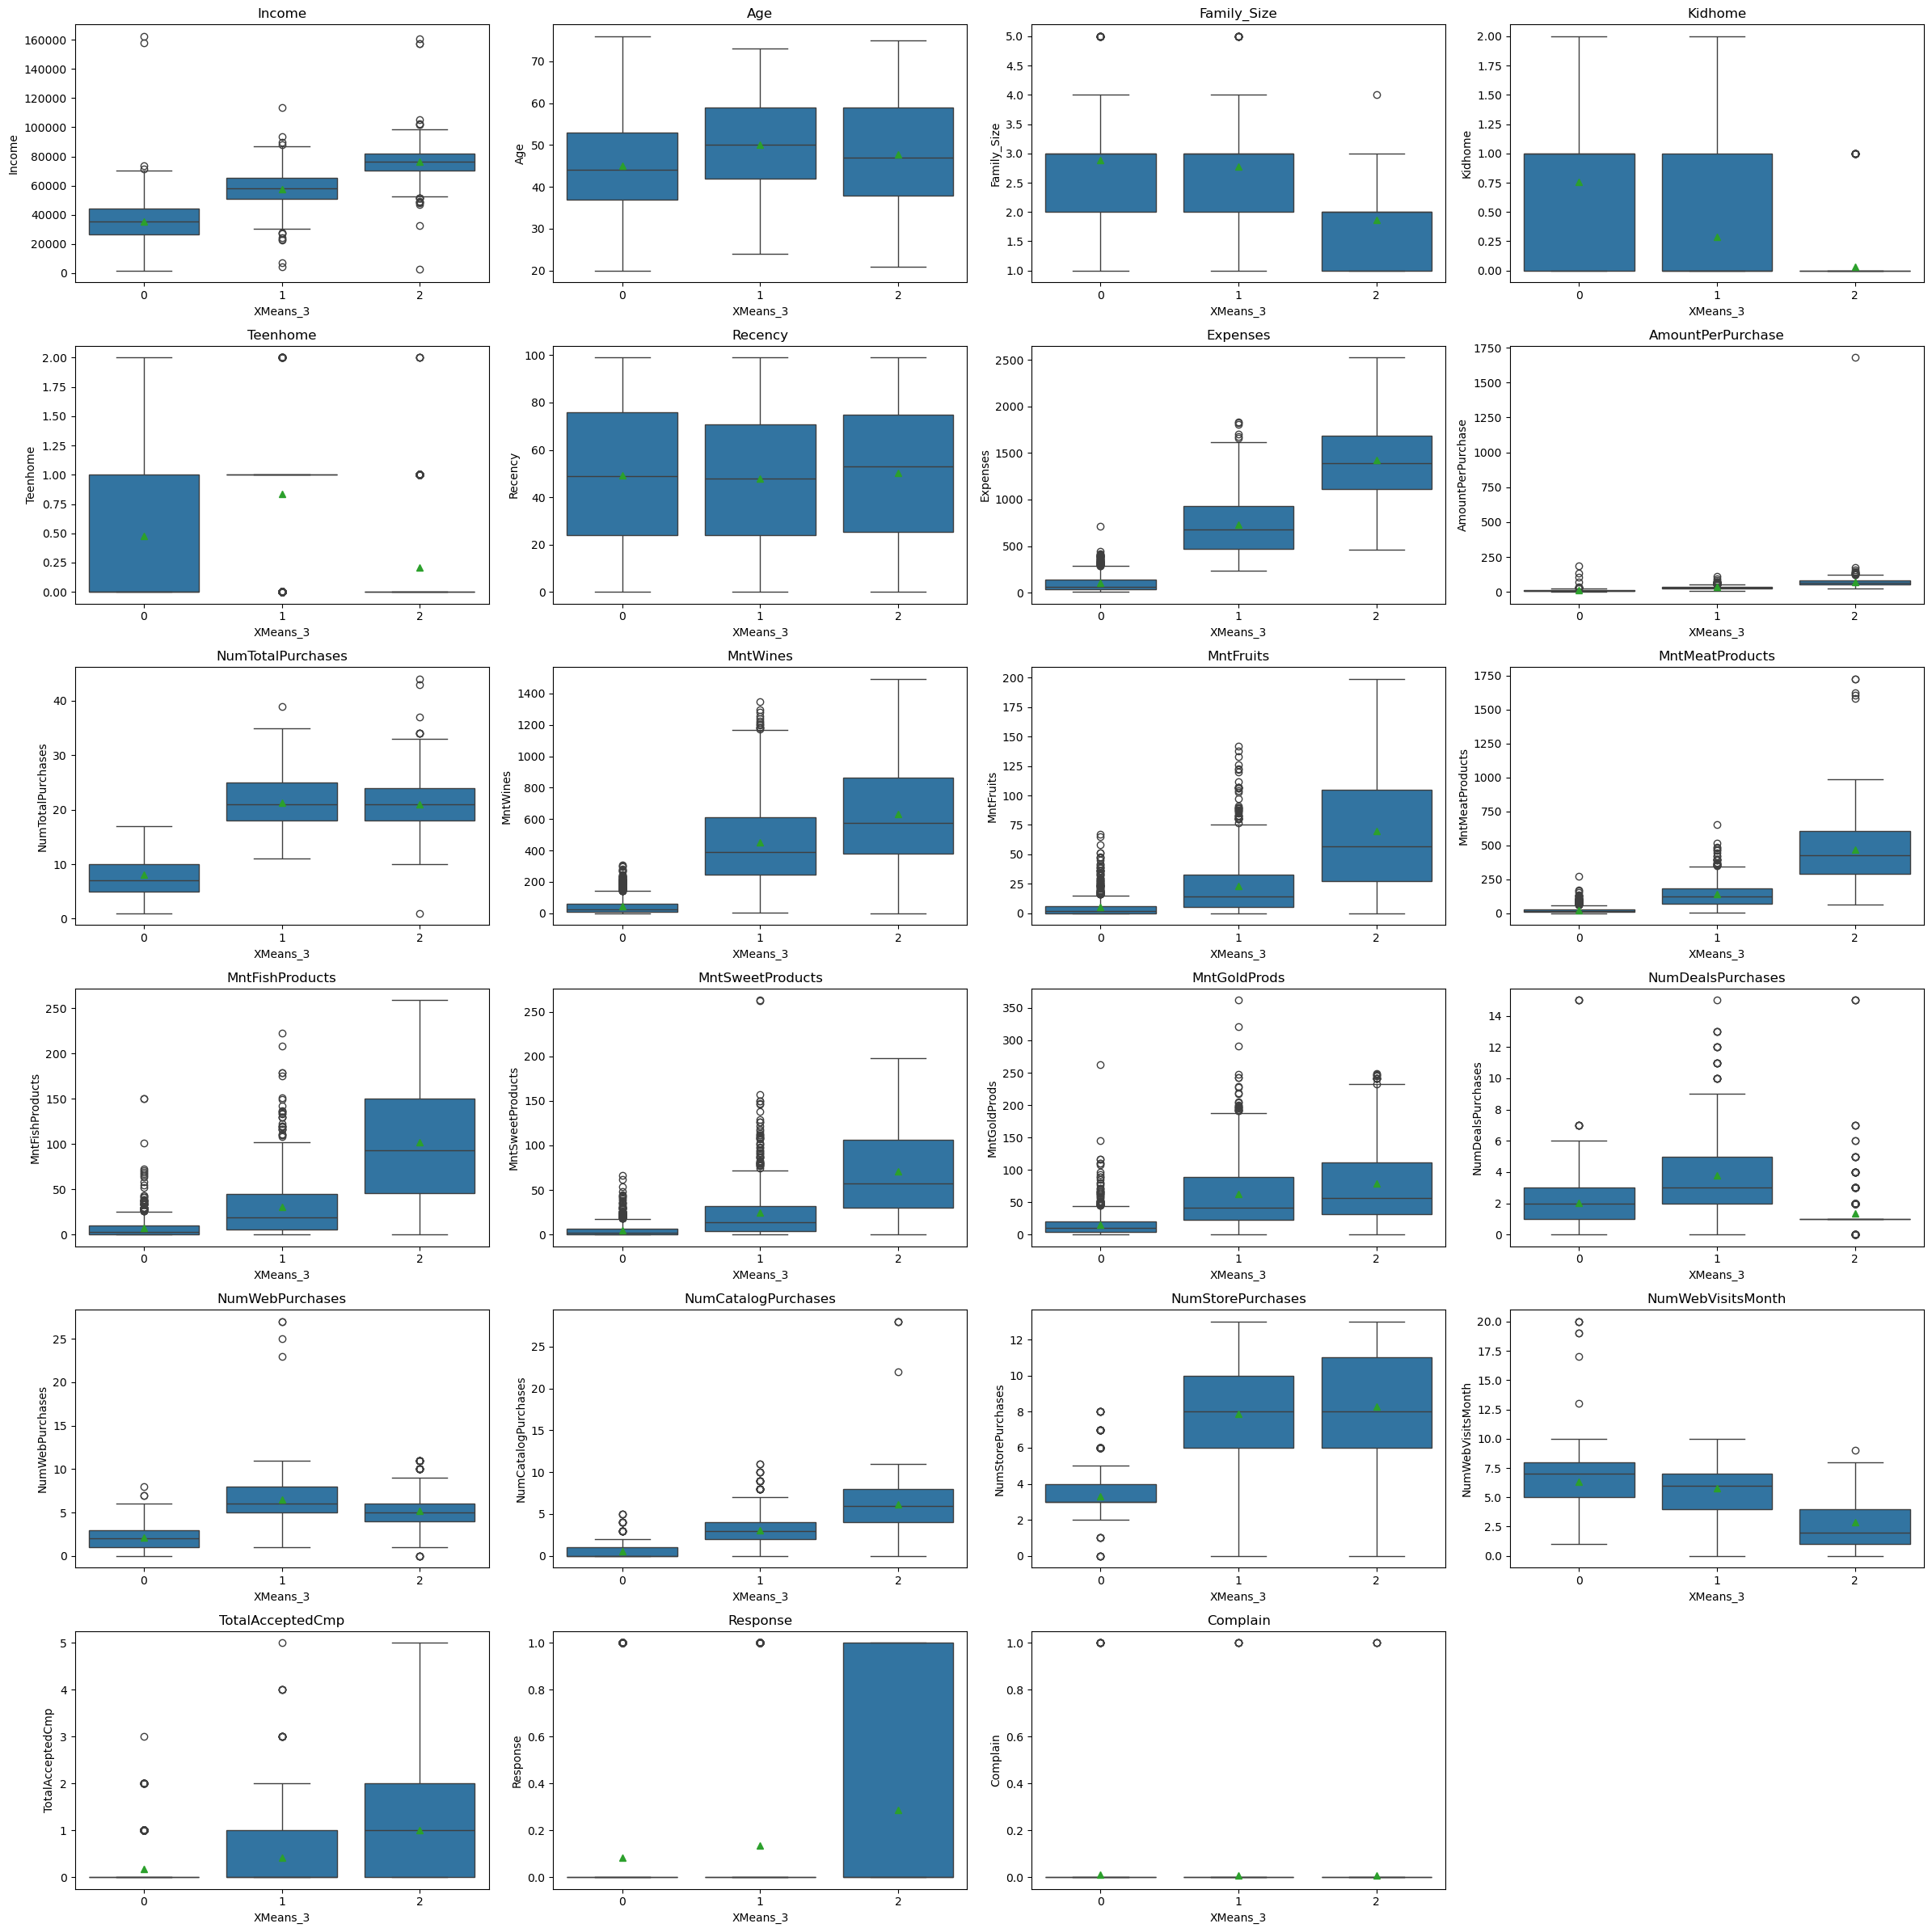

In [61]:
if "XMeans_3" in data_segments.columns:
    plot_cluster_boxplots(
        data_segments,
        "XMeans_3",
        PROFILE_COLUMNS
    )
else:
    print("X-Means boxplots skipped.")


### X-Means Business Insights and Recommendations

X-Means with 3 clusters produced a clear value-based segmentation, similar to K-Means and Bisecting K-Means.

#### Cluster 0: Low-value customers

Cluster 0 has the lowest income, lowest expenses, and weakest spending across most product categories. These customers also have fewer total purchases and lower activity across web, catalog, and store channels.

**Business recommendation:**  
Use low-cost reactivation campaigns, automated emails, and simple discounts. Marketing spend should be controlled because this group has lower customer value.

#### Cluster 1: Medium-value active customers

Cluster 1 has moderate income, moderate expenses, and solid purchase activity. These customers buy more than Cluster 0 but less than Cluster 2, especially through web and store channels.

**Business recommendation:**  
Use cross-selling, upselling, product bundles, and category-specific campaigns to increase basket size and move them toward the high-value segment.

#### Cluster 2: High-value premium customers

Cluster 2 has the highest income, highest expenses, and strongest product spending, especially in wines, meat, fish, sweets, and gold products. These customers also show strong catalog/store purchases and stronger campaign response.

**Business recommendation:**  
Prioritize retention, loyalty rewards, premium bundles, personalized offers, and exclusive campaigns.

### Overall Interpretation

X-Means supports a practical 3-segment structure: low-value, medium-value, and high-value customers. This makes it useful as a robustness check, because it produces a similar business structure to the main K-Means-based models.

In [62]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Keep only PCA component columns as model input
pca_features = get_pca_features(data_pca)

cluster_label_columns = [
    "KMeans_3",
    "HC_3",
    "BisectingKMeans_3",
    "XMeans_3",
    "GMM_2",
    "BayesianGMM_2",
    "BIRCH_2",
    "Spectral_2",
    "DBSCAN",
    "OPTICS"
]

comparison_results = []

for label_col in cluster_label_columns:
    
    if label_col not in data_segments.columns:
        continue
    
    labels = data_segments[label_col].values
    
    # Number of clusters excluding noise label -1
    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
    
    # Noise metrics
    n_noise = int(np.sum(labels == -1))
    noise_pct = n_noise / len(labels) * 100
    
    # Cluster size metrics
    counts = pd.Series(labels).value_counts(normalize=True)
    largest_cluster_pct = counts.max() * 100
    smallest_cluster_pct = counts.min() * 100
    balance_ratio = smallest_cluster_pct / largest_cluster_pct
    
    # Internal validation metrics
    if n_clusters > 1:
        silhouette = silhouette_score(pca_features, labels)
        calinski = calinski_harabasz_score(pca_features, labels)
        davies = davies_bouldin_score(pca_features, labels)
    else:
        silhouette = np.nan
        calinski = np.nan
        davies = np.nan
    
    comparison_results.append({
        "model": label_col,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "noise_pct": noise_pct,
        "largest_cluster_pct": largest_cluster_pct,
        "smallest_cluster_pct": smallest_cluster_pct,
        "balance_ratio": balance_ratio,
        "silhouette": silhouette,
        "calinski_harabasz": calinski,
        "davies_bouldin": davies
    })

scientific_comparison = pd.DataFrame(comparison_results)

scientific_comparison.round(3)

,model,n_clusters,n_noise,noise_pct,largest_cluster_pct,smallest_cluster_pct,balance_ratio,silhouette,calinski_harabasz,davies_bouldin
0,KMeans_3,3,0,0.00,46.69,25.45,0.55,0.27,803.38,1.73
1,HC_3,3,0,0.00,44.18,24.64,0.56,0.22,729.59,1.83
2,BisectingKMeans_3,3,0,0.00,58.74,20.30,0.35,0.29,732.62,2.03
3,XMeans_3,3,0,0.00,47.45,25.22,0.53,0.27,803.23,1.74
4,GMM_2,2,0,0.00,51.21,48.79,0.95,0.30,986.35,1.32
5,BayesianGMM_2,2,0,0.00,50.94,49.06,0.96,0.30,989.22,1.32
6,BIRCH_2,2,0,0.00,72.49,27.51,0.38,0.33,823.40,1.44
7,Spectral_2,2,0,0.00,54.48,45.52,0.84,0.29,974.59,1.29
8,DBSCAN,2,149,6.68,93.10,0.22,0.00,0.32,93.61,2.03
9,OPTICS,1,0,0.00,100.00,100.00,1.00,NaN,NaN,NaN


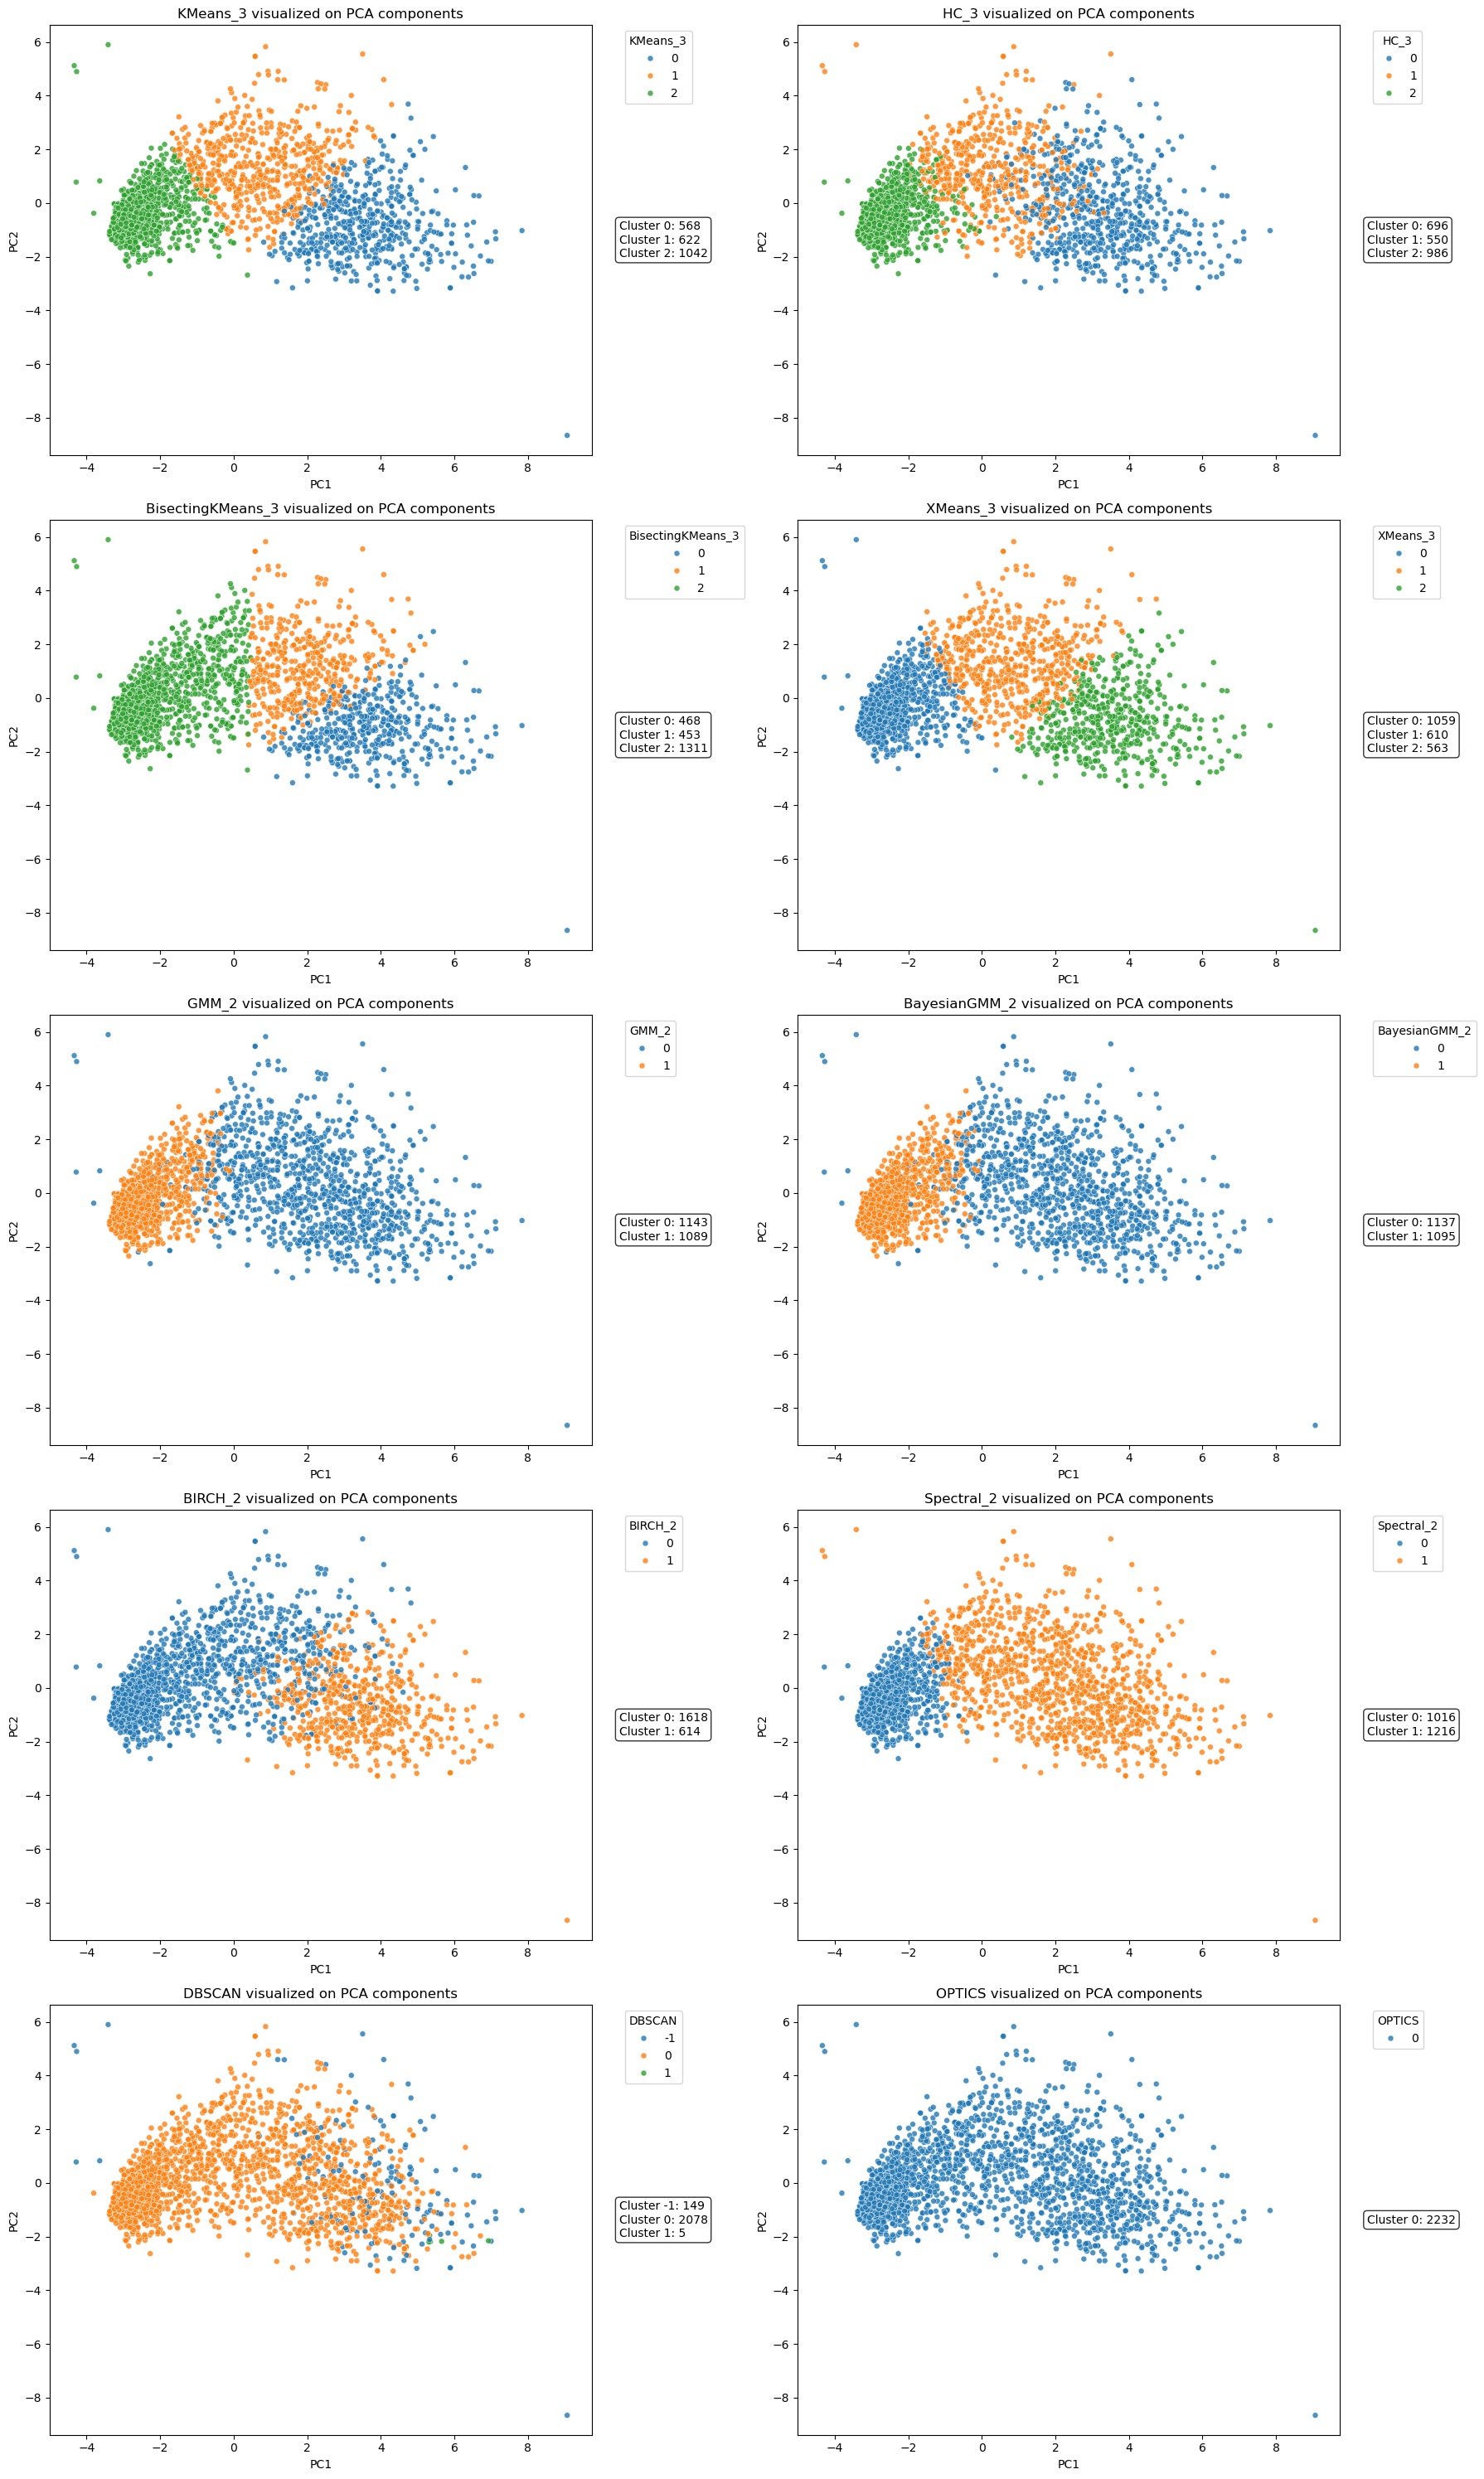

In [63]:
# ------------------------------------------------------------
# Compare all clustering results in one PCA scatterplot grid
# with cluster counts shown next to each graph
# ------------------------------------------------------------

import math
import matplotlib.pyplot as plt
import seaborn as sns

# Cluster label columns to compare
cluster_label_columns = [
    "KMeans_3",
    "HC_3",
    "BisectingKMeans_3",
    "XMeans_3",
    "GMM_2",
    "BayesianGMM_2",
    "BIRCH_2",
    "Spectral_2",
    "DBSCAN",
    "OPTICS"
]

# Keep only columns that actually exist
cluster_label_columns = [
    col for col in cluster_label_columns 
    if col in data_pca.columns
]

# Detect PCA component column names
pca_cols = get_pca_features(data_pca).columns.tolist()

pc1 = pca_cols[0]
pc2 = pca_cols[1]

# Plot settings
n_cols = 2
n_rows = math.ceil(len(cluster_label_columns) / n_cols)

plt.figure(figsize=(18, 6 * n_rows))

for i, label_col in enumerate(cluster_label_columns):
    ax = plt.subplot(n_rows, n_cols, i + 1)
    
    sns.scatterplot(
        data=data_pca,
        x=pc1,
        y=pc2,
        hue=label_col,
        palette="tab10",
        s=25,
        alpha=0.8,
        ax=ax
    )
    
    ax.set_title(f"{label_col} visualized on PCA components")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    
    # Cluster counts
    cluster_counts = data_pca[label_col].value_counts().sort_index()
    count_text = "\n".join([
        f"Cluster {cluster}: {count}"
        for cluster, count in cluster_counts.items()
    ])
    
    # Add text box next to plot
    ax.text(
        1.05,
        0.5,
        count_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="center",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
    )
    
    # Move legend below the count box
    ax.legend(
        title=label_col,
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

plt.tight_layout()
plt.show()

### Final Model Selection

All fitted models were compared using internal validation metrics, cluster size balance, PCA scatterplots, and profiling tables.

The 2-cluster models, including GMM, Bayesian GMM, BIRCH, and Spectral Clustering, gave strong statistical results. In the PCA plots, these models mostly separate customers into a broad low-value and high-value split. This is useful, but it is too general for campaign planning because it does not separate the middle customer group.

The 3-cluster models gave a more practical segmentation. K-Means, Bisecting K-Means, X-Means, and Ward hierarchical clustering all produced a low / medium / high customer value structure. This was more useful because each group can be linked to a different action: reactivation, growth, or retention.

DBSCAN and OPTICS were not selected. DBSCAN created one dominant cluster with noise and a very small extra group. OPTICS assigned all customers to one cluster, so it did not create a useful segmentation.

The final selected model is **K-Means with 3 clusters**. It was selected because it gives acceptable metrics, balanced enough clusters, clear PCA separation, simple interpretation, and an easy monthly scoring process.


In [64]:
# ------------------------------------------------------------
# Create final segmentation dataset
# ------------------------------------------------------------

FINAL_MODEL = "KMeans_3"

final_data = data_segments.copy()
final_data["segment"] = final_data[FINAL_MODEL]

final_profile = profile_clusters(final_data, "segment")

final_profile.round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Kids,Status,Family_Size,Expenses,NumTotalPurchases,TotalAcceptedCmp,Engaged_in_days,AmountPerPurchase,KMeans_3,HC_3,HC_Average_3,DBSCAN,GMM_2,BisectingKMeans_3,BayesianGMM_2,OPTICS,BIRCH_2,Spectral_2,XMeans_3,customer_count
segment,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,"5,635.76","1,968.18","76,349.11",0.04,0.21,50.40,632.33,69.38,466.46,101.73,70.82,78.47,1.36,5.19,6.12,8.30,2.89,0.08,0.14,0.26,0.21,0.03,0.01,0.29,47.82,0.25,1.62,1.87,"1,419.19",20.98,1.02,551.03,73.24,0.00,0.05,0.02,-0.20,0.00,0.18,0.00,0.00,0.91,1.00,1.99,568
1,"5,485.48","1,965.95","57,184.02",0.30,0.84,47.82,443.19,22.66,136.03,29.76,24.07,61.16,3.81,6.44,3.04,7.79,5.81,0.07,0.12,0.02,0.04,0.01,0.01,0.14,50.05,1.14,1.66,2.80,716.87,21.09,0.40,596.95,33.73,1.00,0.78,0.00,-0.04,0.16,1.43,0.17,0.00,0.15,0.98,0.97,622
2,"5,616.26","1,971.06","35,424.26",0.75,0.47,49.14,43.37,5.03,22.85,7.33,5.14,15.10,1.97,2.09,0.56,3.26,6.35,0.07,0.02,0.00,0.00,0.00,0.01,0.08,44.94,1.22,1.65,2.88,98.82,7.89,0.17,500.01,11.32,2.00,1.93,0.00,-0.01,0.95,2.00,0.95,0.00,0.00,0.04,0.00,1042


In [65]:
# ------------------------------------------------------------
# Assign final business segment names
# ------------------------------------------------------------

def assign_value_segment_names(profile: pd.DataFrame) -> dict:
    """Name the three final K-Means clusters using total spend ranking."""

    if "Expenses" not in profile.columns:
        return {int(segment): f"Segment {segment}" for segment in profile.index}

    ordered_segments = profile["Expenses"].sort_values().index.tolist()

    segment_names = {
        int(ordered_segments[0]): "Low-value customers",
        int(ordered_segments[1]): "Medium-value active customers",
        int(ordered_segments[2]): "Premium high-value customers"
    }

    return segment_names


segment_names = assign_value_segment_names(final_profile)

final_data["segment_name"] = final_data["segment"].map(segment_names)

pd.DataFrame.from_dict(
    segment_names,
    orient="index",
    columns=["segment_name"]
).sort_index()


,segment_name
0,Premium high-value customers
1,Medium-value active customers
2,Low-value customers


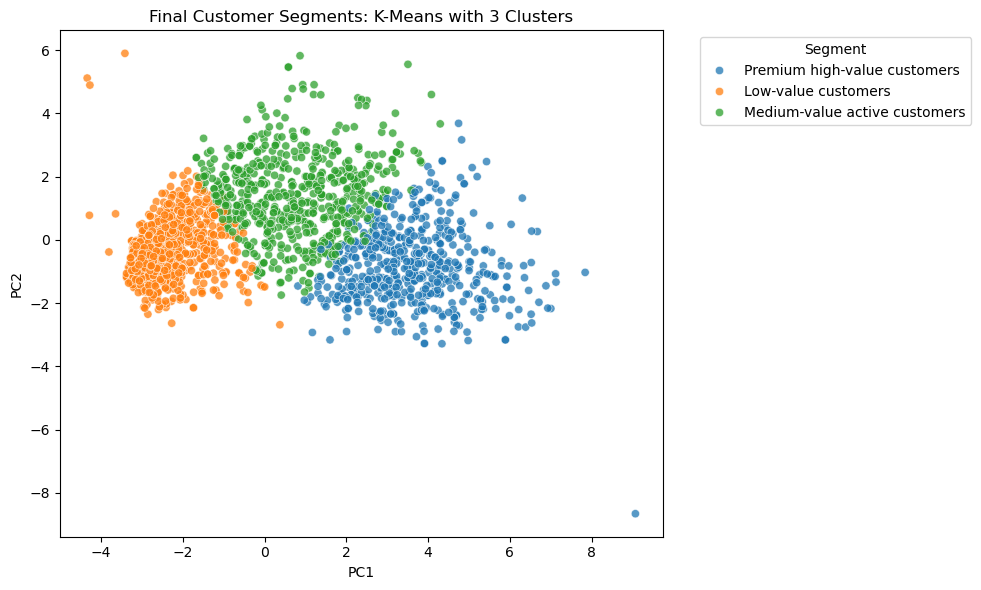

In [66]:
# ------------------------------------------------------------
# Visualize final customer segments on PCA components
# ------------------------------------------------------------

pca_cols = get_pca_features(data_pca).columns.tolist()
pc1, pc2 = pca_cols[0], pca_cols[1]

pca_plot_data = data_pca[[pc1, pc2]].copy()
pca_plot_data["segment_name"] = final_data["segment_name"]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_plot_data,
    x=pc1,
    y=pc2,
    hue="segment_name",
    palette="tab10",
    alpha=0.75
)

plt.title("Final Customer Segments: K-Means with 3 Clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Segment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


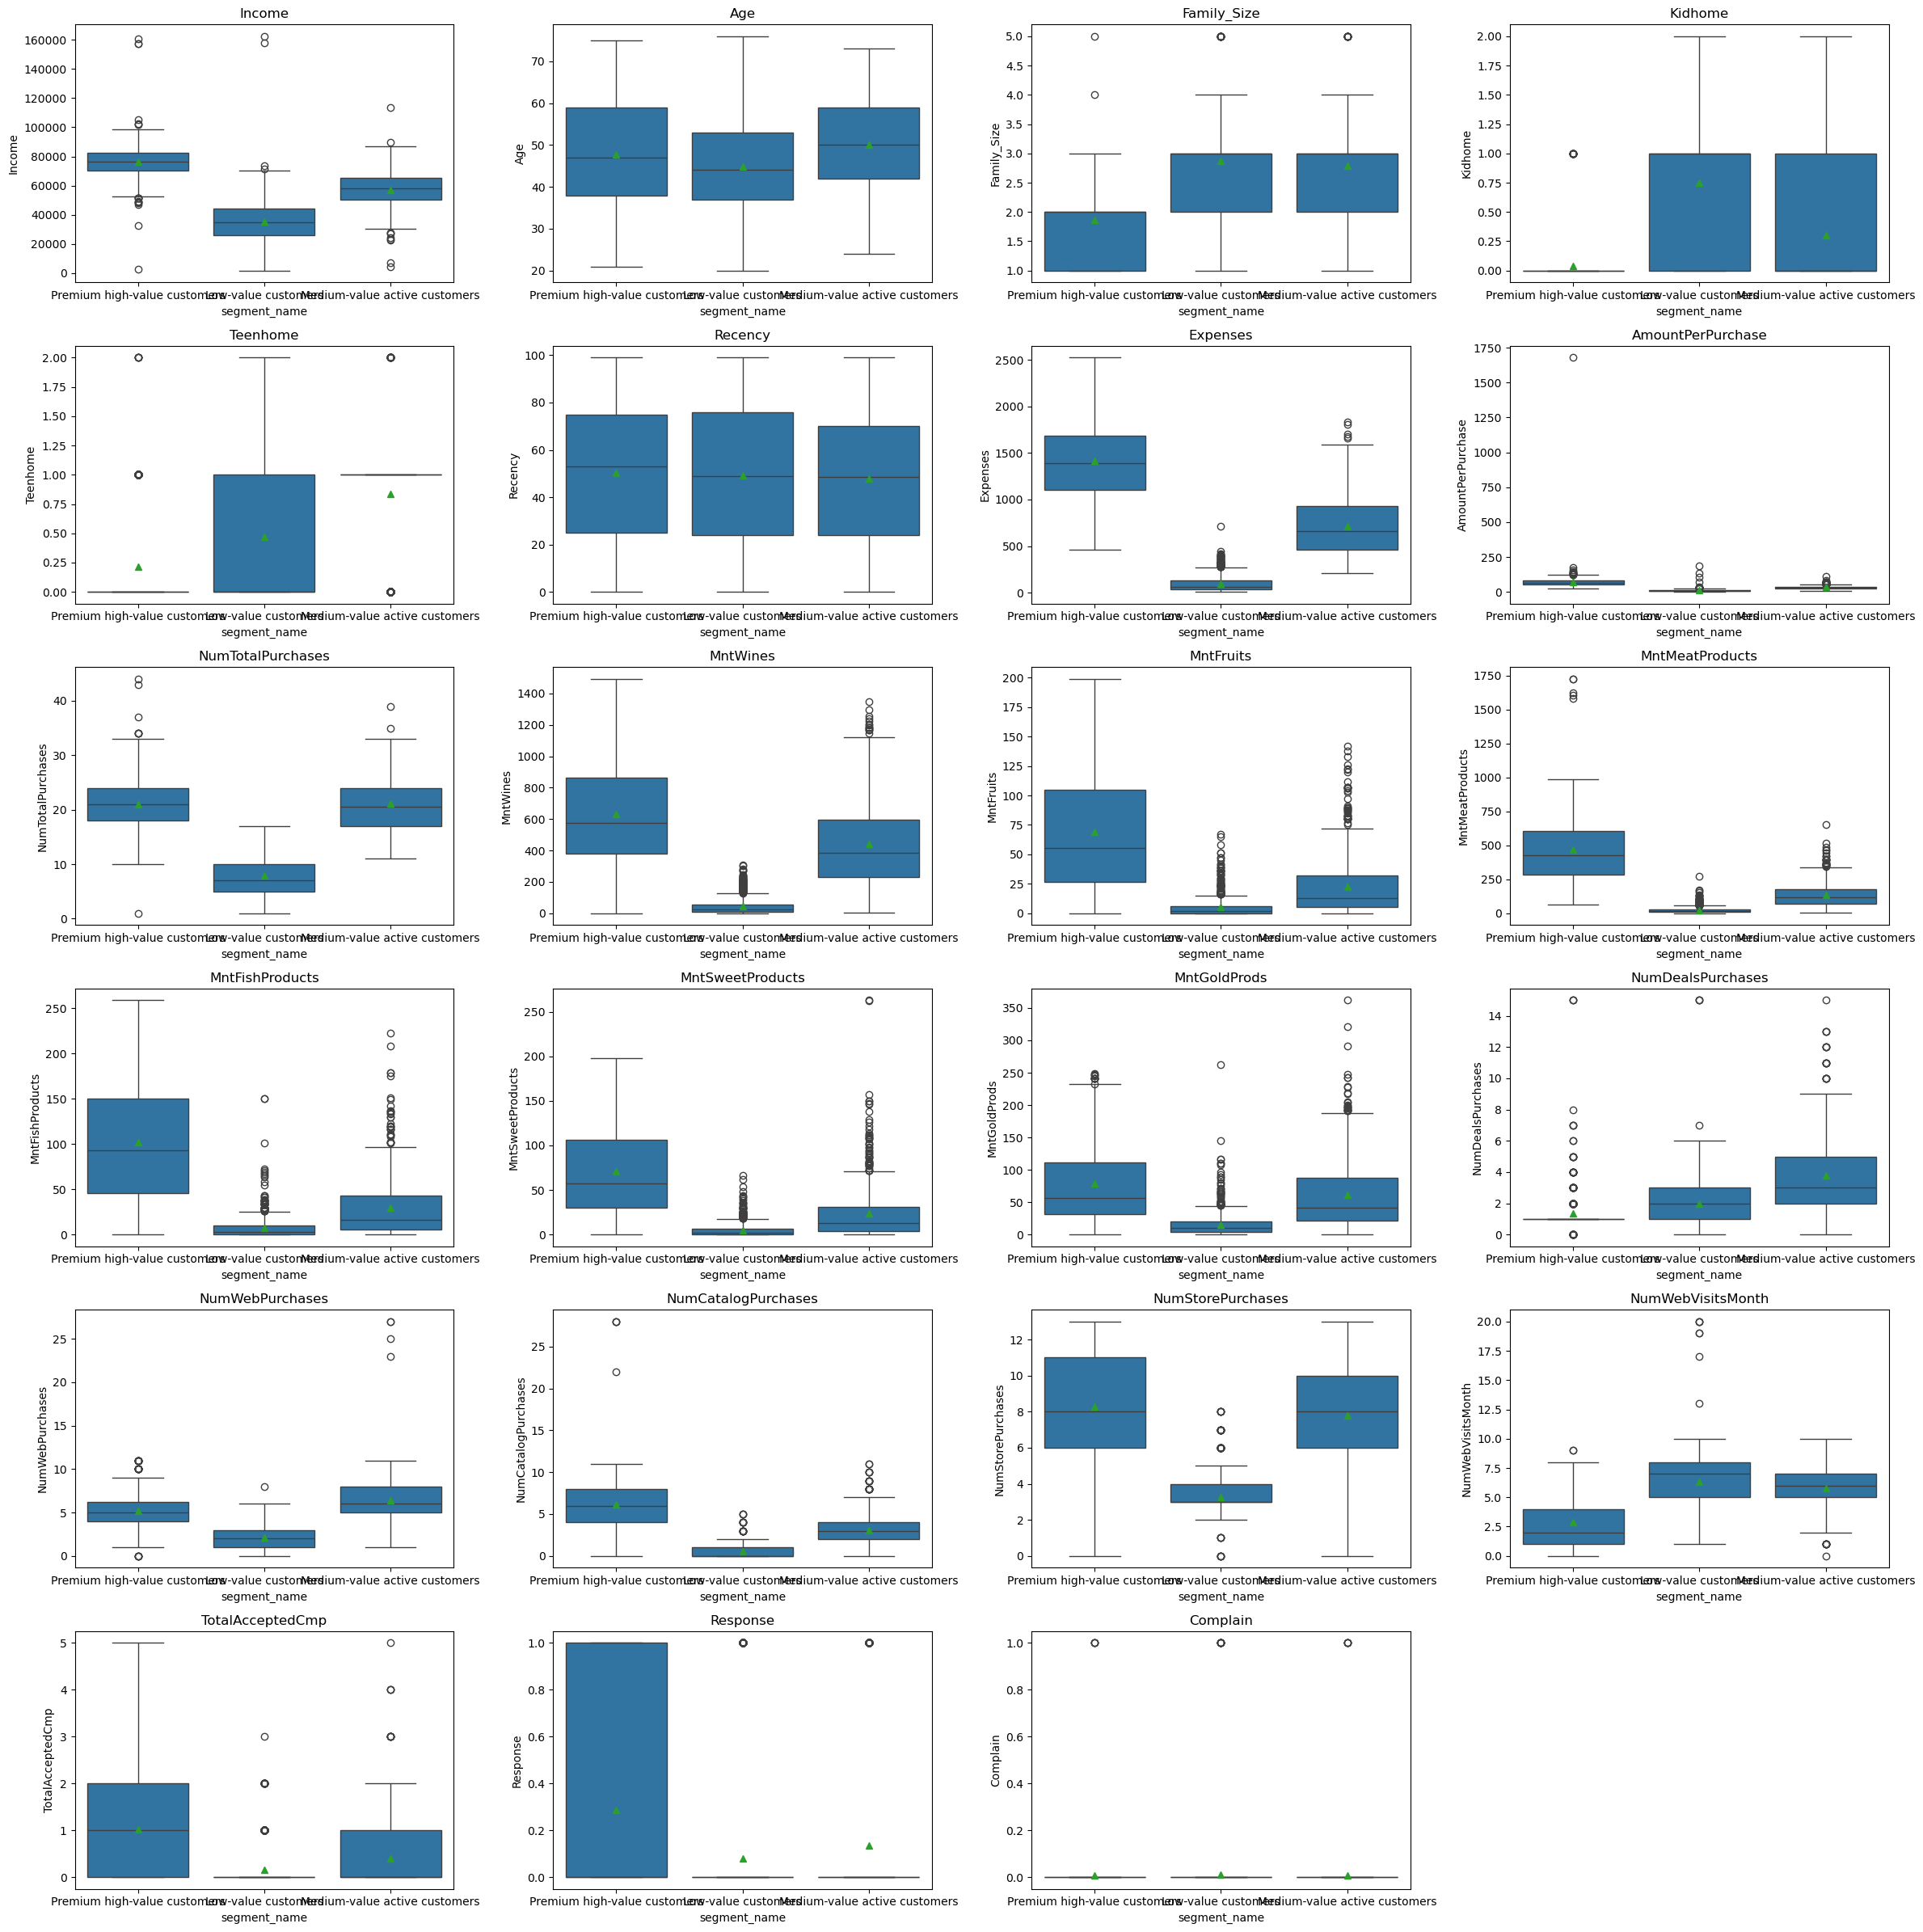

In [67]:
# ------------------------------------------------------------
# Boxplot profiling for final customer segments
# ------------------------------------------------------------

plot_cluster_boxplots(
    final_data,
    "segment_name",
    PROFILE_COLUMNS
)

### 15. Business Interpretation of the Final Segments

The final K-Means 3-cluster solution can be used to move from generic marketing to segment-specific customer management.

Typical business actions by segment:

| Segment type | Business interpretation | Recommended action |
|---|---|---|
| **Low-value customers** | Lowest income, lowest expenses, weak product spending, and fewer purchases across channels | Low-cost reactivation, automated email campaigns, simple discounts |
| **Medium-value active customers** | Moderate income, regular purchase activity, and clear growth potential, but lower total spend than the premium group | Cross-selling, upselling, product bundles, and category-specific campaigns |
| **Premium high-value customers** | Highest income, highest expenses, strongest product spending, and high activity across store, catalog, and web channels | Retention, loyalty rewards, premium bundles, personalized offers, and churn prevention |

The main business value is better customer targeting, more efficient marketing budget allocation, and clearer customer value management. Low-value customers can be managed with low-cost campaigns, medium-value customers can be targeted for growth, and premium customers can be prioritized for retention.

### 16. Monthly Operational Use

The model can be used every month as a recurring customer segmentation refresh process. New customer behaviour data can be processed using the same pipeline and assigned to the existing K-Means segment structure.

The monthly workflow is:

| Step | Description |
|---|---|
| **1. Refresh customer data** | Update the dataset with the latest transactions, product spend, purchase channels, recency, and campaign activity |
| **2. Recalculate engineered features** | Recreate the same features used during modelling, such as total expenses, total purchases, amount per purchase, and engagement duration |
| **3. Apply the original scaler** | Transform the new data using the scaler fitted during model training |
| **4. Apply the original PCA transformation** | Project the new data into the same PCA feature space used for clustering |
| **5. Assign customer segments** | Use the trained K-Means model to assign each customer to the closest segment centroid |
| **6. Track segment movement** | Compare each customer’s current segment with the previous month’s segment |
| **7. Create campaign lists** | Build targeted campaign lists for low-value, medium-value, and premium customers |
| **8. Measure performance** | Track campaign response, revenue uplift, and customer movement by segment |

Monthly tracking metrics:

| Metric | Purpose |
|---|---|
| **Number of customers per segment** | Monitor segment size and stability |
| **Revenue and spend per segment** | Understand value contribution by segment |
| **Average spend per customer** | Track customer value development |
| **Campaign response rate** | Measure marketing effectiveness by segment |
| **Movement from low-value to medium or premium** | Identify successful customer growth |
| **Premium customers moving toward inactivity** | Detect possible churn or value decline |
| **Reactivated customers** | Measure success of reactivation campaigns |

This turns the model from a one-time analysis into a recurring customer management framework. It can support monthly targeting, budget allocation, customer value monitoring, and campaign performance measurement.

### 17. Final Summary

This notebook built a customer segmentation workflow using unsupervised learning. The analysis focused on customer behaviour: product spend, purchase frequency, purchase channels, recency, campaign response, and customer value.

After cleaning the data, I created customer-level features such as total expenses, total purchases, amount per purchase, family size, engagement duration, and total campaign acceptance. The clustering models were fitted on behavioural variables only. Demographic and campaign variables were kept for profiling so the segments could be interpreted in business terms.

The modelling data was standardized and transformed with PCA. All PCA components were retained, so PCA was used mainly to decorrelate the scaled features and create a consistent model input space.

Several models were tested: K-Means, hierarchical clustering, DBSCAN, GMM, Bayesian GMM, Bisecting K-Means, BIRCH, Spectral Clustering, OPTICS, and X-Means. The models were compared using silhouette score, Calinski-Harabasz score, Davies-Bouldin score, cluster size balance, PCA plots, and segment profiles.

Many 2-cluster models performed well statistically, mainly separating customers into lower-value and higher-value groups. For business use, this was too broad. The 3-cluster models gave a more useful structure by separating customers into low-value, medium-value, and premium high-value customers.

The final selected model is **K-Means with 3 clusters**. It gives a simple, stable, and actionable segmentation that can be used for reactivation, cross-selling, upselling, retention, and monthly customer value monitoring.
